# Projet HMM Crypto — Notebook CRISP-DM (phases 1 à 3)

**Sujet :** modélisation et prédiction des régimes de marché des cryptomonnaies par modèles cachés de Markov (**HMM**).  
**Livrable actuel :** Business Understanding, Data Understanding, Data Preparation. **Aucun HMM ni backtesting** dans ce notebook.  
**Actifs :** BTC-USD et ETH-USD. **Période :** 01/01/2018 au 18/11/2026 inclus. **Fréquence :** journalière.  
**Source :** Yahoo Finance via `yfinance`, déjà collectée dans `data/raw/`.

> **Conventions :** les CSV bruts ne sont jamais modifiés. Nous conservons les mouvements extrêmes du marché ; les lignes techniquement invalides sont **isolées et journalisées**, pas supprimées silencieusement. Les conclusions statistiques sont exploratoires, et les résultats affichés proviennent uniquement des CSV réellement lus lors de l'exécution.

**Mode d'emploi :** lancer les cellules dans l'ordre avec le noyau `C:\HMM_Crypto\.venv\Scripts\python.exe`. Si nécessaire : `python -m pip install ipykernel scipy statsmodels scikit-learn`.

## Phase 1 — Business Understanding (compréhension métier)

### Contexte
Les marchés des cryptomonnaies se caractérisent par des périodes de croissance, de baisse et de forte turbulence. Les seuls prix observés ne donnent pas directement l'état sous-jacent du marché.

### Problématique métier
**Comment identifier et caractériser les régimes cachés (Bullish, Bearish, Panique) de Bitcoin et d'Ethereum afin d'estimer leurs transitions et, ultérieurement, de tester leur utilité pour la décision d'investissement ?**

### Objectifs métier
- Distinguer les phases de marché à partir de signaux financiers observables.
- Étudier les probabilités de transition entre les états.
- Évaluer ultérieurement si l'information sur les régimes améliore la gestion du risque et une stratégie de trading, par rapport à une référence *Buy and Hold*.

### Objectifs analytiques à terme
1. Collecter et documenter les historiques OHLCV (Open, High, Low, Close, Volume).
2. Vérifier la qualité des données ; construire les rendements et indicateurs financiers.
3. Comparer des modèles HMM et le nombre d'états (AIC/BIC, validation chronologique).
4. Évaluer la stabilité des régimes et éviter toute fuite d'informations futures lors du backtesting.

### Critères de succès de **ce** livrable (phases 1 à 3)
- Sources, unités, période et fréquence explicitées.
- Anomalies de dates, doublons, valeurs non finies, incohérences OHLCV et interruptions détectées et quantifiées.
- Données préparées conservant les krachs réels ; opérations reproductibles et auditées.
- Analyses descriptives visuelles et statistiques accompagnées d'interprétations **conditionnelles aux résultats**.
- Pas d'entraînement HMM ou de performance de trading revendiquée ici.

**Périmètre et limite :** deux actifs, observations journalières en USD, source unique Yahoo Finance. Les prix, volumes et événements extrêmes peuvent différer d'autres places de marché : une vérification croisée sera souhaitable par la suite.

## Phase 2 — Data Understanding (compréhension des données)

**Objectif :** explorer et comprendre les sources avant toute décision de nettoyage définitif. Nous inspectons les données originales, les caractéristiques financières, les distributions et les dépendances temporelles.

**Convention méthodologique :** pour analyser les rendements en phase 2, une **vue temporaire en mémoire** est constituée à partir des observations techniquement admissibles : date unique, cours strictement positifs, volumes non négatifs, bougie cohérente et valeurs finies. Elle sert *uniquement* à l'analyse exploratoire, sans écraser les CSV d'origine ni enregistrer les fichiers propres. Les cas écartés de cette vue restent documentés dans le diagnostic ; leur traitement définitif intervient **uniquement en phase 3**. Les rendements ne sont calculés que lorsque deux jours consécutifs sont présents.

Cette distinction évite d'interpréter des données manifestement impossibles tout en conservant une présentation linéaire des phases CRISP-DM.

### Cellule 1 — Configuration et bibliothèques
**Question :** les fichiers et les bibliothèques sont-ils accessibles ?

In [9]:
from pathlib import Path
from IPython.display import display
import os
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

# Recherche de la racine lorsque le notebook est lancé depuis le projet ou notebooks/.
CANDIDATS = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
RACINE = next((p for p in CANDIDATS if (p / "data" / "raw").is_dir()), None)
if RACINE is None:
    raise FileNotFoundError("Dossier data/raw introuvable : ouvrir C:\\HMM_Crypto dans VS Code.")

RAW_DIR = RACINE / "data" / "raw"
PROCESSED_DIR = RACINE / "data" / "processed"
REPORT_DIR = RACINE / "outputs" / "qualite"
FIG_DIR = RACINE / "outputs" / "exploration"

DEBUT = pd.Timestamp("2018-01-01")
FIN = pd.Timestamp("2026-11-18")
DATES_ATTENDUES = pd.date_range(DEBUT, FIN, freq="D")
ACTIFS = {"BTC": "BTC-USD_1d.csv", "ETH": "ETH-USD_1d.csv"}
REQUISES = ["Date", "Open", "High", "Low", "Close", "Volume"]
PRIX = ["Open", "High", "Low", "Close"]

print("Projet :", RACINE)
print("Période :", DEBUT.date(), "→", FIN.date())
print("Jours calendaires attendus :", len(DATES_ATTENDUES))
print("Actifs :", ", ".join(ACTIFS))
REPORT_DIR.mkdir(parents=True, exist_ok=True)


Projet : C:\HMM_Crypto
Période : 2018-01-01 → 2026-11-18
Jours calendaires attendus : 3244
Actifs : BTC, ETH


### Cellule 2 — Chargement brut et aperçu
**Pourquoi ?** Vérifier que chaque date correspond à une ligne de données et que les colonnes OHLCV attendues sont présentes. `Adj Close` est conservée dans la source, mais notre table de travail utilise `Close`.

**Interprétation attendue :** comparer le nombre de lignes à la couverture journalière demandée et examiner les formats de date, prix et volume.

In [10]:
bruts = {}
for actif, nom_fichier in ACTIFS.items():
    chemin = RAW_DIR / nom_fichier
    if not chemin.exists():
        raise FileNotFoundError(f"Fichier absent : {chemin}. Exécuter la collecte d'abord.")
    df = pd.read_csv(chemin)  # AUCUNE modification de la source
    manquantes = [col for col in REQUISES if col not in df.columns]
    if manquantes:
        raise ValueError(f"{actif} : colonnes obligatoires absentes : {manquantes}")
    bruts[actif] = df
    print(f"\n{actif} : {df.shape[0]:,} lignes, {df.shape[1]} colonnes")
    print("Colonnes :", list(df.columns))
    display(df.head(3))
    display(df.dtypes.rename("Type initial").to_frame())


BTC : 3,244 lignes, 7 colonnes
Colonnes : ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-01,"13,657.20020","13,657.20020","14,112.20020","13,154.70020","14,112.20020",10291200000
1,2018-01-02,"14,982.09961","14,982.09961","15,444.59961","13,163.59961","13,625.00000",16846600192
2,2018-01-03,"15,201.00000","15,201.00000","15,572.79980","14,844.50000","14,978.20020",16871900160


,Type initial
Date,object
Adj Close,float64
Close,float64
High,float64
Low,float64
Open,float64
Volume,int64



ETH : 3,244 lignes, 7 colonnes
Colonnes : ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-01,772.64099,772.64099,782.53003,742.00403,755.75702,2595760128
1,2018-01-02,884.44397,884.44397,914.83002,772.34601,772.34601,5783349760
2,2018-01-03,962.71997,962.71997,974.47101,868.45099,886.00000,5093159936


,Type initial
Date,object
Adj Close,float64
Close,float64
High,float64
Low,float64
Open,float64
Volume,int64


### Cellule 3 — Statistiques initiales et couverture temporelle
**Pourquoi ?** Décrire le volume des données et repérer les valeurs inhabituelles, sans encore décider lesquelles sont erronées.

Les statistiques de prix portent sur les **niveaux de prix**, pas encore sur les rendements. Les prix de BTC et d'ETH n'ont pas la même échelle : leur comparaison directe est limitée.

In [11]:
for actif, brut in bruts.items():
    df = brut.copy()
    dates = pd.to_datetime(df["Date"], errors="coerce", utc=True).dt.tz_convert(None).dt.normalize()
    valeurs = df[REQUISES[1:]].apply(pd.to_numeric, errors="coerce")
    dans_periode = dates.between(DEBUT, FIN)
    print(f"\n=== {actif} : description initiale ===")
    print("Dates lisibles :", int(dates.notna().sum()), "/", len(df))
    print("Lignes dans la période :", int(dans_periode.sum()))
    if dates.notna().any():
        print("Date min/max du fichier :", dates.min().date(), "/", dates.max().date())
    display(valeurs.describe(percentiles=[.01, .25, .50, .75, .99]).T)
    display(valeurs.isna().sum().rename("Valeurs absentes / non numériques").to_frame())
    print("Interprétation : des extrema inhabituels sont des indices à vérifier, pas des erreurs prouvées.")


=== BTC : description initiale ===
Dates lisibles : 3244 / 3244
Lignes dans la période : 3244
Date min/max du fichier : 2018-01-01 / 2026-11-18


,count,mean,std,min,1%,25%,50%,75%,99%,max
Open,"3,244.00000","40,896.31368","32,598.52965","3,236.27466","3,616.17247","10,125.48364","30,702.64941","64,419.77539","117,476.06945","124,752.14062"
High,"3,244.00000","41,672.58633","33,104.30304","3,275.37793","3,671.90236","10,293.95166","31,637.77246","65,504.72559","118,626.07250","126,198.07031"
Low,"3,244.00000","40,064.67117","32,052.12131","3,191.30347","3,578.78892","9,759.85083","30,127.83008","63,289.27637","116,214.12180","123,196.04688"
Close,"3,244.00000","40,910.15519","32,597.02389","3,236.76172","3,618.57073","10,127.46021","30,736.52539","64,419.16504","117,474.88727","124,752.53125"
Volume,"3,244.00000","30,577,295,858.95808","21,441,288,747.86076","2,923,670,016.00000","3,655,140,181.76000","15,976,582,502.50000","26,731,768,411.50000","40,145,373,647.25000","101,409,751,628.25002","350,967,941,479.00000"


,Valeurs absentes / non numériques
Open,0
High,0
Low,0
Close,0
Volume,0


Interprétation : des extrema inhabituels sont des indices à vérifier, pas des erreurs prouvées.

=== ETH : description initiale ===
Dates lisibles : 3244 / 3244
Lignes dans la période : 3244
Date min/max du fichier : 2018-01-01 / 2026-11-18


,count,mean,std,min,1%,25%,50%,75%,99%,max
Open,"3,244.00000","1,756.78035","1,248.09213",84.27969,112.87748,400.54692,"1,805.86047","2,641.53754","4,514.67129","4,831.08838"
High,"3,244.00000","1,802.85504","1,280.12556",85.34274,117.44226,414.33401,"1,839.43018","2,712.33453","4,625.42533","4,953.73291"
Low,"3,244.00000","1,706.37250","1,213.02175",82.82989,107.21160,388.84624,"1,763.68909","2,565.59619","4,429.07932","4,718.03906"
Close,"3,244.00000","1,756.96564","1,247.78030",84.30830,112.70157,400.36137,"1,806.09595","2,641.71051","4,509.52871","4,831.34863"
Volume,"3,244.00000","15,268,638,475.60635","11,989,290,407.85250","948,488,000.00000","1,332,299,600.00000","6,859,117,837.75000","12,684,407,703.00000","20,081,377,772.25000","56,750,868,647.02002","97,736,621,123.00000"


,Valeurs absentes / non numériques
Open,0
High,0
Low,0
Close,0
Volume,0


Interprétation : des extrema inhabituels sont des indices à vérifier, pas des erreurs prouvées.


type de distributiom 

In [12]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path(r"C:\HMM_Crypto")
RAW = ROOT / "data" / "raw"

btc = pd.read_csv(RAW / "BTC-USD_1d.csv")
eth = pd.read_csv(RAW / "ETH-USD_1d.csv")

# Convertir les dates en datetime
btc["Date"] = pd.to_datetime(btc["Date"], errors="coerce")
eth["Date"] = pd.to_datetime(eth["Date"], errors="coerce")

# Contrôler les dates avant les calculs
for nom, df in [("BTC", btc), ("ETH", eth)]:
    print(f"\n===== {nom} =====")
    print("Dimensions :", df.shape)
    print("Type Date :", df["Date"].dtype)
    print("Dates invalides :", df["Date"].isna().sum())
    print("Dates dupliquées :", df["Date"].duplicated().sum())
    print("Close manquants :", df["Close"].isna().sum())
    print("Close non positifs :", (df["Close"] <= 0).sum())

    assert df["Date"].notna().all()
    assert not df["Date"].duplicated().any()
    assert df["Close"].notna().all()
    assert (df["Close"] > 0).all()

# Trier chronologiquement
btc = btc.sort_values("Date").reset_index(drop=True)
eth = eth.sort_values("Date").reset_index(drop=True)

display(btc.head())
display(eth.head())



===== BTC =====
Dimensions : (3244, 7)
Type Date : datetime64[ns]
Dates invalides : 0
Dates dupliquées : 0
Close manquants : 0
Close non positifs : 0

===== ETH =====
Dimensions : (3244, 7)
Type Date : datetime64[ns]
Dates invalides : 0
Dates dupliquées : 0
Close manquants : 0
Close non positifs : 0


,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-01,"13,657.20020","13,657.20020","14,112.20020","13,154.70020","14,112.20020",10291200000
1,2018-01-02,"14,982.09961","14,982.09961","15,444.59961","13,163.59961","13,625.00000",16846600192
2,2018-01-03,"15,201.00000","15,201.00000","15,572.79980","14,844.50000","14,978.20020",16871900160
3,2018-01-04,"15,599.20020","15,599.20020","15,739.70020","14,522.20020","15,270.70020",21783199744
4,2018-01-05,"17,429.50000","17,429.50000","17,705.19922","15,202.79980","15,477.20020",23840899072


,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-01,772.64099,772.64099,782.53003,742.00403,755.75702,2595760128
1,2018-01-02,884.44397,884.44397,914.83002,772.34601,772.34601,5783349760
2,2018-01-03,962.71997,962.71997,974.47101,868.45099,886.00000,5093159936
3,2018-01-04,980.92200,980.92200,"1,045.07996",946.08600,961.71301,6502859776
4,2018-01-05,997.71997,997.71997,"1,075.39001",956.32501,975.75000,6683149824


In [13]:

import numpy as np
import pandas as pd
from pathlib import Path

# Retrouver le dossier du projet
racine = Path.cwd()

if not (racine / "data" / "processed").exists():
    racine = racine.parent

# Charger les fichiers préparés
btc = pd.read_csv(
    racine / "data" / "processed" / "BTC-USD_1d_clean.csv"
)

eth = pd.read_csv(
    racine / "data" / "processed" / "ETH-USD_1d_clean.csv"
)

# Fonction de création des variables OHLC
def calculer_variables_ohlc(df):

    df = df.copy()

    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    O = df["Open"]
    H = df["High"]
    L = df["Low"]
    C = df["Close"]

    df["R_Open_Open"] = 100 * np.log(O / O.shift(1))
    df["R_High_High"] = 100 * np.log(H / H.shift(1))
    df["R_Low_Low"] = 100 * np.log(L / L.shift(1))
    df["R_Close_Close"] = 100 * np.log(C / C.shift(1))

    df["R_Open_Close"] = 100 * np.log(C / O)

    df["Excursion_Open_High"] = 100 * np.log(H / O)
    df["Excursion_Open_Low"] = 100 * np.log(L / O)

    df["Amplitude_High_Low"] = 100 * np.log(H / L)

    df["Gap"] = 100 * np.log(O / C.shift(1))

    df["Volatilite_Parkinson"] = (
        100 * np.log(H / L) / np.sqrt(4 * np.log(2))
    )

    return df


# Créer les deux variables manquantes
btc_analyse = calculer_variables_ohlc(btc)
eth_analyse = calculer_variables_ohlc(eth)

print("BTC :", btc_analyse.shape)
print("ETH :", eth_analyse.shape)

print("\nVariables financières créées avec succès.")


BTC : (3244, 16)
ETH : (3244, 16)

Variables financières créées avec succès.


Calculer toutes leurs statistiques

In [14]:

variables = [
    "R_Open_Open",
    "R_High_High",
    "R_Low_Low",
    "R_Close_Close",
    "R_Open_Close",
    "Excursion_Open_High",
    "Excursion_Open_Low",
    "Amplitude_High_Low",
    "Gap",
    "Volatilite_Parkinson"
]


def tableau_statistique(df):

    x = df[variables]

    return pd.DataFrame({
        "N": x.count(),
        "Moyenne": x.mean(),
        "Médiane": x.median(),
        "Variance": x.var(),
        "Ecart_type": x.std(),
        "Minimum": x.min(),
        "Maximum": x.max(),
        "Q1": x.quantile(0.25),
        "Q3": x.quantile(0.75),
        "Skewness": x.skew(),
        "Exces_kurtosis": x.kurt()
    }).round(4)


print("STATISTIQUES BITCOIN")
stats_btc = tableau_statistique(btc_analyse)
display(stats_btc)

print("STATISTIQUES ETHEREUM")
stats_eth = tableau_statistique(eth_analyse)
display(stats_eth)


STATISTIQUES BITCOIN


,N,Moyenne,Médiane,Variance,Ecart_type,Minimum,Maximum,Q1,Q3,Skewness,Exces_kurtosis
R_Open_Open,3243,0.04700,0.04310,11.13340,3.33670,-45.55870,17.19990,-1.34420,1.46560,-0.88870,14.05320
R_High_High,3243,0.04710,-0.08070,8.21250,2.86570,-30.61340,17.15630,-1.09610,1.15330,0.01620,8.62460
R_Low_Low,3243,0.04780,0.20690,11.25840,3.35540,-45.26540,22.14560,-1.12020,1.36440,-1.56920,19.09020
R_Close_Close,3243,0.04710,0.04630,11.12780,3.33580,-46.47300,17.18210,-1.35660,1.46020,-0.94020,14.92440
R_Open_Close,3244,0.04350,0.04760,11.10660,3.33270,-46.50060,17.22480,-1.35340,1.45920,-0.94890,15.01110
Excursion_Open_High,3244,2.01620,1.27210,5.10870,2.26020,0.00000,18.79040,0.51540,2.69520,2.43450,8.16190
Excursion_Open_Low,3244,-2.19690,-1.30140,8.01410,2.83090,-48.74740,0.00000,-2.84920,-0.53700,-4.35400,38.28760
Amplitude_High_Low,3244,4.21310,3.41440,10.61050,3.25740,0.35900,48.94300,2.11830,5.28640,3.14170,21.30720
Gap,3243,0.00270,-0.00020,0.01830,0.13520,-0.82060,3.72100,-0.01210,0.01000,12.75090,295.92110
Volatilite_Parkinson,3244,2.53020,2.05060,3.82690,1.95630,0.21560,29.39330,1.27220,3.17480,3.14170,21.30720


STATISTIQUES ETHEREUM


,N,Moyenne,Médiane,Variance,Ecart_type,Minimum,Maximum,Q1,Q3,Skewness,Exces_kurtosis
R_Open_Open,3243,0.02720,0.06080,19.31080,4.39440,-54.70190,23.23140,-1.93610,2.03330,-0.81150,10.97340
R_High_High,3243,0.02610,-0.15120,13.32280,3.65000,-35.06470,24.63270,-1.50810,1.59220,-0.07850,6.84810
R_Low_Low,3243,0.02620,0.30660,19.75130,4.44420,-50.84580,25.15980,-1.45030,1.92180,-1.68860,16.42040
R_Close_Close,3243,0.02560,0.05670,19.23390,4.38560,-55.07320,23.06950,-1.90070,2.02540,-0.82190,11.15390
R_Open_Close,3244,0.01960,0.05350,19.24420,4.38680,-55.00660,23.07250,-1.91810,2.01960,-0.82380,11.11520
Excursion_Open_High,3244,2.64790,1.80560,8.05170,2.83760,0.00000,26.20660,0.68820,3.67580,2.32730,8.22410
Excursion_Open_Low,3244,-2.97420,-1.84470,14.16750,3.76400,-56.02330,0.00000,-3.85340,-0.71460,-4.18350,34.13290
Amplitude_High_Low,3244,5.62210,4.53720,17.19970,4.14730,0.35490,56.57810,3.02050,7.02370,3.20580,21.50160
Gap,3243,0.00670,0.00000,0.03180,0.17840,-2.56320,5.62770,-0.01430,0.01340,12.56490,373.71230
Volatilite_Parkinson,3244,3.37640,2.72480,6.20350,2.49070,0.21310,33.97860,1.81400,4.21820,3.20580,21.50160


Boxplots des quatre évolutions OHLC

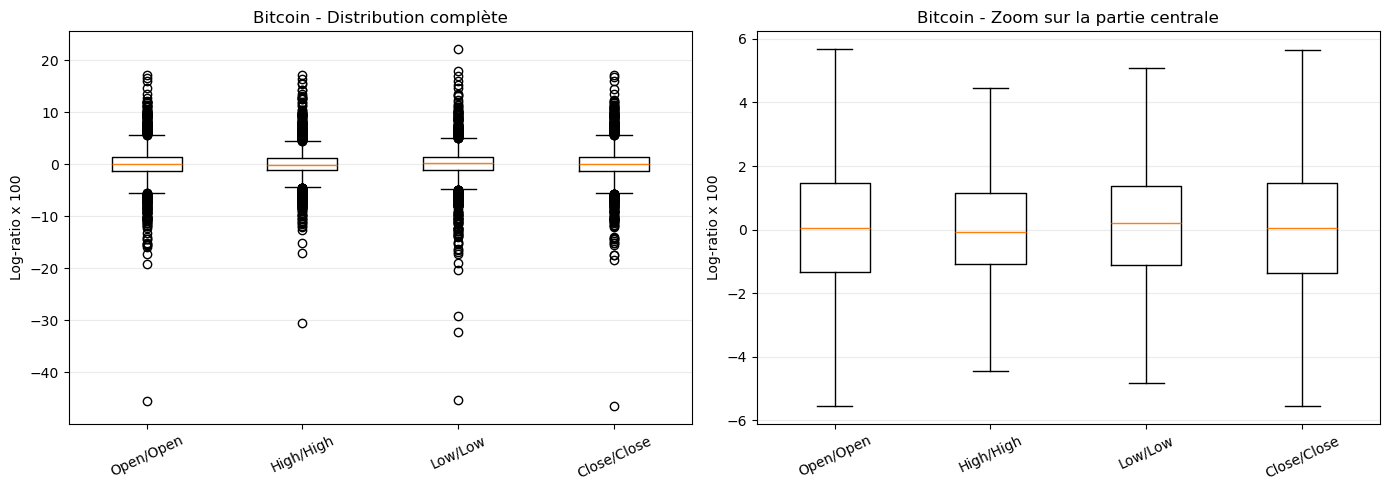

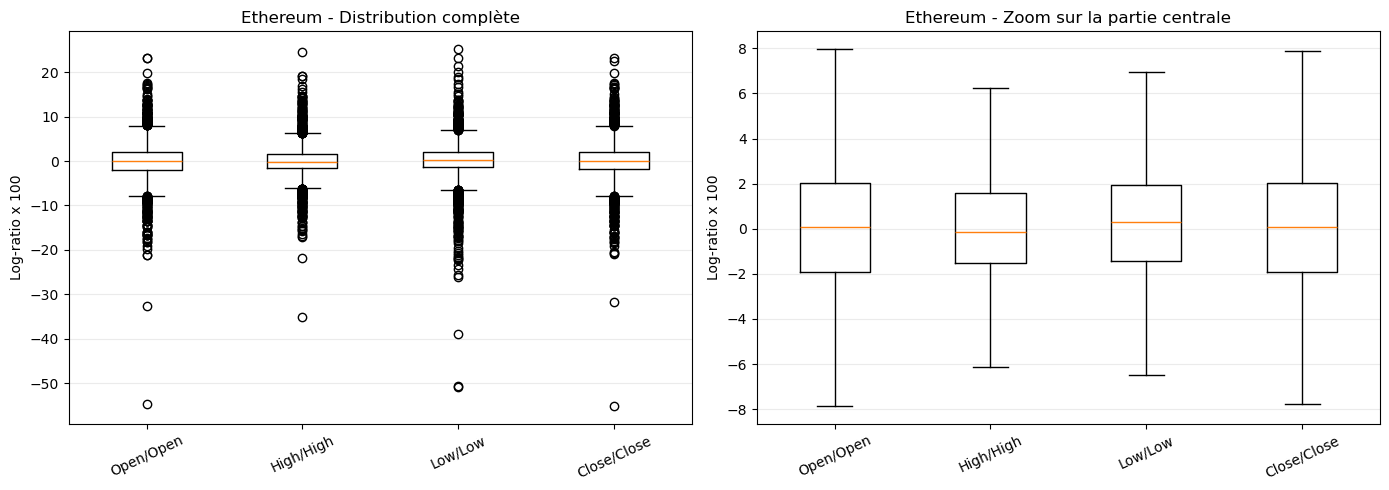

In [15]:

import matplotlib.pyplot as plt

rendements_ohlc = [
    "R_Open_Open",
    "R_High_High",
    "R_Low_Low",
    "R_Close_Close"
]

noms = [
    "Open/Open",
    "High/High",
    "Low/Low",
    "Close/Close"
]

for nom, df in [
    ("Bitcoin", btc_analyse),
    ("Ethereum", eth_analyse)
]:
    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5)
    )

    valeurs = [
        df[col].dropna()
        for col in rendements_ohlc
    ]

    axes[0].boxplot(valeurs, tick_labels=noms)
    axes[0].set_title(
        f"{nom} - Distribution complète"
    )

    axes[1].boxplot(
        valeurs,
        tick_labels=noms,
        showfliers=False
    )

    axes[1].set_title(
        f"{nom} - Zoom sur la partie centrale"
    )

    for ax in axes:
        ax.set_ylabel("Log-ratio x 100")
        ax.grid(axis="y", alpha=0.25)
        ax.tick_params(axis="x", rotation=25)

    plt.tight_layout()
    plt.show()


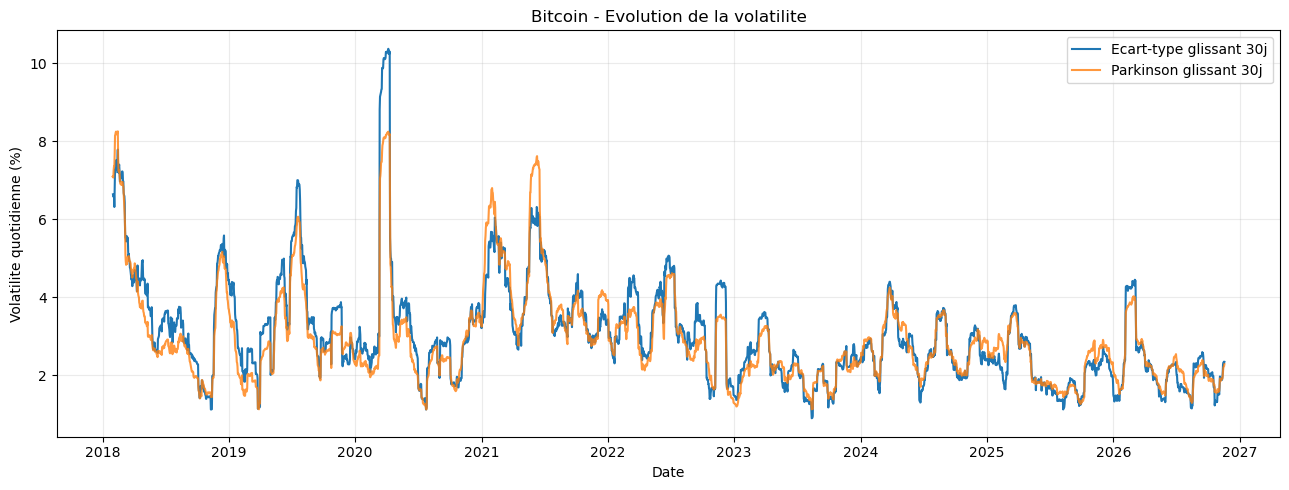


Bitcoin
Ecart-type global : 3.3358
Volatilite 30j mediane : 2.7612
Volatilite 30j maximale : 10.3649
Date du maximum : 2020-04-06


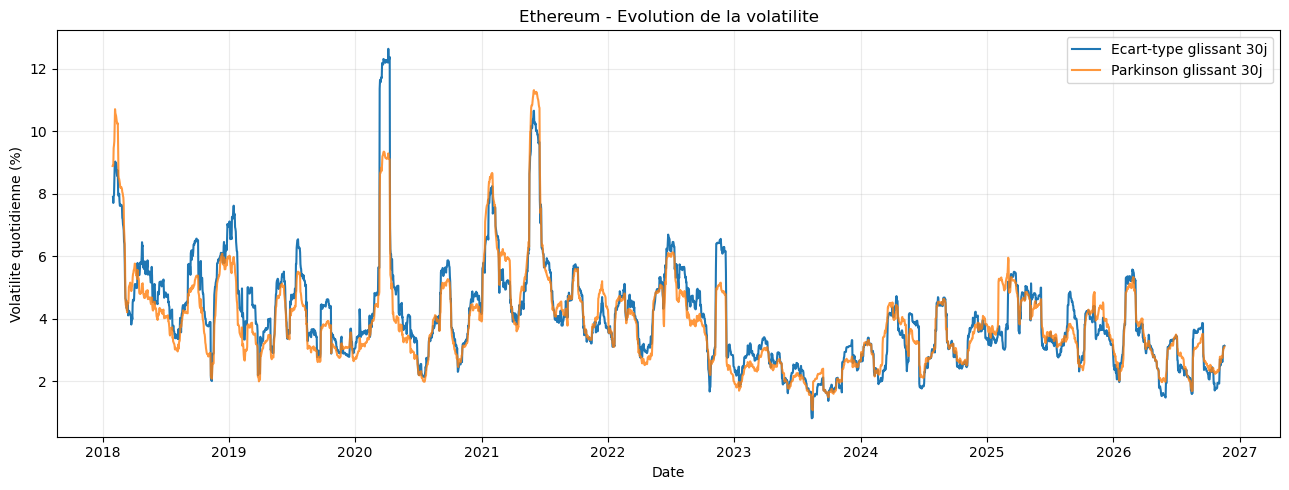


Ethereum
Ecart-type global : 4.3856
Volatilite 30j mediane : 3.7397
Volatilite 30j maximale : 12.6367
Date du maximum : 2020-04-06


In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for nom, df in [
    ("Bitcoin", btc_analyse),
    ("Ethereum", eth_analyse)
]:
    df = df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").set_index("Date")

    # Rendements logarithmiques x 100
    r = df["R_Close_Close"]

    # Ecart-type glissant sur 30 jours
    volatilite_30 = r.rolling(
        window=30,
        min_periods=30
    ).std()

    # Estimation de Parkinson sur 30 jours
    log_high_low = np.log(df["High"] / df["Low"])

    parkinson_30 = 100 * np.sqrt(
        log_high_low.pow(2).rolling(
            window=30,
            min_periods=30
        ).mean() / (4 * np.log(2))
    )

    plt.figure(figsize=(13, 5))

    plt.plot(
        volatilite_30,
        label="Ecart-type glissant 30j"
    )

    plt.plot(
        parkinson_30,
        label="Parkinson glissant 30j",
        alpha=0.8
    )

    plt.title(f"{nom} - Evolution de la volatilite")
    plt.xlabel("Date")
    plt.ylabel("Volatilite quotidienne (%)")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(f"\n{nom}")
    print("Ecart-type global :", round(r.std(), 4))
    print(
        "Volatilite 30j mediane :",
        round(volatilite_30.median(), 4)
    )
    print(
        "Volatilite 30j maximale :",
        round(volatilite_30.max(), 4)
    )
    print(
        "Date du maximum :",
        volatilite_30.idxmax().date()
    )


Bleu — Écart-type des rendements Close/Close

Mesure la dispersion des rendements de clôture sur les 30 derniers jours.




Orange — Estimateur de Parkinson

Estime la volatilité en utilisant les amplitudes High/Low des 30 derniers jours.

Anderson-Darling pour BTC et ETH

In [17]:

import numpy as np
from scipy import stats

for nom, df in [
    ("Bitcoin", btc_analyse),
    ("Ethereum", eth_analyse)
]:
    x = df["R_Close_Close"].dropna().to_numpy()

    resultat = stats.anderson(x, dist="norm")

    print(f"\n===== {nom} =====")
    print("Statistique AD :", round(resultat.statistic, 4))

    for niveau, critique in zip(
        resultat.significance_level,
        resultat.critical_values
    ):
        decision = (
            "REJET H0"
            if resultat.statistic > critique
            else "NON-REJET H0"
        )

        print(
            f"Seuil {niveau}% | "
            f"Critique = {critique:.4f} | "
            f"{decision}"
        )



===== Bitcoin =====
Statistique AD : 65.2526
Seuil 15.0% | Critique = 0.5750 | REJET H0
Seuil 10.0% | Critique = 0.6550 | REJET H0
Seuil 5.0% | Critique = 0.7860 | REJET H0
Seuil 2.5% | Critique = 0.9170 | REJET H0
Seuil 1.0% | Critique = 1.0910 | REJET H0

===== Ethereum =====
Statistique AD : 51.877
Seuil 15.0% | Critique = 0.5750 | REJET H0
Seuil 10.0% | Critique = 0.6550 | REJET H0
Seuil 5.0% | Critique = 0.7860 | REJET H0
Seuil 2.5% | Critique = 0.9170 | REJET H0
Seuil 1.0% | Critique = 1.0910 | REJET H0


Analyse précédente	   Résultat            	            Indication
Boxplots	         Nombreux points extrêmes        	Grandes variations inhabituelles
Skewness	          BTC −0,94 ; ETH −0,82	           Asymétrie négative
Excès de kurtosis	 BTC 14,92 ; ETH 11,15	       Forte contribution des valeurs extrêmes

Or, une loi normale est symétrique, possède une skewness de zéro et un excès de kurtosis de zéro.

Nous pouvions donc soupçonner fortement que la normalité serait rejetée.

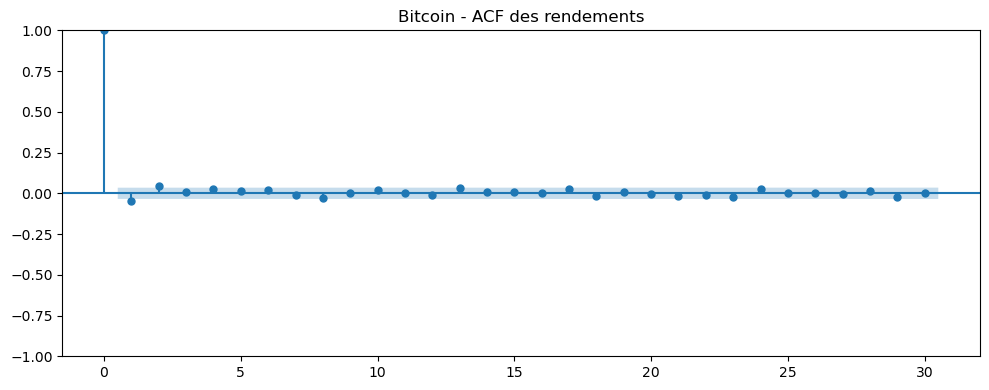

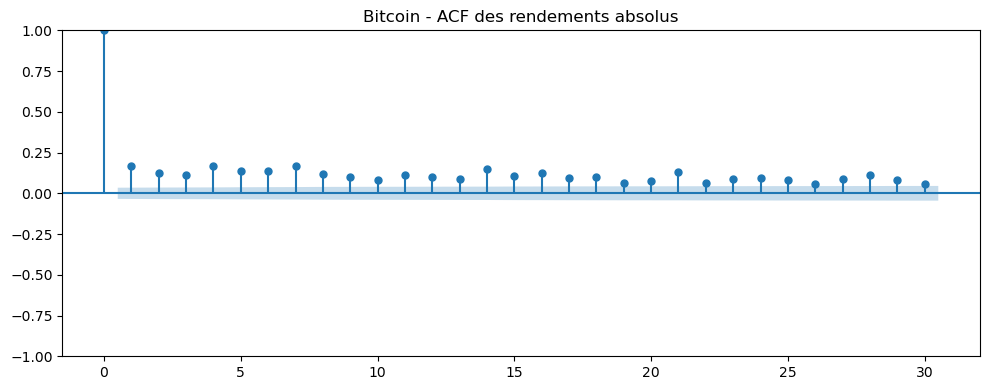

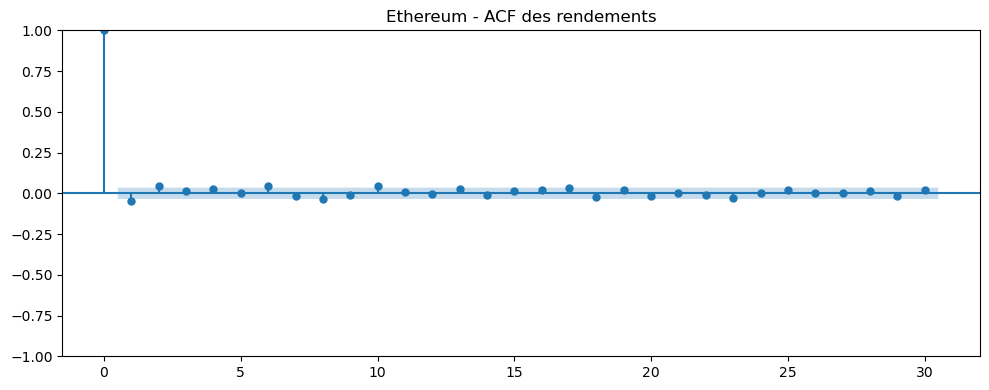

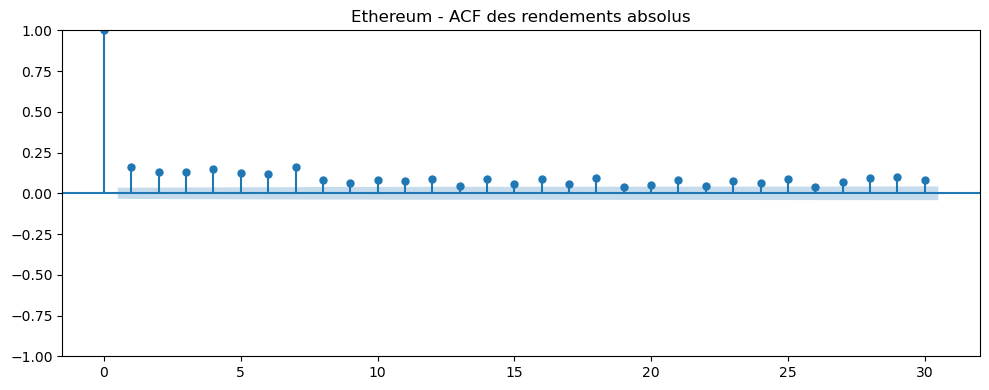

In [18]:

from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

for nom, df in [
    ("Bitcoin", btc_analyse),
    ("Ethereum", eth_analyse)
]:
    r = df["R_Close_Close"].dropna()

    # ACF des rendements
    fig, ax = plt.subplots(figsize=(10, 4))
    plot_acf(r, lags=30, ax=ax)
    ax.set_title(f"{nom} - ACF des rendements")
    plt.tight_layout()
    plt.show()

    # ACF des rendements absolus
    fig, ax = plt.subplots(figsize=(10, 4))
    plot_acf(r.abs(), lags=30, ax=ax)
    ax.set_title(
        f"{nom} - ACF des rendements absolus"
    )
    plt.tight_layout()
    plt.show()


In [19]:

from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

series = {
    "ETH - Prix Close": eth_analyse["Close"],
    "ETH - Rendements Close/Close":
        eth_analyse["R_Close_Close"]
}

resultats_stationnarite = []

for nom, serie in series.items():
    x = pd.to_numeric(
        serie, errors="coerce"
    ).dropna().to_numpy()

    adf_stat, adf_p, *_ = adfuller(
        x, autolag="AIC"
    )

    kpss_stat, kpss_p, *_ = kpss(
        x, regression="c", nlags="auto"
    )

    resultats_stationnarite.append({
        "Serie": nom,
        "ADF_pvalue": adf_p,
        "KPSS_pvalue": kpss_p,
        "ADF_rejet_racine_unitaire": adf_p < 0.05,
        "KPSS_rejet_stationnarite": kpss_p < 0.05
    })

display(
    pd.DataFrame(resultats_stationnarite).round(6)
)


C:\Users\utente\AppData\Local\Temp\ipykernel_2000\957682166.py:21: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(
C:\Users\utente\AppData\Local\Temp\ipykernel_2000\957682166.py:21: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(


,Serie,ADF_pvalue,KPSS_pvalue,ADF_rejet_racine_unitaire,KPSS_rejet_stationnarite
0,ETH - Prix Close,0.31846,0.01000,False,True
1,ETH - Rendements Close/Close,0.00000,0.10000,True,False


Ljung-Box et ARCH-LM

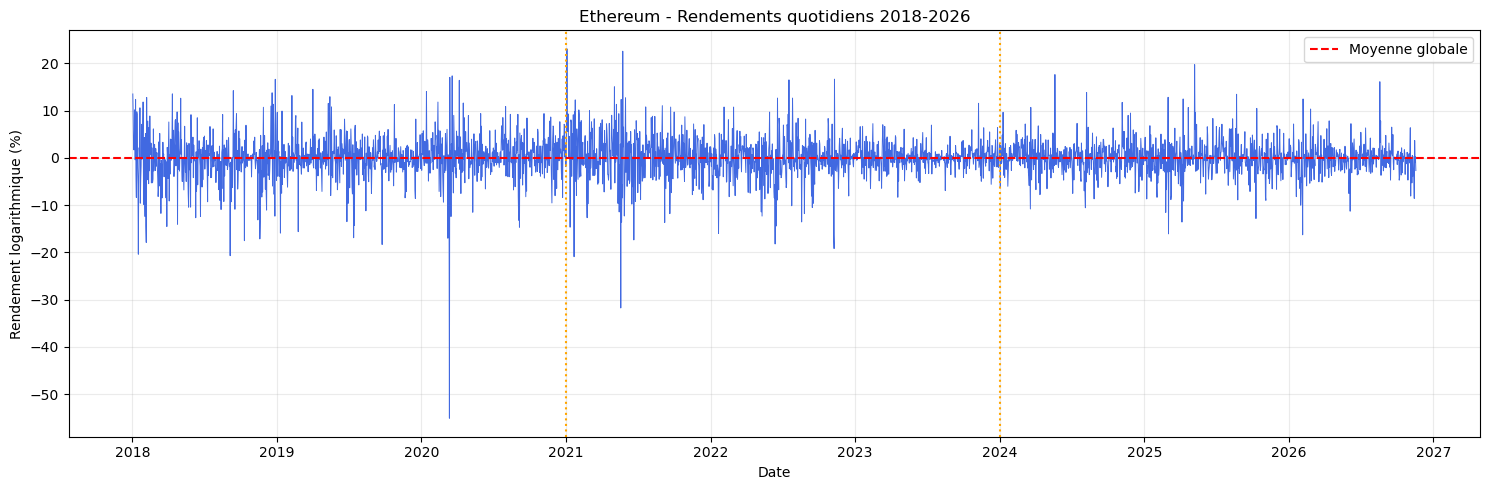

STATIONNARITE DES RENDEMENTS ETH


,Periode,N,Moyenne,Variance,Ecart_type,ADF_pvalue,KPSS_pvalue
0,2018-2020,1095,-0.00421,25.63884,5.06348,0.00000,0.04892
1,2021-2023,1095,0.10310,19.47058,4.41255,0.00000,0.10000
2,2024-2026,1053,-0.02385,12.35392,3.51481,0.00000,0.10000



TEST DE LEVENE
Statistique : 23.9731
p-value : 4.6228313709909686e-11
Dispersion différente entre les sous-périodes


In [28]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from scipy.stats import levene
from statsmodels.tsa.stattools import adfuller, kpss

# Uniquement Ethereum
d = eth_analyse[
    ["Date", "R_Close_Close"]
].copy()

d["Date"] = pd.to_datetime(d["Date"])
d = d.sort_values("Date").dropna()

# Définir les sous-périodes
d["Periode"] = pd.cut(
    d["Date"],
    bins=pd.to_datetime([
        "2017-12-31",
        "2020-12-31",
        "2023-12-31",
        "2026-12-31"
    ]),
    labels=[
        "2018-2020",
        "2021-2023",
        "2024-2026"
    ]
)

# 1. Série temporelle ETH
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    d["Date"],
    d["R_Close_Close"],
    color="royalblue",
    linewidth=0.7
)

ax.axhline(
    d["R_Close_Close"].mean(),
    color="red",
    linestyle="--",
    label="Moyenne globale"
)

for date in ["2021-01-01", "2024-01-01"]:
    ax.axvline(
        pd.Timestamp(date),
        color="orange",
        linestyle=":"
    )

ax.set_title(
    "Ethereum - Rendements quotidiens 2018-2026"
)
ax.set_ylabel("Rendement logarithmique (%)")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

# 2. Stationnarité dans chaque sous-période
resultats = []
groupes = []

for periode, groupe in d.groupby(
    "Periode", observed=True
):
    x = groupe["R_Close_Close"].to_numpy()
    groupes.append(x)

    adf_p = adfuller(
        x, autolag="AIC"
    )[1]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_p = kpss(
            x, regression="c", nlags="auto"
        )[1]

    resultats.append({
        "Periode": str(periode),
        "N": len(x),
        "Moyenne": np.mean(x),
        "Variance": np.var(x, ddof=1),
        "Ecart_type": np.std(x, ddof=1),
        "ADF_pvalue": adf_p,
        "KPSS_pvalue": kpss_p
    })

tableau_eth = pd.DataFrame(resultats)

print("STATIONNARITE DES RENDEMENTS ETH")
display(tableau_eth.round(5))

# 3. Comparaison des dispersions
stat, p = levene(
    *groupes,
    center="median"
)

print("\nTEST DE LEVENE")
print("Statistique :", round(stat, 4))
print("p-value :", p)

if p < 0.05:
    print(
        "Dispersion différente entre les sous-périodes"
    )
else:
    print(
        "Pas de différence significative détectée"
    )


Rendements quotidiens Ethereum (2018–2026)

La ligne rouge représente la moyenne globale. Les rendements fluctuent de part et d'autre de cette ligne sans présenter de tendance persistante à la hausse ou à la baisse.

C'est compatible avec une moyenne relativement stable.

Deuxième observation : la dispersion change selon les périodes.

On distingue notamment :
- 2018–2020 : de nombreuses fluctuations importantes, avec un épisode extrême en 2020 proche de −55 % en rendement logarithmique.
- 2021–2022 : plusieurs variations positives et négatives importantes.
- 2023 : une période visuellement plus calme.
- 2024–2026 : de nouvelles fluctuations importantes, mais moins concentrées que lors de certains épisodes antérieurs.
Cela suggère un phénomène de volatility clustering : les périodes de fortes fluctuations ont tendance à se regrouper.

A. Étude de la moyenne
Les trois moyennes sont relativement proches de zéro comparativement aux écarts-types.

Cela suggère que le rendement ETH fluctue autour d'un niveau moyen faible, sans tendance persistante évidente

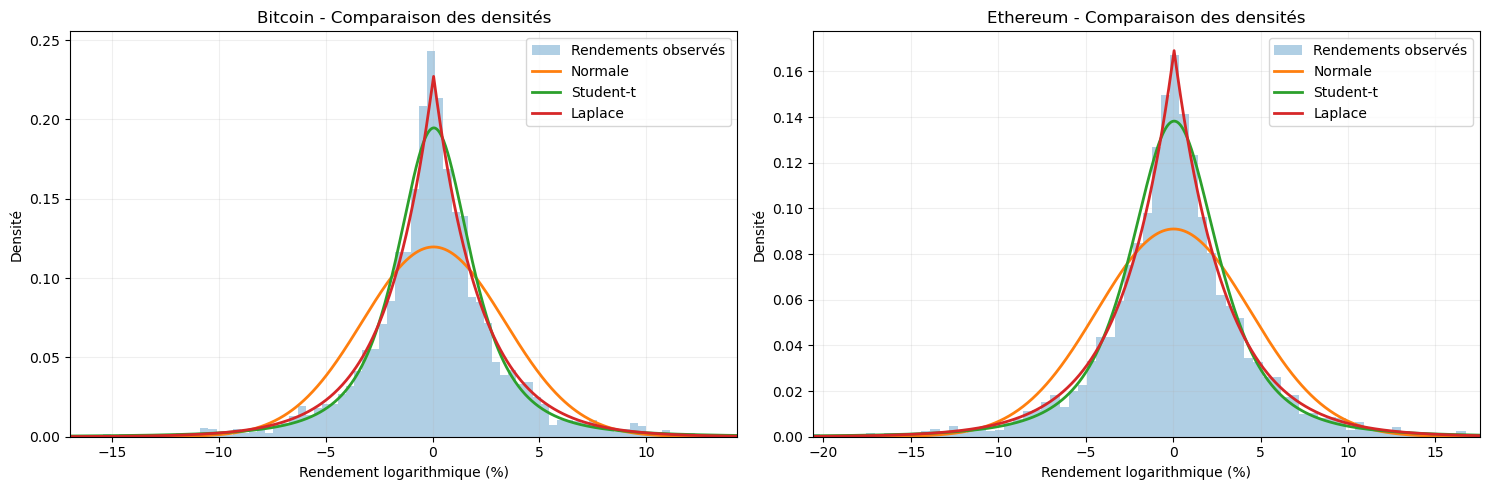

Comparaison AIC :


,Actif,Loi,AIC
0,Bitcoin,Normale,"17,020.07000"
1,Bitcoin,Student-t,"16,118.14000"
2,Bitcoin,Laplace,"16,091.95000"
3,Ethereum,Normale,"18,794.72000"
4,Ethereum,Student-t,"18,046.82000"
5,Ethereum,Laplace,"18,016.03000"


In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

lois = {
    "Normale": stats.norm,
    "Student-t": stats.t,
    "Laplace": stats.laplace,
}

resultats = []

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, (nom, df) in zip(
    axes,
    [("Bitcoin", btc_analyse), ("Ethereum", eth_analyse)]
):
    x = df["R_Close_Close"].dropna().to_numpy()

    # Histogramme empirique
    ax.hist(
        x,
        bins="fd",
        density=True,
        alpha=0.35,
        label="Rendements observés"
    )

    # Axe pour les courbes théoriques
    grille = np.linspace(
        np.quantile(x, 0.001),
        np.quantile(x, 0.999),
        1000
    )

    for nom_loi, loi in lois.items():

        # Estimation des paramètres par maximum
        # de vraisemblance
        parametres = loi.fit(x)

        # Densité théorique ajustée
        densite = loi.pdf(grille, *parametres)

        ax.plot(
            grille,
            densite,
            linewidth=2,
            label=nom_loi
        )

        # Log-vraisemblance et critère AIC
        log_vraisemblance = np.sum(
            loi.logpdf(x, *parametres)
        )

        k = len(parametres)
        aic = 2 * k - 2 * log_vraisemblance

        resultats.append({
            "Actif": nom,
            "Loi": nom_loi,
            "AIC": aic
        })

    ax.set_xlim(
        np.quantile(x, 0.001),
        np.quantile(x, 0.999)
    )

    ax.set_title(f"{nom} - Comparaison des densités")
    ax.set_xlabel("Rendement logarithmique (%)")
    ax.set_ylabel("Densité")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

tableau = pd.DataFrame(resultats)
print("Comparaison AIC :")
display(tableau.round(2))


calculer tous les mouvements OHLC

Construire les comptages mensuels

In [21]:

import pandas as pd

comptages = {}

for nom, df in [
    ("Bitcoin", btc_analyse),
    ("Ethereum", eth_analyse)
]:
    d = df[["Date", "R_Close_Close"]].copy()
    d["Date"] = pd.to_datetime(d["Date"])
    d = d.dropna(subset=["R_Close_Close"])

    d["Mois"] = d["Date"].dt.to_period("M")

    # Nombre de journées avec une forte baisse
    mensuel = d.groupby("Mois").agg(
        Jours_observes=("R_Close_Close", "size"),
        Nombre_crises=(
            "R_Close_Close",
            lambda x: int((x <= -5).sum())
        )
    )

    # Garder les mois complets pour
    # faciliter la comparaison
    mensuel = mensuel.loc[
        mensuel["Jours_observes"]
        == mensuel.index.days_in_month
    ]

    comptages[nom] = mensuel["Nombre_crises"]

    moyenne = comptages[nom].mean()
    variance = comptages[nom].var()

    print(f"\n===== {nom} =====")
    display(mensuel.head(12))

    print("Moyenne mensuelle :", round(moyenne, 3))
    print("Variance :", round(variance, 3))

    if moyenne > 0:
        print(
            "Variance / moyenne :",
            round(variance / moyenne, 3)
        )



===== Bitcoin =====


,Jours_observes,Nombre_crises
Mois,,
2018-02,28,7
2018-03,31,7
2018-04,30,2
2018-05,31,2
2018-06,30,2
2018-07,31,2
2018-08,31,3
2018-09,30,1
2018-10,31,1


Moyenne mensuelle : 1.59
Variance : 3.456
Variance / moyenne : 2.173

===== Ethereum =====


,Jours_observes,Nombre_crises
Mois,,
2018-02,28,8
2018-03,31,8
2018-04,30,2
2018-05,31,4
2018-06,30,5
2018-07,31,2
2018-08,31,6
2018-09,30,6
2018-10,31,1


Moyenne mensuelle : 2.486
Variance : 5.271
Variance / moyenne : 2.121


Classifier les bougies BTC et ETH

In [22]:

import numpy as np
import pandas as pd

SEUIL_BAISSE = -5.0
SEUIL_AMPLITUDE = 8.0

def analyser_bougies(df):

    d = df.copy()
    d["Date"] = pd.to_datetime(d["Date"])
    d = d.sort_values("Date").reset_index(drop=True)

    prix = d[["Open", "High", "Low", "Close"]]

    # Vérifier les données
    assert d["Date"].notna().all()
    assert not d["Date"].duplicated().any()
    assert np.isfinite(prix.to_numpy()).all()
    assert (prix > 0).all().all()
    assert (d["High"] >= prix.max(axis=1)).all()
    assert (d["Low"] <= prix.min(axis=1)).all()

    # Variation entre Open et Close
    d["Corps_pct"] = 100 * np.log(
        d["Close"] / d["Open"]
    )

    # Amplitude entre High et Low
    d["Amplitude_pct"] = 100 * np.log(
        d["High"] / d["Low"]
    )

    # Type de bougie
    d["Type_bougie"] = np.where(
        d["Close"] >= d["Open"],
        "Haussiere",
        "Baissiere"
    )

    # Critères de choc
    d["Forte_baisse"] = (
        d["Corps_pct"] <= SEUIL_BAISSE
    )

    d["Forte_amplitude"] = (
        d["Amplitude_pct"] >= SEUIL_AMPLITUDE
    )

    # Un choc doit satisfaire les deux critères
    d["Choc_baissier"] = (
        d["Forte_baisse"] & d["Forte_amplitude"]
    )

    return d


bougies_btc = analyser_bougies(btc_analyse)
bougies_eth = analyser_bougies(eth_analyse)

for nom, d in [
    ("Bitcoin", bougies_btc),
    ("Ethereum", bougies_eth)
]:
    print(f"\n===== {nom} =====")

    display(d[[
        "Date",
        "Open",
        "High",
        "Low",
        "Close",
        "Corps_pct",
        "Amplitude_pct",
        "Type_bougie",
        "Choc_baissier"
    ]].head(10))

    print("Jours de choc :", int(d["Choc_baissier"].sum()))



===== Bitcoin =====


,Date,Open,High,Low,Close,Corps_pct,Amplitude_pct,Type_bougie,Choc_baissier
0,2018-01-01,"14,112.20020","14,112.20020","13,154.70020","13,657.20020",-3.27728,7.02606,Baissiere,False
1,2018-01-02,"13,625.00000","15,444.59961","13,163.59961","14,982.09961",9.49498,15.98040,Haussiere,False
2,2018-01-03,"14,978.20020","15,572.79980","14,844.50000","15,201.00000",1.47654,4.78964,Haussiere,False
3,2018-01-04,"15,270.70020","15,739.70020","14,522.20020","15,599.20020",2.12837,8.05077,Haussiere,False
4,2018-01-05,"15,477.20020","17,705.19922","15,202.79980","17,429.50000",11.87962,15.23787,Haussiere,False
5,2018-01-06,"17,462.09961","17,712.40039","16,764.59961","17,527.00000",0.37098,5.49955,Haussiere,False
6,2018-01-07,"17,527.30078","17,579.59961","16,087.70020","16,477.59961",-6.17579,8.86841,Baissiere,True
7,2018-01-08,"16,476.19922","16,537.90039","14,208.20020","15,170.09961",-8.25905,15.18355,Baissiere,True
8,2018-01-09,"15,123.70020","15,497.50000","14,424.00000","14,595.40039",-3.55566,7.17852,Baissiere,False
9,2018-01-10,"14,588.50000","14,973.29980","13,691.20020","14,973.29980",2.60351,8.95153,Haussiere,False


Jours de choc : 110

===== Ethereum =====


,Date,Open,High,Low,Close,Corps_pct,Amplitude_pct,Type_bougie,Choc_baissier
0,2018-01-01,755.75702,782.53003,742.00403,772.64099,2.20946,5.31776,Haussiere,False
1,2018-01-02,772.34601,914.83002,772.34601,884.44397,13.55265,16.93056,Haussiere,False
2,2018-01-03,886.00000,974.47101,868.45099,962.71997,8.30456,11.51836,Haussiere,False
3,2018-01-04,961.71301,"1,045.07996",946.08600,980.92200,1.97769,9.95152,Haussiere,False
4,2018-01-05,975.75000,"1,075.39001",956.32501,997.71997,2.22662,11.73409,Haussiere,False
5,2018-01-06,995.15399,"1,060.70996",994.62201,"1,041.68005",4.56926,6.43310,Haussiere,False
6,2018-01-07,"1,043.01001","1,153.17004","1,043.01001","1,153.17004",10.04039,10.04039,Haussiere,False
7,2018-01-08,"1,158.26001","1,266.93005","1,016.04999","1,148.53003",-0.84360,22.06741,Baissiere,False
8,2018-01-09,"1,146.00000","1,320.97998","1,145.48999","1,299.73999",12.58866,14.25414,Haussiere,False
9,2018-01-10,"1,300.33997","1,417.38000","1,226.59998","1,255.81995",-3.48370,14.45640,Baissiere,False


Jours de choc : 221


Calculer les seuils à partir des données

In [23]:

import pandas as pd

resultats = []

for nom, df in [
    ("Bitcoin", btc_analyse),
    ("Ethereum", eth_analyse)
]:
    # Variables OHLC déjà calculées
    rendement = df["R_Open_Close"]
    amplitude = df["Amplitude_High_Low"]

    # Seuils fondés sur les quantiles
    seuil_baisse = rendement.quantile(0.05)
    seuil_amplitude = amplitude.quantile(0.95)

    # Journées satisfaisant les deux conditions
    choc = (
        (rendement <= seuil_baisse)
        & (amplitude >= seuil_amplitude)
    )

    resultats.append({
        "Actif": nom,
        "Seuil_baisse": seuil_baisse,
        "Seuil_amplitude": seuil_amplitude,
        "Nombre_jours_choc": int(choc.sum()),
        "Pourcentage_jours_choc": 100 * choc.mean()
    })

display(pd.DataFrame(resultats).round(3))


,Actif,Seuil_baisse,Seuil_amplitude,Nombre_jours_choc,Pourcentage_jours_choc
0,Bitcoin,-5.15000,10.14800,70,2.15800
1,Ethereum,-6.85100,12.86700,75,2.31200


Cela signifie que les 5 % des journées Bitcoin les plus baissières présentent un rendement Open-to-Close inférieur ou égal à environ −5,15 en logarithme × 100.
Cela signifie que les 5 % des journées ayant les plus grandes amplitudes atteignent ou dépassent environ 10,148.

70 journées respectent simultanément ces deux conditions.
B. Pour Ethereum
Le seuil de forte baisse est plus négatif, et celui de forte amplitude est plus élevé.

Cela est cohérent avec le fait qu'Ethereum présente une volatilité historique supérieure à Bitcoin.

75 journées respectent simultanément les deux conditions.

Compter ces nouvelles journées de choc par mois

In [24]:

import numpy as np
import pandas as pd

comptages_chocs = {}
resume = []

for nom, df in [
    ("Bitcoin", btc_analyse),
    ("Ethereum", eth_analyse)
]:

    d = df.copy()
    d["Date"] = pd.to_datetime(d["Date"])

    # Seuils statistiques propres à chaque actif
    seuil_baisse = d["R_Open_Close"].quantile(0.05)
    seuil_amplitude = d["Amplitude_High_Low"].quantile(0.95)

    # Nouvelle classification
    d["Choc_baissier"] = (
        (d["R_Open_Close"] <= seuil_baisse)
        &
        (d["Amplitude_High_Low"] >= seuil_amplitude)
    )

    # Comptage mensuel
    d["Mois"] = d["Date"].dt.to_period("M")

    mensuel = d.groupby("Mois").agg(
        Jours_observes=("Date", "size"),
        Nombre_chocs=("Choc_baissier", "sum")
    )

    # Conserver seulement les mois complets
    mensuel = mensuel.loc[
        mensuel["Jours_observes"]
        == mensuel.index.days_in_month
    ]

    x = mensuel["Nombre_chocs"]

    comptages_chocs[nom] = x

    resume.append({
        "Actif": nom,
        "Nombre_mois": len(x),
        "Total_chocs_mois_complets": int(x.sum()),
        "Moyenne": x.mean(),
        "Variance": x.var(ddof=1),
        "Variance_sur_moyenne": (
            x.var(ddof=1) / x.mean()
            if x.mean() > 0 else np.nan
        )
    })

    print(f"\n===== {nom} =====")
    print("10 mois avec le plus de chocs :")
    display(mensuel.nlargest(10, "Nombre_chocs"))

print("\nSYNTHESE")
display(pd.DataFrame(resume).round(3))



===== Bitcoin =====
10 mois avec le plus de chocs :


,Jours_observes,Nombre_chocs
Mois,,
2018-01,31,6
2018-11,30,5
2021-05,31,5
2018-02,28,4
2021-01,31,4
2018-03,31,3
2022-05,31,3
2022-06,30,3
2018-06,30,2



===== Ethereum =====
10 mois avec le plus de chocs :


,Jours_observes,Nombre_chocs
Mois,,
2021-05,31,6
2018-02,28,4
2018-11,30,4
2018-09,30,3
2020-03,31,3
2021-02,28,3
2021-09,30,3
2022-06,30,3
2018-01,31,2



SYNTHESE


,Actif,Nombre_mois,Total_chocs_mois_complets,Moyenne,Variance,Variance_sur_moyenne
0,Bitcoin,106,70,0.66000,1.44500,2.18900
1,Ethereum,106,75,0.70800,1.21800,1.72200


In [25]:


import numpy as np
import pandas as pd

def classifier_chocs_quantiles(df):

    d = df.copy()
    d["Date"] = pd.to_datetime(d["Date"])
    d = d.sort_values("Date").reset_index(drop=True)

    # Rendement ouverture / cloture
    d["Corps_pct"] = 100 * np.log(
        d["Close"] / d["Open"]
    )

    # Amplitude maximum / minimum
    d["Amplitude_pct"] = 100 * np.log(
        d["High"] / d["Low"]
    )

    # Seuils statistiques calcules sur chaque actif
    seuil_baisse = d["Corps_pct"].quantile(0.05)
    seuil_amplitude = d["Amplitude_pct"].quantile(0.95)

    # Classification avec les nouvelles regles
    d["Choc_baissier"] = (
        (d["Corps_pct"] <= seuil_baisse)
        &
        (d["Amplitude_pct"] >= seuil_amplitude)
    )

    return d, seuil_baisse, seuil_amplitude


bougies_btc, seuil_btc, amplitude_btc = (
    classifier_chocs_quantiles(btc_analyse)
)

bougies_eth, seuil_eth, amplitude_eth = (
    classifier_chocs_quantiles(eth_analyse)
)

resume = pd.DataFrame([
    {
        "Actif": "Bitcoin",
        "Seuil_baisse": seuil_btc,
        "Seuil_amplitude": amplitude_btc,
        "Jours_choc": int(bougies_btc["Choc_baissier"].sum())
    },
    {
        "Actif": "Ethereum",
        "Seuil_baisse": seuil_eth,
        "Seuil_amplitude": amplitude_eth,
        "Jours_choc": int(bougies_eth["Choc_baissier"].sum())
    }
])

display(resume.round(3))


,Actif,Seuil_baisse,Seuil_amplitude,Jours_choc
0,Bitcoin,-5.15000,10.14800,70
1,Ethereum,-6.85100,12.86700,75


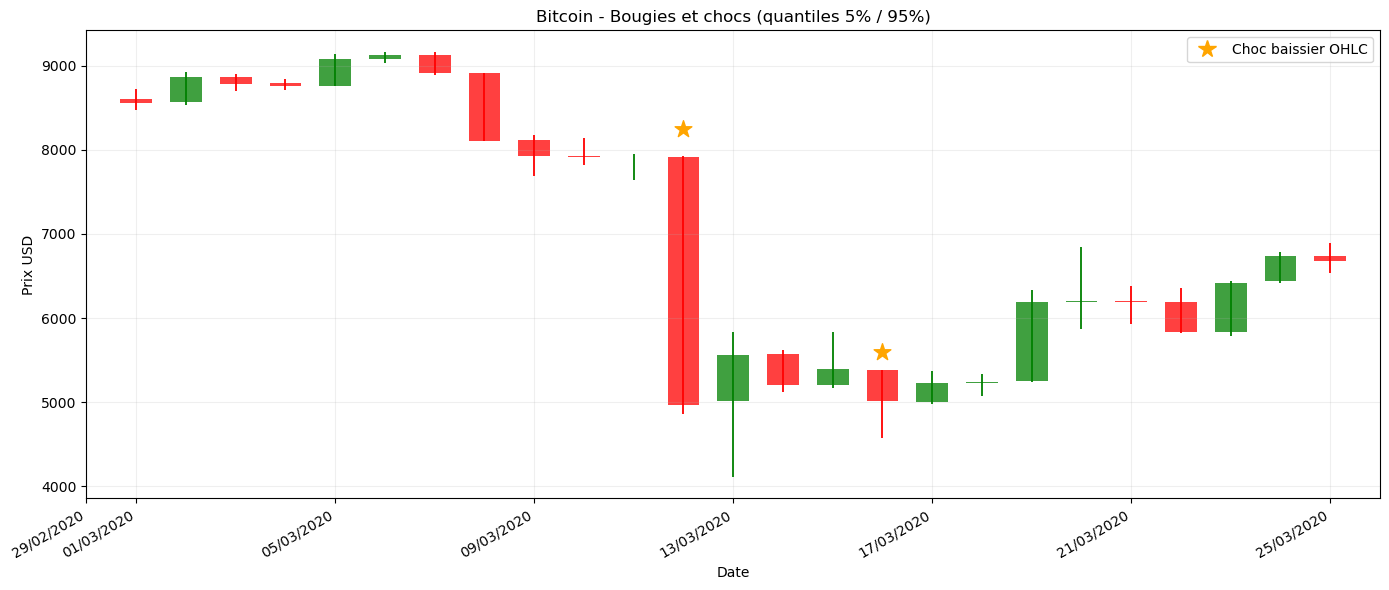

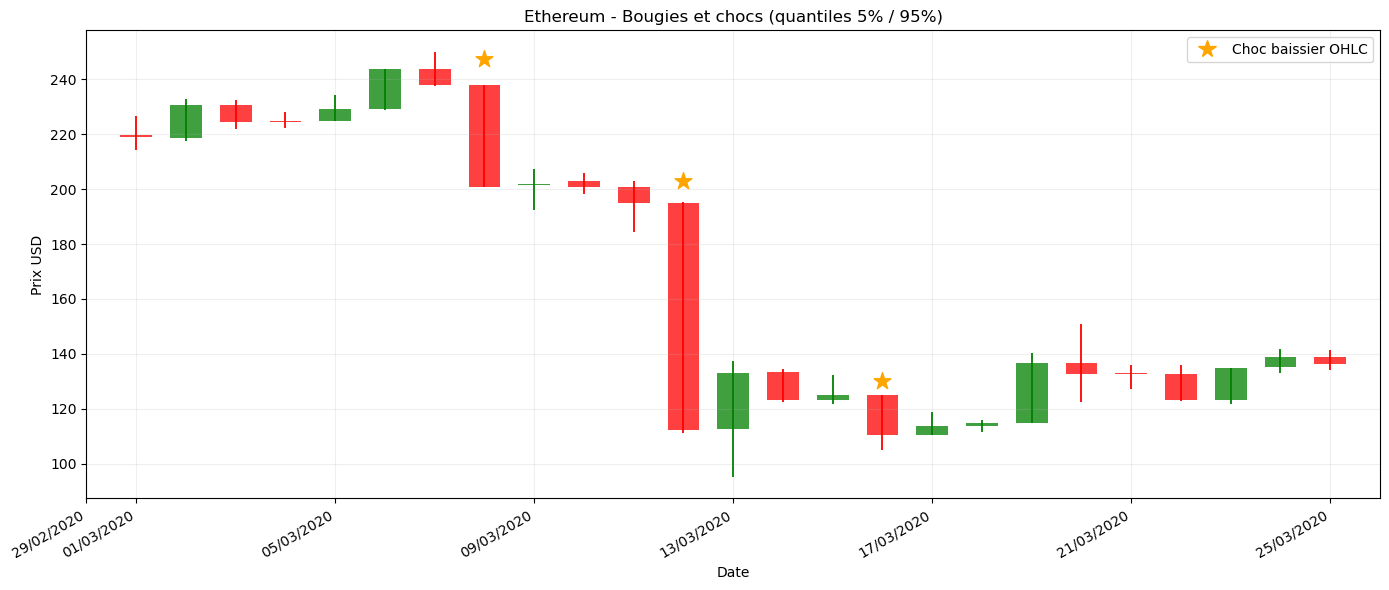

In [26]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

def afficher_bougies_chocs(df, actif, debut, fin):

    selection = df.loc[
        df["Date"].between(debut, fin)
    ].copy()

    fig, ax = plt.subplots(figsize=(14, 6))

    for _, ligne in selection.iterrows():

        x = mdates.date2num(ligne["Date"])

        couleur = (
            "green"
            if ligne["Close"] >= ligne["Open"]
            else "red"
        )

        # Meche : High - Low
        ax.vlines(
            x,
            ligne["Low"],
            ligne["High"],
            color=couleur,
            linewidth=1.3
        )

        # Corps : Open - Close
        bas = min(ligne["Open"], ligne["Close"])
        hauteur = abs(ligne["Close"] - ligne["Open"])

        ax.add_patch(Rectangle(
            (x - 0.32, bas),
            0.64,
            max(hauteur, 0.001),
            facecolor=couleur,
            alpha=0.75
        ))

        # Etoile = choc selon les nouveaux quantiles
        if ligne["Choc_baissier"]:
            ax.scatter(
                x,
                ligne["High"] * 1.04,
                marker="*",
                color="orange",
                s=160,
                zorder=5
            )

    ax.xaxis_date()
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d/%m/%Y")
    )

    ax.set_xlim(
        mdates.date2num(pd.Timestamp(debut)) - 1,
        mdates.date2num(pd.Timestamp(fin)) + 1
    )

    ax.set_title(
        f"{actif} - Bougies et chocs (quantiles 5% / 95%)"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Prix USD")
    ax.grid(alpha=0.2)

    legende = [
        Line2D(
            [0], [0],
            marker="*",
            color="orange",
            linestyle="None",
            markersize=13,
            label="Choc baissier OHLC"
        )
    ]

    ax.legend(handles=legende)

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()


# Periode de mars 2020
afficher_bougies_chocs(
    bougies_btc,
    "Bitcoin",
    "2020-03-01",
    "2020-03-25"
)

afficher_bougies_chocs(
    bougies_eth,
    "Ethereum",
    "2020-03-01",
    "2020-03-25"
)


 chocs détectés,
Bitcoin
110
Journées de choc baissier détectées
Ethereum
221
Journées de choc baissier détectées

Visualiser la distribution du nombre de chocs par mois

### Cellule 9 — Matrices de covariance et de corrélation BTC/ETH

La **covariance** indique comment les rendements varient ensemble, mais dépend des unités et de l'échelle. La **corrélation** standardise cette relation entre −1 et +1.

**Précaution :** ces matrices sont calculées sur les *mêmes dates* pour les deux actifs. Une forte corrélation ne prouve pas une causalité et ne signifie pas que leurs niveaux de prix sont identiques.

**Lien HMM futur :** avec des émissions gaussiennes multivariées, une matrice de covariance pourra être estimée *conditionnellement à chaque état*. Ce n'est pas la même chose que la covariance globale ci-dessous.

In [27]:
covariance = paire.cov()
correlation = paire.corr()
print("Matrice de covariance des rendements (points de % au carré) :")
display(covariance)
print("Matrice de corrélation des rendements :")
display(correlation)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(correlation.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(2), labels=correlation.columns)
ax.set_yticks(range(2), labels=correlation.index)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{correlation.iloc[i,j]:.3f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Corrélation")
ax.set_title("Corrélation des rendements journaliers")
fig.tight_layout()
fig.savefig(FIG_DIR / "correlation_BTC_ETH.png", dpi=140)
plt.show()
rho = float(correlation.loc["BTC", "ETH"])
relation = "positive" if rho > 0 else "négative" if rho < 0 else "nulle"
print(f"Interprétation : corrélation linéaire {relation} ({rho:.3f}) sur {len(paire)} dates communes.")

NameError: name 'paire' is not defined

### Cellule 10 — Histogrammes + densités théoriques
Nous ajustons quatre familles **continues** aux rendements : **normale**, **Student-t**, **Laplace** et **logistique**.

La comparaison visuelle porte sur le centre, l'asymétrie éventuelle et surtout les queues. Les densités sont estimées sur les mêmes rendements que l'histogramme : ce sont des **ajustements descriptifs**, pas une validation hors échantillon.

**Attention :** aucune de ces quatre lois symétriques ne capture toutes les asymétries possibles. Une loi de Student-t peut représenter des queues plus épaisses que la normale.

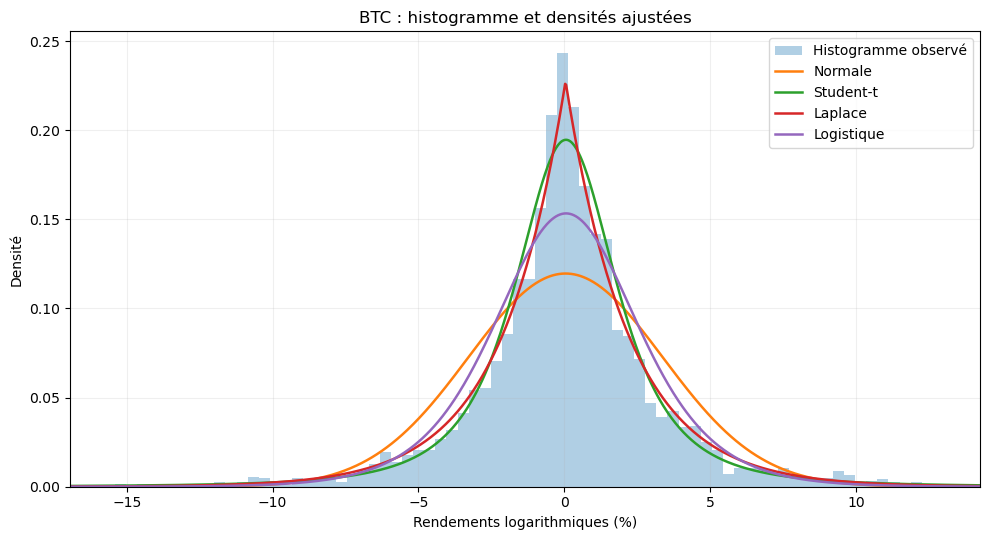

BTC : le graphique est zoomé entre les quantiles 0,1 % et 99,9 %. Les extrêmes restent dans l'échantillon et n'ont pas été supprimés.


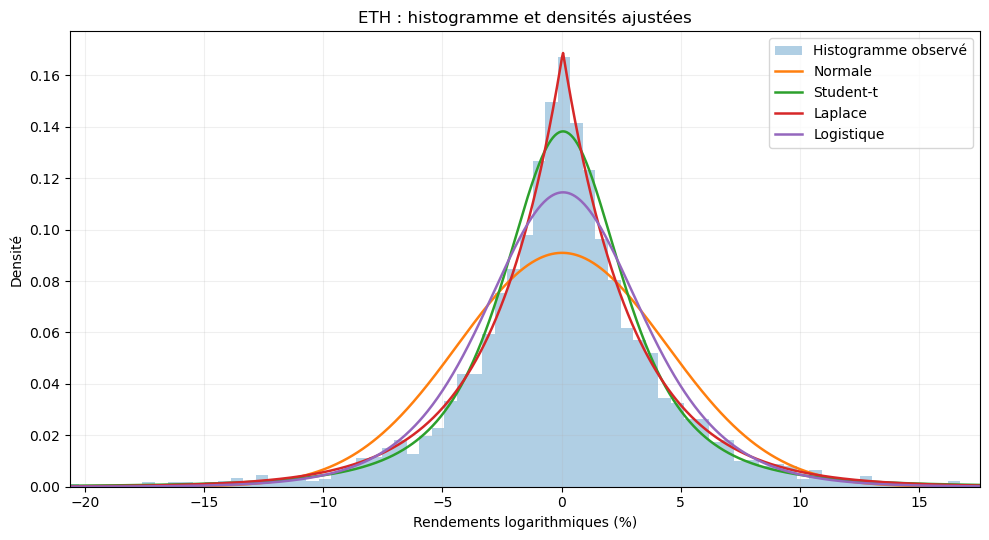

ETH : le graphique est zoomé entre les quantiles 0,1 % et 99,9 %. Les extrêmes restent dans l'échantillon et n'ont pas été supprimés.


In [ ]:
LOIS = {"Normale": stats.norm, "Student-t": stats.t,
        "Laplace": stats.laplace, "Logistique": stats.logistic}
parametres_ajustes = {}
for actif, r in rendements.items():
    x = r.dropna().to_numpy(dtype=float)
    parametres_ajustes[actif] = {nom: tuple(loi.fit(x)) for nom, loi in LOIS.items()}
    xs = np.linspace(np.quantile(x, .001), np.quantile(x, .999), 900)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.hist(x, bins="fd", density=True, alpha=.35, label="Histogramme observé")
    for nom, loi in LOIS.items():
        ax.plot(xs, loi.pdf(xs, *parametres_ajustes[actif][nom]), lw=1.8, label=nom)
    ax.set_xlim(xs.min(), xs.max())
    ax.set_xlabel("Rendements logarithmiques (%)")
    ax.set_ylabel("Densité")
    ax.set_title(f"{actif} : histogramme et densités ajustées")
    ax.legend()
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{actif}_histogramme_densites.png", dpi=140)
    plt.show()
    print(f"{actif} : le graphique est zoomé entre les quantiles 0,1 % et 99,9 %. "
          "Les extrêmes restent dans l'échantillon et n'ont pas été supprimés.")

### Cellule 11 — Q-Q plots (quantiles observés contre quantiles théoriques)

Si la loi proposée décrit correctement les quantiles observés, les points sont proches de la diagonale \(y=x\). Des écarts marqués dans les extrémités indiquent un désaccord dans les queues.

**Précaution :** la qualité d'ajustement est examinée visuellement. On ne conclut pas que la loi est « vraie » parce que les points semblent alignés.

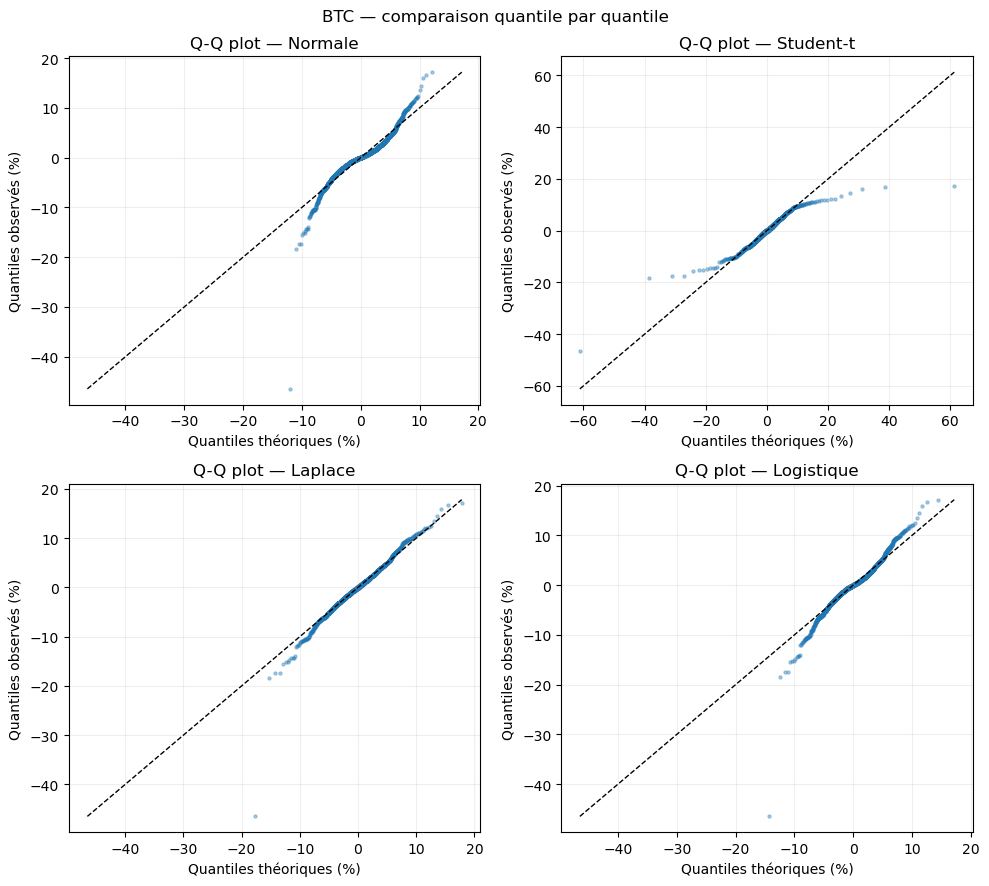

BTC : examine particulièrement les deux extrémités des quatre Q-Q plots.


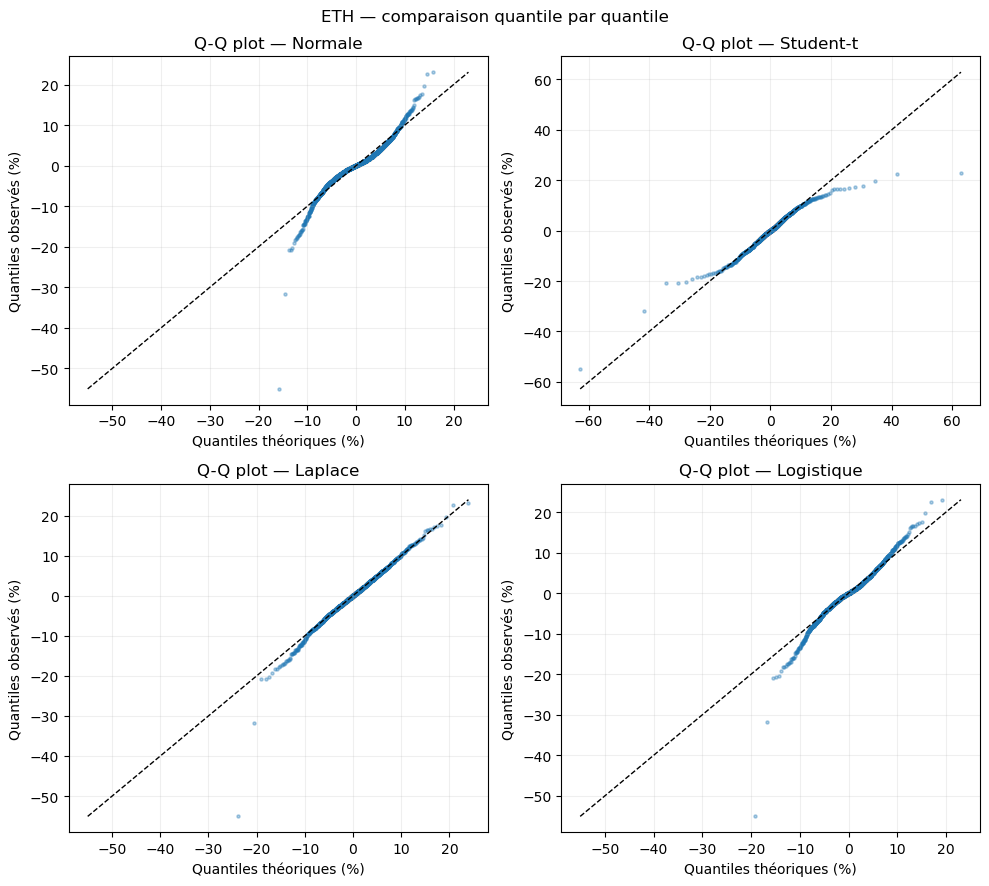

ETH : examine particulièrement les deux extrémités des quatre Q-Q plots.


In [ ]:
for actif, r in rendements.items():
    x = np.sort(r.dropna().to_numpy(dtype=float))
    p = (np.arange(1, len(x)+1)-.5) / len(x)
    fig, axes = plt.subplots(2, 2, figsize=(10, 9))
    for ax, (nom, loi) in zip(axes.flat, LOIS.items()):
        theo = loi.ppf(p, *parametres_ajustes[actif][nom])
        ax.scatter(theo, x, s=5, alpha=.35)
        lo = min(np.min(theo), np.min(x))
        hi = max(np.max(theo), np.max(x))
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set_title(f"Q-Q plot — {nom}")
        ax.set_xlabel("Quantiles théoriques (%)")
        ax.set_ylabel("Quantiles observés (%)")
        ax.grid(alpha=.2)
    fig.suptitle(f"{actif} — comparaison quantile par quantile")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{actif}_qqplots.png", dpi=140)
    plt.show()
    print(f"{actif} : examine particulièrement les deux extrémités des quatre Q-Q plots.")

### Cellule 12 — Tests de Jarque-Bera et Kolmogorov-Smirnov

- **Jarque-Bera** : \(H_0\) = la distribution est normale ; s'appuie sur l'asymétrie et la kurtosis. En grande taille d'échantillon, la statistique est comparée à une loi \(\chi^2(2)\) sous les hypothèses du test.
- **Kolmogorov-Smirnov (KS)** : compare la fonction de répartition empirique à celle d'une loi candidate. Nous le calculons **pour chacune des quatre lois**.
- **Point méthodologique essentiel :** puisque les paramètres des lois sont estimés sur les données analysées, nous utilisons `scipy.stats.goodness_of_fit(..., statistic="ks")` qui calibre la p-value par simulation et réestimation.

Avec `N_MC = 99`, la résolution des p-values est de 0,01 ; pour une étude plus approfondie, augmenter à **999 ou plus**, au prix d'un temps de calcul supérieur. Les hypothèses usuelles d'observations indépendantes sont discutables en finance : les p-values sont ici **exploratoires**. Une p-value élevée ne prouve pas que la loi est correcte, et tester plusieurs lois augmente le risque de décisions trompeuses.

**Cette cellule est plus lente** que les précédentes. Pour un test rapide : définir la variable d'environnement `HMM_KS_SIMULATIONS=19` avant de lancer le notebook ; ne pas utiliser ce réglage pour conclure au seuil de 5 %.

In [ ]:
N_MC = int(os.getenv("HMM_KS_SIMULATIONS", "99"))
if N_MC < 19:
    raise ValueError("Utiliser au moins 19 simulations Monte-Carlo pour cette exploration")
SEUIL = .05
tests_distribution = []
for actif, r in rendements.items():
    x = r.dropna().to_numpy(dtype=float)
    jb = stats.jarque_bera(x)
    print(f"\n{actif} — Jarque-Bera : JB={jb.statistic:.4f}, p={jb.pvalue:.6g} → "
          + ("normalité rejetée" if jb.pvalue < SEUIL else "normalité non rejetée"))
    for nom, loi in LOIS.items():
        test = stats.goodness_of_fit(loi, x, statistic="ks", n_mc_samples=N_MC,
                                     rng=np.random.default_rng(12345))
        tests_distribution.append({
            "Actif": actif, "Loi": nom, "KS_D": float(test.statistic),
            "KS_pvalue_MC": float(test.pvalue),
            "Decision_KS_5pct": "Rejet" if test.pvalue < SEUIL else "Non rejet",
            "JB_pvalue_normale": float(jb.pvalue) if nom == "Normale" else np.nan,
            "Simulations_MC": N_MC,
        })
resultats_tests = pd.DataFrame(tests_distribution)
display(resultats_tests)
resultats_tests.to_csv(REPORT_DIR / "tests_distributions_exploratoires.csv", index=False)
print("Lecture : plus D est petit, plus la distance ECDF-CDF est faible pour la loi ajustée.")
print("Une non-rejection ne démontre pas la loi ; les dépendances temporelles affectent l'interprétation des p-values.")


BTC — Jarque-Bera : JB=30474.6501, p=0 → normalité rejetée

ETH — Jarque-Bera : JB=17118.1281, p=0 → normalité rejetée


,Actif,Loi,KS_D,KS_pvalue_MC,Decision_KS_5pct,JB_pvalue_normale,Simulations_MC
0,BTC,Normale,0.09228,0.01000,Rejet,0.00000,99
1,BTC,Student-t,0.01968,0.01000,Rejet,NaN,99
2,BTC,Laplace,0.02018,0.01000,Rejet,NaN,99
3,BTC,Logistique,0.05215,0.01000,Rejet,NaN,99
4,ETH,Normale,0.08193,0.01000,Rejet,0.00000,99
5,ETH,Student-t,0.02021,0.01000,Rejet,NaN,99
6,ETH,Laplace,0.01135,0.50000,Non rejet,NaN,99
7,ETH,Logistique,0.04431,0.01000,Rejet,NaN,99


Lecture : plus D est petit, plus la distance ECDF-CDF est faible pour la loi ajustée.
Une non-rejection ne démontre pas la loi ; les dépendances temporelles affectent l'interprétation des p-values.


### Cellule 13 — Dépendance temporelle : autocorrélation (ACF) et ADF

- **ACF des rendements** : mesure la dépendance linéaire entre rendements séparés par plusieurs jours.
- **ACF des rendements absolus** : peut révéler des *regroupements de volatilité* (périodes agitées qui se succèdent).
- **ADF (Augmented Dickey-Fuller)** : examine la présence d'une racine unitaire, avec \(H_0\) = racine unitaire. Le rejet ne prouve pas toutes les formes de stationnarité.

**Attention :** ces tests supposent un calendrier régulier. Si des dates sont absentes, nous ne traitons pas les écarts de plusieurs jours comme un seul jour. Les p-values classiques restent sensibles aux hypothèses temporelles et à l'hétéroscédasticité.

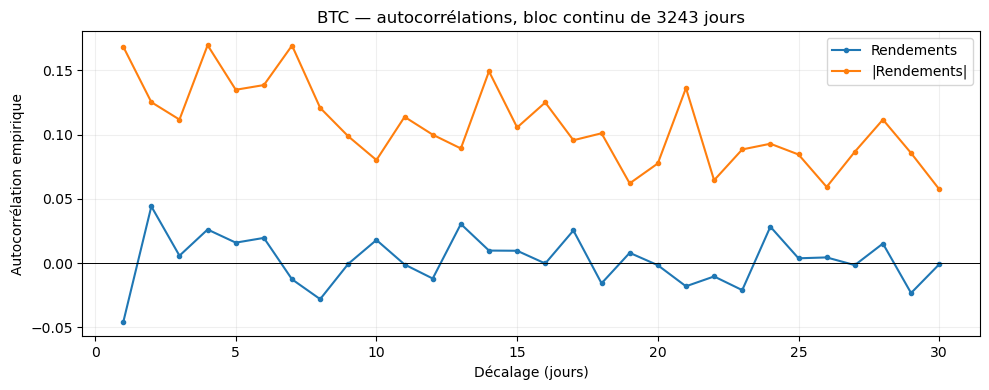

BTC : ACF(1) r=-0.046 ; ACF(1) |r|=0.169 ; ADF=-19.894, p=0.
ADF : racine unitaire rejetée au seuil 5 %


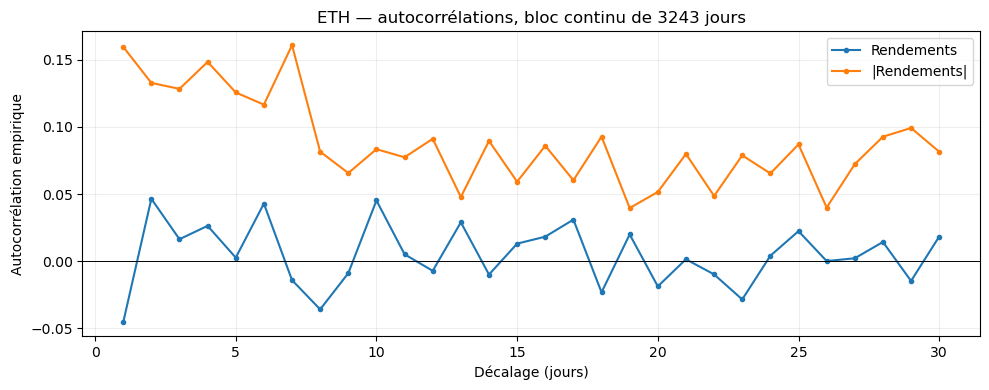

ETH : ACF(1) r=-0.046 ; ACF(1) |r|=0.160 ; ADF=-17.265, p=5.91247e-30.
ADF : racine unitaire rejetée au seuil 5 %


In [ ]:
from statsmodels.tsa.stattools import adfuller

for actif, serie in rendements.items():
    # Échantillon continu le plus long si des jours sont absents.
    s = serie.dropna()
    blocs = (s.index.to_series().diff().ne(pd.Timedelta(days=1))).cumsum()
    plus_long = s.groupby(blocs).apply(lambda bloc: len(bloc)).idxmax()
    x = s[blocs == plus_long]
    if len(x) < 40:
        print(f"{actif} : bloc continu trop court pour ACF/ADF")
        continue
    lags = list(range(1, min(30, len(x)//4)+1))
    acf_ret = [x.autocorr(lag=k) for k in lags]
    acf_abs = [x.abs().autocorr(lag=k) for k in lags]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(lags, acf_ret, marker="o", ms=3, label="Rendements")
    ax.plot(lags, acf_abs, marker="o", ms=3, label="|Rendements|")
    ax.axhline(0, color="black", lw=.7)
    ax.set_xlabel("Décalage (jours)")
    ax.set_ylabel("Autocorrélation empirique")
    ax.set_title(f"{actif} — autocorrélations, bloc continu de {len(x)} jours")
    ax.legend()
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{actif}_autocorrelations.png", dpi=140)
    plt.show()
    adf = adfuller(x.to_numpy(), autolag="AIC")
    print(f"{actif} : ACF(1) r={acf_ret[0]:.3f} ; ACF(1) |r|={acf_abs[0]:.3f} ; "
          f"ADF={adf[0]:.3f}, p={adf[1]:.6g}.")
    print("ADF : racine unitaire rejetée au seuil 5 %" if adf[1]<.05 else
          "ADF : racine unitaire non rejetée au seuil 5 %")

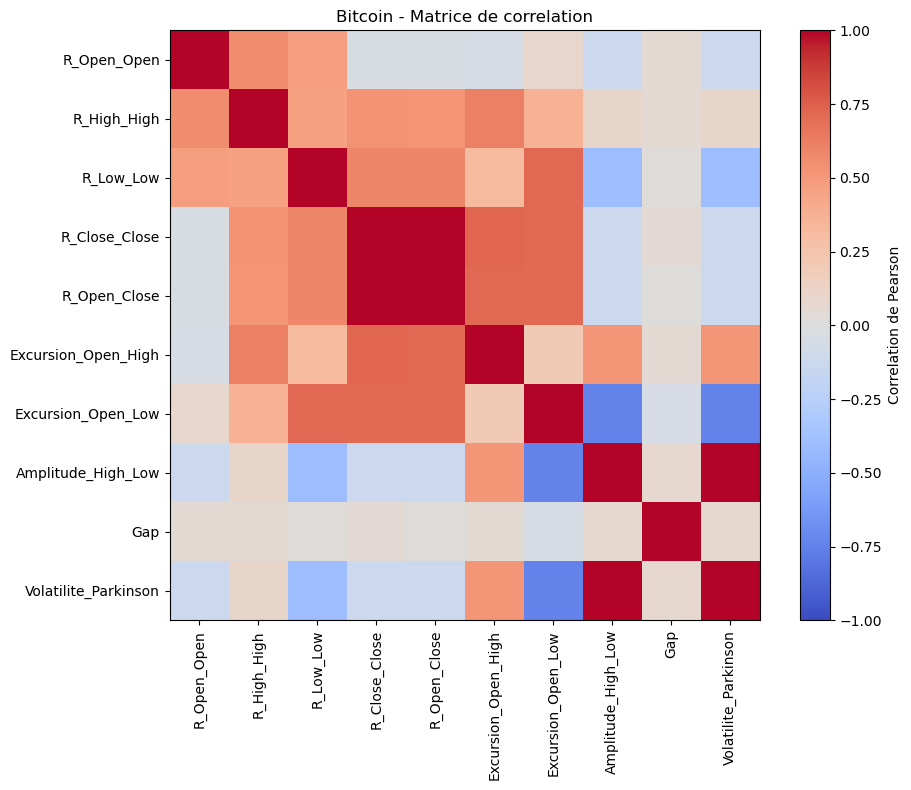


===== Bitcoin =====
Couples fortement correles :


,Variable_1,Variable_2,Correlation
0,R_Close_Close,R_Open_Close,0.99910
1,Amplitude_High_Low,Volatilite_Parkinson,1.00000


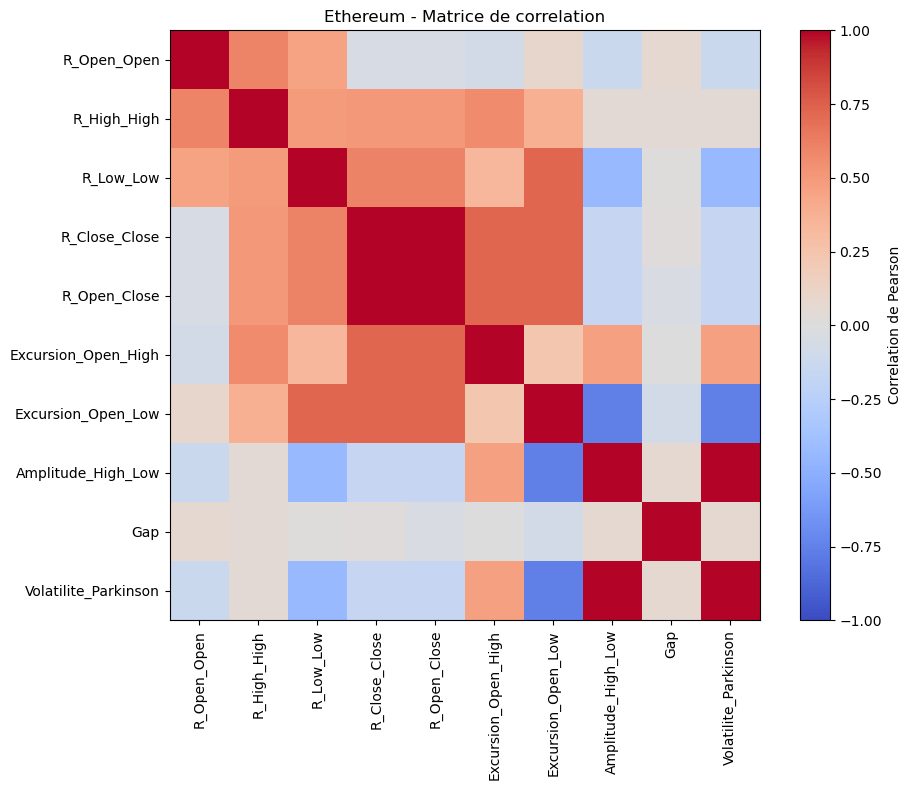


===== Ethereum =====
Couples fortement correles :


,Variable_1,Variable_2,Correlation
0,R_Close_Close,R_Open_Close,0.99900
1,Amplitude_High_Low,Volatilite_Parkinson,1.00000


In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

variables = [
    "R_Open_Open",
    "R_High_High",
    "R_Low_Low",
    "R_Close_Close",
    "R_Open_Close",
    "Excursion_Open_High",
    "Excursion_Open_Low",
    "Amplitude_High_Low",
    "Gap",
    "Volatilite_Parkinson"
]

def analyser_correlations(df, actif):

    d = df.copy()
    d["Date"] = pd.to_datetime(d["Date"])

    # Periode d'entrainement
    d = d.loc[
        d["Date"].between(
            "2018-01-01", "2024-12-31"
        )
    ]

    X = d[variables].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    corr = X.corr()

    # Matrice de correlation
    plt.figure(figsize=(10, 8))
    plt.imshow(
        corr,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    plt.colorbar(label="Correlation de Pearson")

    plt.xticks(
        range(len(variables)),
        variables,
        rotation=90
    )
    plt.yticks(
        range(len(variables)),
        variables
    )

    plt.title(f"{actif} - Matrice de correlation")
    plt.tight_layout()
    plt.show()

    # Variables fortement correlees
    resultats = []

    for i in range(len(variables)):
        for j in range(i + 1, len(variables)):

            valeur = corr.iloc[i, j]

            if abs(valeur) >= 0.95:
                resultats.append({
                    "Variable_1": variables[i],
                    "Variable_2": variables[j],
                    "Correlation": valeur
                })

    tableau = pd.DataFrame(
        resultats,
        columns=[
            "Variable_1",
            "Variable_2",
            "Correlation"
        ]
    )

    print(f"\n===== {actif} =====")
    print("Couples fortement correles :")

    display(tableau.round(4))

    return corr, tableau


# Analyse Bitcoin uniquement
corr_btc, redondances_btc = analyser_correlations(
    btc_analyse, "Bitcoin"
)

# Analyse Ethereum uniquement
corr_eth, redondances_eth = analyser_correlations(
    eth_analyse, "Ethereum"
)



===== Bitcoin =====

STATISTIQUES


,mean,std,var,min,max,skew
Rendement,0.07520,3.56670,12.72120,-46.47300,17.18210,-0.98010
Log_Amplitude,1.55010,0.52460,0.27520,0.30670,3.91090,0.39120
Variation_LogVolume,0.00060,0.28920,0.08360,-2.03400,1.86240,0.06630



MATRICE DE CORRELATION


,Rendement,Log_Amplitude,Variation_LogVolume
Rendement,1.00000,-0.04450,0.03270
Log_Amplitude,-0.04450,1.00000,0.39560
Variation_LogVolume,0.03270,0.39560,1.00000


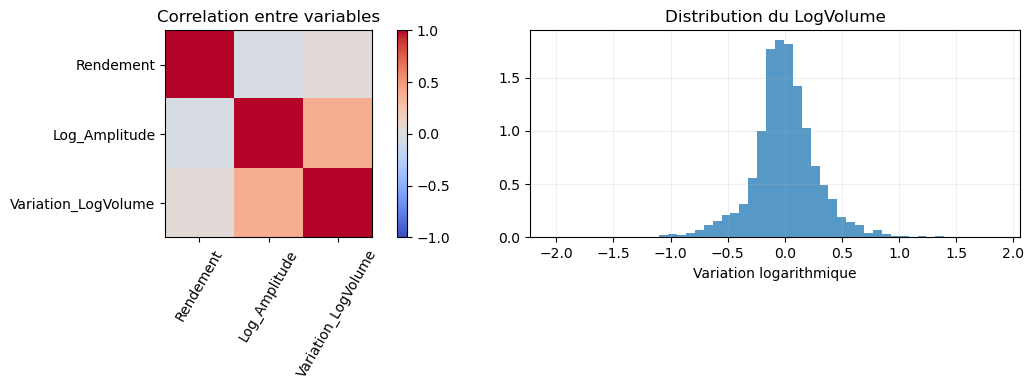


===== Ethereum =====

STATISTIQUES


,mean,std,var,min,max,skew
Rendement,0.05720,4.57590,20.93920,-55.07320,23.06950,-0.95210
Log_Amplitude,1.76470,0.52320,0.27370,0.30370,4.05310,0.38910
Variation_LogVolume,0.00080,0.27880,0.07770,-1.08330,1.29740,0.19940



MATRICE DE CORRELATION


,Rendement,Log_Amplitude,Variation_LogVolume
Rendement,1.00000,-0.07530,0.01100
Log_Amplitude,-0.07530,1.00000,0.40190
Variation_LogVolume,0.01100,0.40190,1.00000


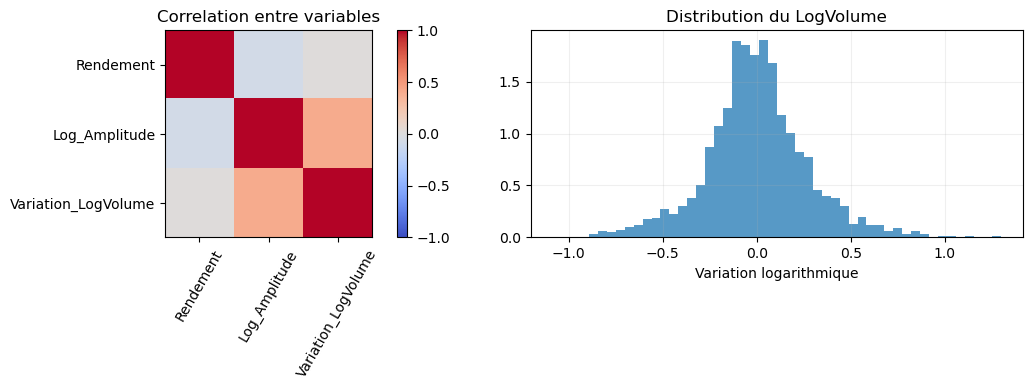

In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def verifier_variables_hmm(df, actif):

    d = df.copy()

    d["Date"] = pd.to_datetime(d["Date"])
    d = d.sort_values("Date").reset_index(drop=True)

    # Variables candidates
    d["Rendement"] = d["R_Close_Close"]

    d["Log_Amplitude"] = np.log1p(
        d["Amplitude_High_Low"]
    )

    d["Variation_LogVolume"] = (
        np.log1p(d["Volume"]).diff()
    )

    features = [
        "Rendement",
        "Log_Amplitude",
        "Variation_LogVolume"
    ]

    # Statistiques calculees sur 2018-2024
    train = d.loc[
        d["Date"] <= "2024-12-31",
        ["Date"] + features
    ].copy()

    train = train.replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    # Statistiques descriptives
    stats = train[features].agg([
        "mean", "std", "var",
        "min", "max", "skew"
    ]).T

    # Relations entre variables
    correlation = train[features].corr()

    print(f"\n===== {actif} =====")

    print("\nSTATISTIQUES")
    display(stats.round(4))

    print("\nMATRICE DE CORRELATION")
    display(correlation.round(4))

    # Graphique des correlations
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    im = axes[0].imshow(
        correlation,
        vmin=-1, vmax=1,
        cmap="coolwarm"
    )

    axes[0].set_xticks(range(len(features)))
    axes[0].set_yticks(range(len(features)))

    axes[0].set_xticklabels(features, rotation=60)
    axes[0].set_yticklabels(features)

    axes[0].set_title("Correlation entre variables")
    fig.colorbar(im, ax=axes[0])

    # Distribution du changement de volume
    axes[1].hist(
        train["Variation_LogVolume"],
        bins=50, density=True,
        alpha=0.75
    )

    axes[1].set_title("Distribution du LogVolume")
    axes[1].set_xlabel("Variation logarithmique")
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    return train


# Bitcoin : selection independante
features_btc = verifier_variables_hmm(
    btc_analyse, "Bitcoin"
)

# Ethereum : selection independante
features_eth = verifier_variables_hmm(
    eth_analyse, "Ethereum"
)



===== Bitcoin =====
STATISTIQUES DES VARIABLES


,mean,std,var,min,max,skew
Rendement,0.08800,3.51420,12.34930,-46.47300,17.18210,-0.97310
Log_Amplitude,1.54090,0.51850,0.26890,0.30670,3.91090,0.38210
Variation_LogVolume,0.00060,0.29000,0.08410,-2.03400,1.86240,0.06440
Volatilite_30j,3.25800,1.37600,1.89350,0.89260,10.36490,1.81020


MATRICE DE CORRELATION


,Rendement,Log_Amplitude,Variation_LogVolume,Volatilite_30j
Rendement,1.00000,-0.03370,0.03350,-0.01980
Log_Amplitude,-0.03370,1.00000,0.40120,0.48280
Variation_LogVolume,0.03350,0.40120,1.00000,-0.01140
Volatilite_30j,-0.01980,0.48280,-0.01140,1.00000


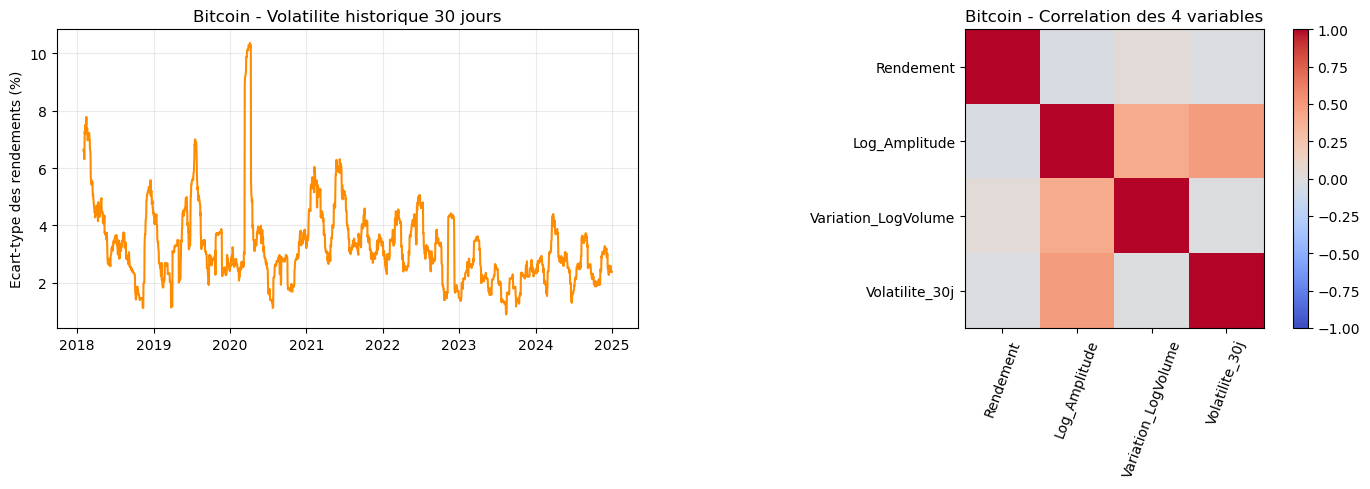


===== Ethereum =====
STATISTIQUES DES VARIABLES


,mean,std,var,min,max,skew
Rendement,0.04490,4.52270,20.45440,-55.07320,23.06950,-0.98680
Log_Amplitude,1.75560,0.51740,0.26770,0.30370,4.05310,0.38150
Variation_LogVolume,0.00060,0.27860,0.07760,-1.08330,1.29740,0.19070
Volatilite_30j,4.19210,1.74590,3.04830,0.80780,12.63670,1.63500


MATRICE DE CORRELATION


,Rendement,Log_Amplitude,Variation_LogVolume,Volatilite_30j
Rendement,1.00000,-0.07780,0.00960,-0.03160
Log_Amplitude,-0.07780,1.00000,0.40580,0.44140
Variation_LogVolume,0.00960,0.40580,1.00000,-0.01530
Volatilite_30j,-0.03160,0.44140,-0.01530,1.00000


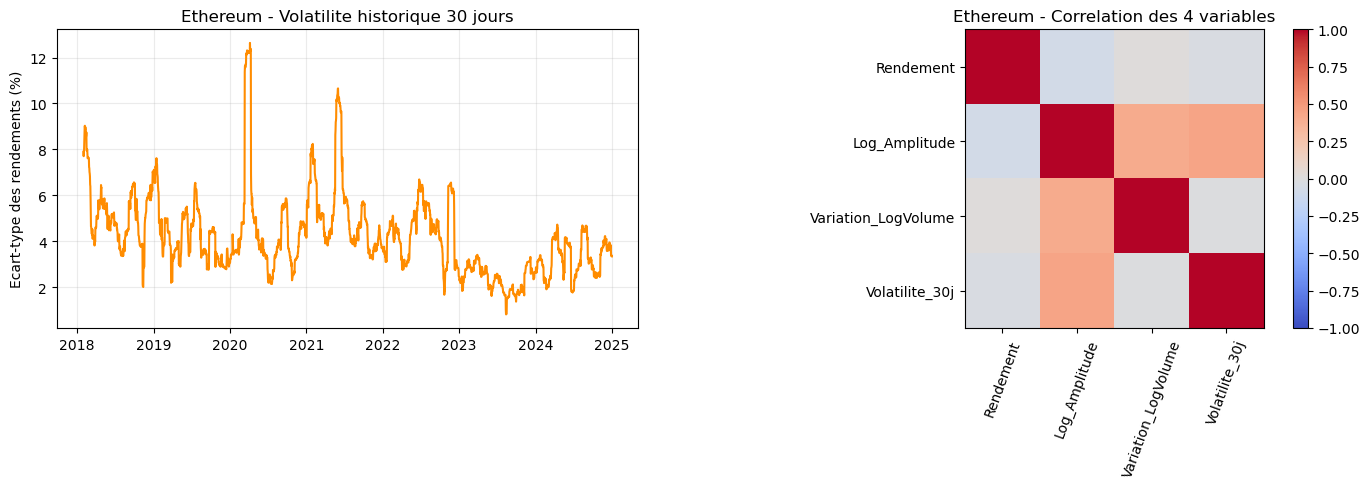

In [31]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def analyser_volatilite_hmm(df, actif):

    d = df.copy()
    d["Date"] = pd.to_datetime(d["Date"])
    d = d.sort_values("Date").reset_index(drop=True)

    # 1. Rendement quotidien
    d["Rendement"] = d["R_Close_Close"]

    # 2. Amplitude transformee
    d["Log_Amplitude"] = np.log1p(
        d["Amplitude_High_Low"]
    )

    # 3. Variation logarithmique du volume
    d["Variation_LogVolume"] = (
        np.log1p(d["Volume"]).diff()
    )

    # 4. Volatilite historique 30 jours
    d["Volatilite_30j"] = (
        d["R_Close_Close"]
        .rolling(window=30, min_periods=30)
        .std()
    )

    variables = [
        "Rendement",
        "Log_Amplitude",
        "Variation_LogVolume",
        "Volatilite_30j"
    ]

    # Utiliser uniquement 2018-2024
    train = d.loc[
        d["Date"] <= "2024-12-31",
        ["Date"] + variables
    ].copy()

    train = (
        train.replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    print(f"\n===== {actif} =====")

    print("STATISTIQUES DES VARIABLES")
    display(
        train[variables].agg([
            "mean", "std", "var",
            "min", "max", "skew"
        ]).T.round(4)
    )

    corr = train[variables].corr()

    print("MATRICE DE CORRELATION")
    display(corr.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Evolution de la volatilite
    axes[0].plot(
        train["Date"],
        train["Volatilite_30j"],
        color="darkorange"
    )
    axes[0].set_title(
        f"{actif} - Volatilite historique 30 jours"
    )
    axes[0].set_ylabel("Ecart-type des rendements (%)")
    axes[0].grid(alpha=0.25)

    # Matrice de correlation
    im = axes[1].imshow(
        corr, cmap="coolwarm",
        vmin=-1, vmax=1
    )

    axes[1].set_xticks(range(len(variables)))
    axes[1].set_yticks(range(len(variables)))

    axes[1].set_xticklabels(
        variables, rotation=70
    )
    axes[1].set_yticklabels(variables)

    axes[1].set_title(
        f"{actif} - Correlation des 4 variables"
    )

    fig.colorbar(im, ax=axes[1])
    plt.tight_layout()
    plt.show()

    return train


features_btc_4 = analyser_volatilite_hmm(
    btc_analyse, "Bitcoin"
)

features_eth_4 = analyser_volatilite_hmm(
    eth_analyse, "Ethereum"
)



===== Bitcoin =====
MATRICE DE COVARIANCE FULL


,Rendement,Log_Amplitude,Variation_LogVolume
Rendement,1.00040,-0.04450,0.03270
Log_Amplitude,-0.04450,1.00040,0.39580
Variation_LogVolume,0.03270,0.39580,1.00040


VALEURS PROPRES
[0.59723 1.0076  1.39635]
CONDITIONNEMENT
2.33806


C:\Users\utente\AppData\Local\Temp\ipykernel_2000\1848092529.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


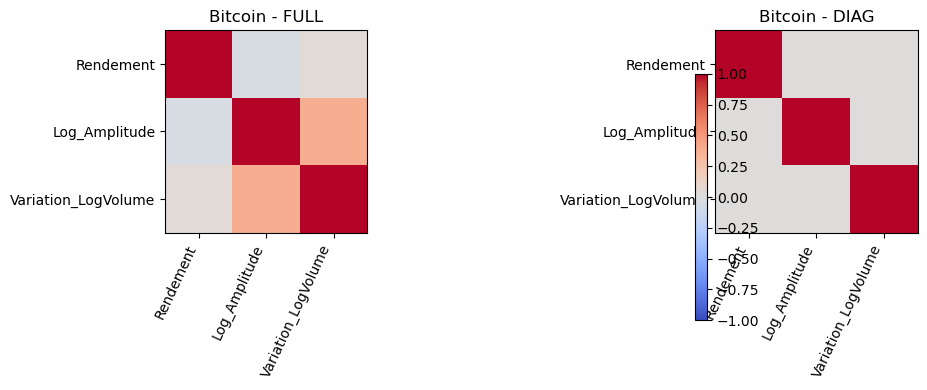


===== Ethereum =====
MATRICE DE COVARIANCE FULL


,Rendement,Log_Amplitude,Variation_LogVolume
Rendement,1.00040,-0.07530,0.01100
Log_Amplitude,-0.07530,1.00040,0.40200
Variation_LogVolume,0.01100,0.40200,1.00040


VALEURS PROPRES
[0.58923 1.00438 1.40756]
CONDITIONNEMENT
2.3888


C:\Users\utente\AppData\Local\Temp\ipykernel_2000\1848092529.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


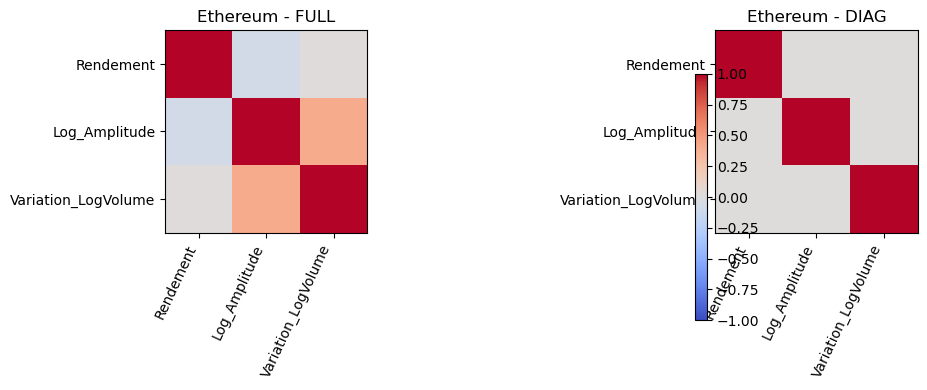

In [32]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

variables = [
    "Rendement",
    "Log_Amplitude",
    "Variation_LogVolume"
]

def analyser_covariance_features(df, actif):

    # Nos features déjà créées
    X = df[variables].copy()
    X = X.replace([np.inf, -np.inf], np.nan).dropna()

    # Standardiser pour comparer les échelles
    scaler = StandardScaler()
    X_std = scaler.fit_transform(X)

    # Matrice de covariance empirique FULL
    covariance_full = np.cov(X_std, rowvar=False)

    # Matrice DIAG pour comparaison
    covariance_diag = np.diag(
        np.diag(covariance_full)
    )

    # Valeurs propres et conditionnement
    valeurs_propres = np.linalg.eigvalsh(
        covariance_full
    )
    conditionnement = np.linalg.cond(
        covariance_full
    )

    print(f"\n===== {actif} =====")

    print("MATRICE DE COVARIANCE FULL")
    display(pd.DataFrame(
        covariance_full,
        index=variables,
        columns=variables
    ).round(4))

    print("VALEURS PROPRES")
    print(np.round(valeurs_propres, 5))

    print("CONDITIONNEMENT")
    print(round(conditionnement, 5))

    # Comparaison graphique
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for ax, matrice, titre in zip(
        axes,
        [covariance_full, covariance_diag],
        ["FULL", "DIAG"]
    ):
        image = ax.imshow(
            matrice,
            cmap="coolwarm",
            vmin=-1,
            vmax=1
        )

        ax.set_xticks(range(len(variables)))
        ax.set_yticks(range(len(variables)))

        ax.set_xticklabels(
            variables, rotation=65, ha="right"
        )
        ax.set_yticklabels(variables)
        ax.set_title(f"{actif} - {titre}")

    fig.colorbar(image, ax=axes, shrink=0.8)
    plt.tight_layout()
    plt.show()

    return covariance_full


# Les DataFrames features_btc et features_eth
# ont été créés pendant notre Feature Selection

cov_full_btc = analyser_covariance_features(
    features_btc, "Bitcoin"
)

cov_full_eth = analyser_covariance_features(
    features_eth, "Ethereum"
)


In [33]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

FEATURES = [
    "Rendement",
    "Log_Amplitude",
    "Variation_LogVolume"
]

def preparer_y_hmm(df, actif):

    d = df.copy()
    d["Date"] = pd.to_datetime(d["Date"])
    d = d.sort_values("Date").reset_index(drop=True)

    # Feature 1 : rendement
    d["Rendement"] = d["R_Close_Close"]

    # Feature 2 : amplitude transformee
    d["Log_Amplitude"] = np.log1p(
        d["Amplitude_High_Low"]
    )

    # Feature 3 : changement logarithmique du volume
    d["Variation_LogVolume"] = (
        np.log1p(d["Volume"]).diff()
    )

    # Matrice des observations Y
    Y = (
        d[["Date"] + FEATURES]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .set_index("Date")
    )

    # Separation chronologique
    Y_train = Y.loc[:"2024-12-31"]
    Y_test = Y.loc["2025-01-01":]

    # Standardisation sans utiliser les donnees futures
    scaler = StandardScaler()
    X_train = scaler.fit_transform(Y_train)
    X_test = scaler.transform(Y_test)

    print(f"\n===== {actif} =====")
    print("Observations train :", X_train.shape)
    print("Observations test :", X_test.shape)

    display(Y_train.head())

    return {
        "Y_train": Y_train,
        "Y_test": Y_test,
        "X_train": X_train,
        "X_test": X_test,
        "scaler": scaler
    }


data_btc = preparer_y_hmm(
    btc_analyse, "Bitcoin"
)

data_eth = preparer_y_hmm(
    eth_analyse, "Ethereum"
)



===== Bitcoin =====
Observations train : (2556, 3)
Observations test : (687, 3)


,Rendement,Log_Amplitude,Variation_LogVolume
Date,,,
2018-01-02,9.25893,2.83206,0.49286
2018-01-03,1.45051,1.75607,0.00150
2018-01-04,2.58584,2.20285,0.25549
2018-01-05,11.09445,2.78735,0.09026
2018-01-06,0.55784,1.87173,-0.26370



===== Ethereum =====
Observations train : (2556, 3)
Observations test : (687, 3)


,Rendement,Log_Amplitude,Variation_LogVolume
Date,,,
2018-01-02,13.51447,2.88651,0.80110
2018-01-03,8.48034,2.52720,-0.12708
2018-01-04,1.87304,2.39348,0.24434
2018-01-05,1.69797,2.54428,0.02735
2018-01-06,4.31175,2.00594,-0.36010


In [39]:
%pip install hmmlearn

Note: you may need to restart the kernel to use updated packages.


In [40]:

import numpy as np
import pandas as pd
from hmmlearn.hmm import GaussianHMM

modeles_hmm = {}

def estimer_hmm(data, actif, n_etats=3):

    X = data["X_train"]
    scaler = data["scaler"]

    meilleur = None
    meilleur_score = -np.inf
    meilleure_seed = None

    # Plusieurs initialisations EM
    for seed in [0, 7, 13, 23, 42]:

        try:
            modele = GaussianHMM(
                n_components=n_etats,
                covariance_type="full",
                n_iter=300,
                tol=1e-4,
                min_covar=1e-3,
                random_state=seed
            )

            modele.fit(X)
            score = modele.score(X)

            if np.isfinite(score) and score > meilleur_score:
                meilleur = modele
                meilleur_score = score
                meilleure_seed = seed

        except (ValueError, np.linalg.LinAlgError) as e:
            print(f"{actif} - seed {seed} : {e}")

    if meilleur is None:
        raise RuntimeError(
            f"Aucun HMM exploitable pour {actif}"
        )

    # Probabilites initiales
    pi = pd.DataFrame({
        "Etat": range(n_etats),
        "Probabilite_initiale": meilleur.startprob_
    })

    # Matrice de transition
    noms_etats = [f"Etat_{k}" for k in range(n_etats)]

    A = pd.DataFrame(
        meilleur.transmat_,
        index=noms_etats,
        columns=noms_etats
    )

    # Moyennes des emissions dans les unites originales
    moyennes = scaler.inverse_transform(
        meilleur.means_
    )

    tableau_moyennes = pd.DataFrame(
        moyennes,
        index=noms_etats,
        columns=FEATURES
    )

    # Covariances conditionnelles par etat
    covariances = []

    for k in range(n_etats):

        cov_std = meilleur.covars_[k]

        cov_originale = (
            cov_std *
            np.outer(scaler.scale_, scaler.scale_)
        )

        covariances.append(cov_originale)

    # Resume
    print(f"\n========== {actif} ==========")
    print("Initialisation retenue :", meilleure_seed)
    print("Convergence :", meilleur.monitor_.converged)
    print("Log-vraisemblance :", round(meilleur_score, 3))
    print("AIC :", round(meilleur.aic(X), 3))
    print("BIC :", round(meilleur.bic(X), 3))

    print("\n1. DISTRIBUTION INITIALE PI")
    display(pi.round(4))

    print("\n2. MATRICE DE TRANSITION A")
    display(A.round(4))

    print("\n3. MOYENNES DES EMISSIONS")
    display(tableau_moyennes.round(4))

    print("\n4. COVARIANCES FULL PAR ETAT")

    for k, cov in enumerate(covariances):
        print(f"\nEtat {k}")
        display(pd.DataFrame(
            cov,
            index=FEATURES,
            columns=FEATURES
        ).round(4))

    return {
        "modele": meilleur,
        "pi": pi,
        "A": A,
        "moyennes": tableau_moyennes,
        "covariances": covariances,
        "data": data
    }


modeles_hmm["BTC"] = estimer_hmm(
    data_btc, "Bitcoin"
)

modeles_hmm["ETH"] = estimer_hmm(
    data_eth, "Ethereum"
)



========== Bitcoin ==========
Initialisation retenue : 13
Convergence : True
Log-vraisemblance : -8984.36
AIC : 18038.721
BIC : 18243.338

1. DISTRIBUTION INITIALE PI


,Etat,Probabilite_initiale
0,0,0.00000
1,1,1.00000
2,2,0.00000



2. MATRICE DE TRANSITION A


,Etat_0,Etat_1,Etat_2
Etat_0,0.64830,0.06160,0.29020
Etat_1,0.02170,0.63220,0.34610
Etat_2,0.23330,0.11710,0.64960



3. MOYENNES DES EMISSIONS


,Rendement,Log_Amplitude,Variation_LogVolume
Etat_0,0.01700,1.01220,-0.08110
Etat_1,-0.18380,2.25820,0.10570
Etat_2,0.22830,1.61240,0.01110


... (14 outputs left out)


Etat 1


,Rendement,Log_Amplitude,Variation_LogVolume
Rendement,58.10050,-0.57730,-0.15980
Log_Amplitude,-0.57730,0.16670,0.06370
Variation_LogVolume,-0.15980,0.06370,0.08610



Etat 2


,Rendement,Log_Amplitude,Variation_LogVolume
Rendement,5.53780,0.65150,0.26610
Log_Amplitude,0.65150,0.11370,0.04100
Variation_LogVolume,0.26610,0.04100,0.07570


Les résultats sont intéressants : les modèles semblent distinguer plusieurs niveaux d'agitation du marché. Mais ils ne représentent pas les mêmes régimes pour Bitcoin et Ethereum.
1. Interprétation des trois états — Bitcoin
État	Rendement moyen	Écart-type du rendement	Interprétation provisoire
0	+0,017 %	0,828 %	Marché calme
1	−0,184 %	6,762 %	Forte turbulence / stress
2	+0,228 %	2,563 %	Marché intermédiaire, légèrement positif

L'état 1 présente une variance du rendement de 45,72, contre seulement 0,685 pour l'état 0. Il représente donc une agitation beaucoup plus importante.

Cependant, il y a un problème pour notre objectif : le modèle BTC ne distingue pas encore clairement un régime haussier d'un régime baissier. L'état 1 est très volatil, mais son rendement moyen est seulement légèrement négatif.

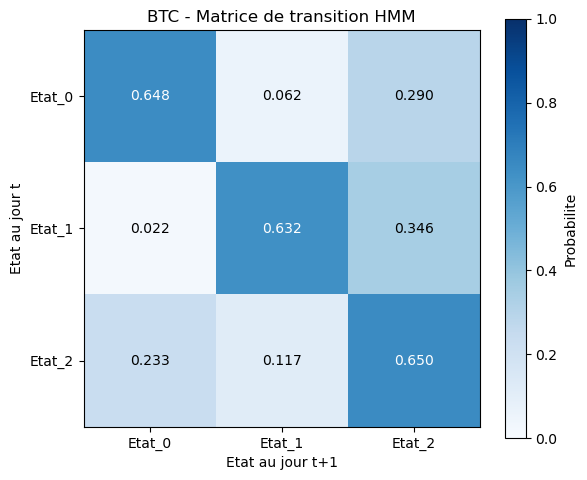

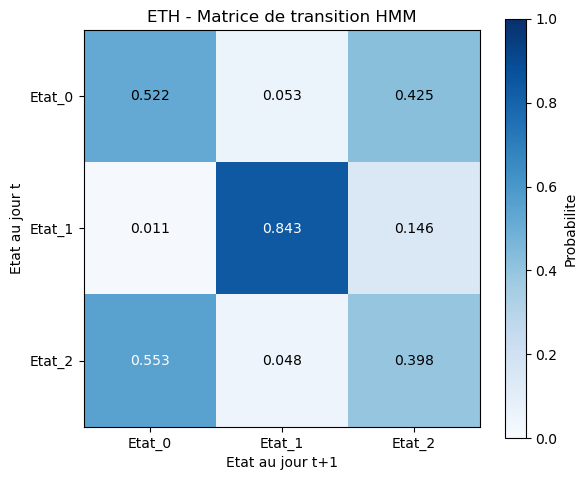

In [41]:

import matplotlib.pyplot as plt
import numpy as np

for actif, resultat in modeles_hmm.items():

    A = resultat["A"]

    fig, ax = plt.subplots(figsize=(6, 5))

    im = ax.imshow(
        A.values,
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    ax.set_xticks(range(len(A.columns)))
    ax.set_yticks(range(len(A.index)))

    ax.set_xticklabels(A.columns)
    ax.set_yticklabels(A.index)

    for i in range(len(A.index)):
        for j in range(len(A.columns)):
            p = A.iloc[i, j]

            ax.text(
                j, i,
                f"{p:.3f}",
                ha="center",
                va="center",
                color="white" if p > 0.55 else "black"
            )

    ax.set_xlabel("Etat au jour t+1")
    ax.set_ylabel("Etat au jour t")
    ax.set_title(f"{actif} - Matrice de transition HMM")

    plt.colorbar(im, ax=ax, label="Probabilite")
    plt.tight_layout()
    plt.show()


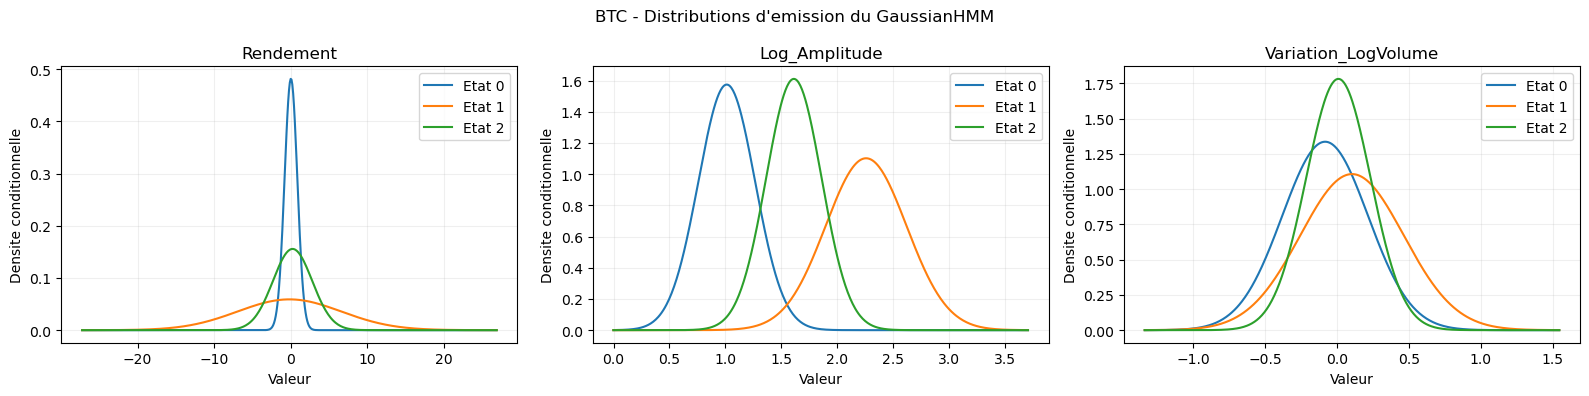

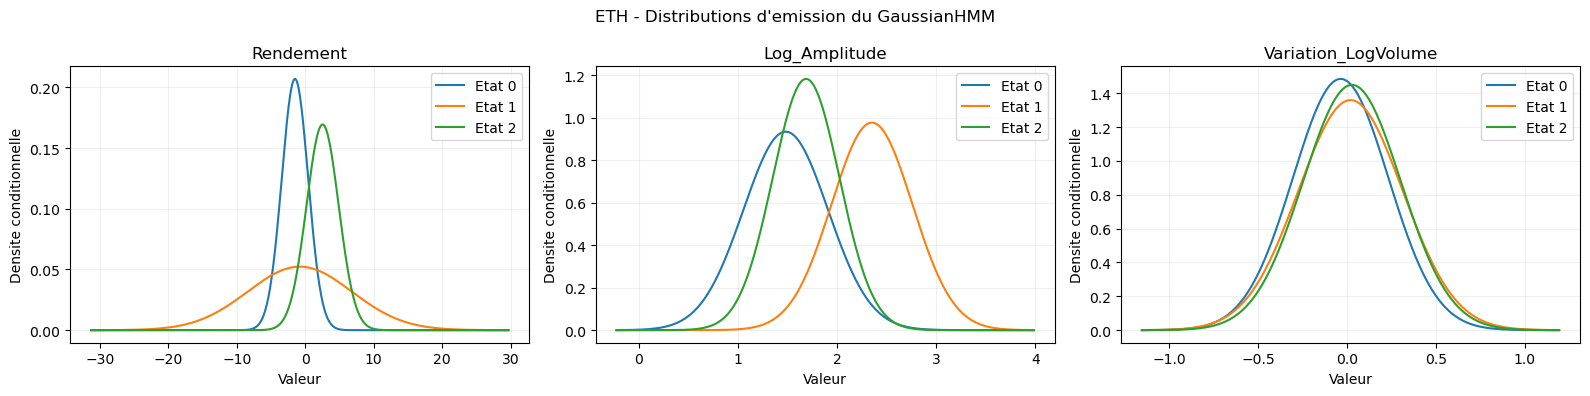

In [42]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

for actif, resultat in modeles_hmm.items():

    moyennes = resultat["moyennes"]
    covariances = resultat["covariances"]

    fig, axes = plt.subplots(
        1, len(FEATURES),
        figsize=(16, 4)
    )

    for j, variable in enumerate(FEATURES):

        ax = axes[j]

        # Etendue de l'axe
        min_x = min(
            moyennes.iloc[k, j] -
            4 * np.sqrt(covariances[k][j, j])
            for k in range(len(covariances))
        )

        max_x = max(
            moyennes.iloc[k, j] +
            4 * np.sqrt(covariances[k][j, j])
            for k in range(len(covariances))
        )

        grille = np.linspace(min_x, max_x, 500)

        for k in range(len(covariances)):

            mu = moyennes.iloc[k, j]
            sigma = np.sqrt(covariances[k][j, j])

            densite = norm.pdf(
                grille, loc=mu, scale=sigma
            )

            ax.plot(
                grille, densite,
                label=f"Etat {k}"
            )

        ax.set_title(variable)
        ax.set_xlabel("Valeur")
        ax.set_ylabel("Densite conditionnelle")
        ax.legend()
        ax.grid(alpha=0.2)

    fig.suptitle(
        f"{actif} - Distributions d'emission du GaussianHMM"
    )

    plt.tight_layout()
    plt.show()


In [43]:

import numpy as np
import pandas as pd

features_finales = [
    "Rendement",
    "Log_Amplitude",
    "Variation_LogVolume"
]

datasets_hmm = {
    "BTC": data_btc,
    "ETH": data_eth
}

resume_preparation = []

for actif, data in datasets_hmm.items():

    X_train = data["X_train"]
    X_test = data["X_test"]

    Y_train = data["Y_train"]
    Y_test = data["Y_test"]

    scaler = data["scaler"]

    # 1. Vérification des dimensions
    assert X_train.ndim == 2
    assert X_test.ndim == 2
    assert X_train.shape[1] == 3
    assert X_test.shape[1] == 3

    # 2. Vérification des valeurs numériques
    assert np.isfinite(X_train).all()
    assert np.isfinite(X_test).all()

    # 3. Vérification des dates
    assert Y_train.index.is_monotonic_increasing
    assert Y_test.index.is_monotonic_increasing
    assert Y_train.index.max() < Y_test.index.min()

    # 4. Vérification des variables sélectionnées
    assert Y_train.columns.tolist() == features_finales
    assert Y_test.columns.tolist() == features_finales

    # 5. Vérification de la standardisation train
    assert np.allclose(
        X_train.mean(axis=0),
        0,
        atol=1e-8
    )

    assert np.allclose(
        X_train.std(axis=0),
        1,
        atol=1e-8
    )

    # 6. Vérification du conditionnement
    covariance = np.cov(X_train, rowvar=False)
    valeurs_propres = np.linalg.eigvalsh(covariance)

    assert np.all(valeurs_propres > 0)

    resume_preparation.append({
        "Actif": actif,
        "Jours_train": X_train.shape[0],
        "Jours_test": X_test.shape[0],
        "Features": X_train.shape[1],
        "Conditionnement": np.linalg.cond(covariance),
        "Valeur_propre_min": valeurs_propres.min(),
        "Statut": "PRET"
    })

print("VALIDATION FINALE DE LA PREPARATION")
display(pd.DataFrame(resume_preparation).round(5))

# Matrices prêtes pour hmmlearn
X_btc_train = data_btc["X_train"]
X_btc_test = data_btc["X_test"]

X_eth_train = data_eth["X_train"]
X_eth_test = data_eth["X_test"]

print("\nPréparation terminée pour BTC et ETH.")


VALIDATION FINALE DE LA PREPARATION


,Actif,Jours_train,Jours_test,Features,Conditionnement,Valeur_propre_min,Statut
0,BTC,2556,687,3,2.33806,0.59723,PRET
1,ETH,2556,687,3,2.38880,0.58923,PRET



Préparation terminée pour BTC et ETH.



===== BTC - CLASSEMENT BIC =====


,Actif,Etats,Covariance,AIC,BIC,LogVraisemblance,Seed,Iterations
7,BTC,5,full,"16,527.31800","16,930.70600","-8,194.65900",42,181
6,BTC,4,full,"17,032.54800","17,330.70400","-8,465.27400",13,70
3,BTC,5,diag,"17,376.89300","17,692.58800","-8,634.44700",77,201
2,BTC,4,diag,"17,793.64500","18,021.64700","-8,857.82300",23,234
5,BTC,3,full,"18,038.72100","18,243.33800","-8,984.36000",13,111
1,BTC,3,diag,"18,243.94000","18,395.94100","-9,095.97000",13,80
4,BTC,2,full,"19,042.88100","19,165.65200","-9,500.44100",13,45
0,BTC,2,diag,"19,281.29500","19,368.98800","-9,625.64800",13,26


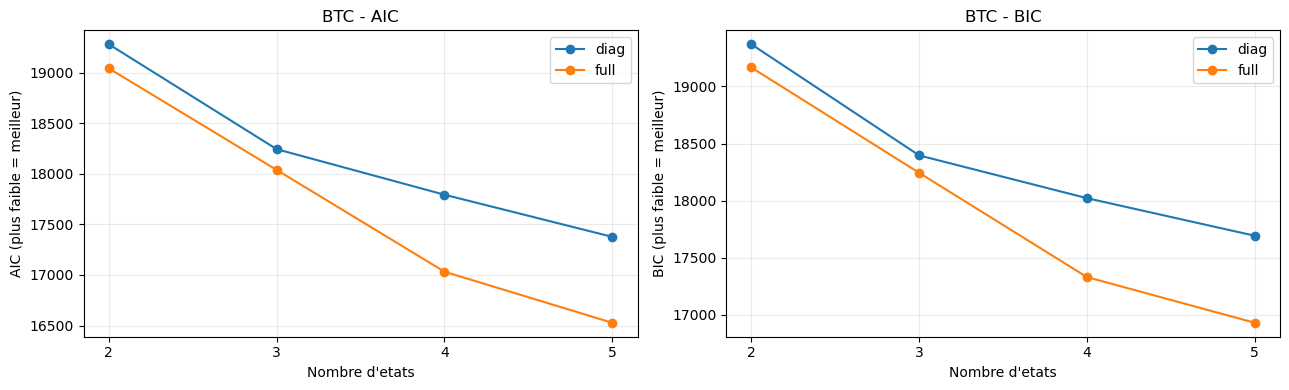

Meilleur BIC : 5 etats - covariance full

===== ETH - CLASSEMENT BIC =====


,Actif,Etats,Covariance,AIC,BIC,LogVraisemblance,Seed,Iterations
15,ETH,5,full,"16,671.03700","17,074.42500","-8,266.51900",42,300
14,ETH,4,full,"17,181.00600","17,479.16200","-8,539.50300",0,96
11,ETH,5,diag,"17,649.66600","17,965.36100","-8,770.83300",23,163
13,ETH,3,full,"17,898.10500","18,102.72200","-8,914.05200",23,213
10,ETH,4,diag,"18,057.54900","18,285.55100","-8,989.77400",0,229
9,ETH,3,diag,"18,547.73700","18,699.73900","-9,247.86900",77,108
12,ETH,2,full,"19,029.28300","19,152.05300","-9,493.64100",0,30
8,ETH,2,diag,"19,414.41600","19,502.10900","-9,692.20800",42,45


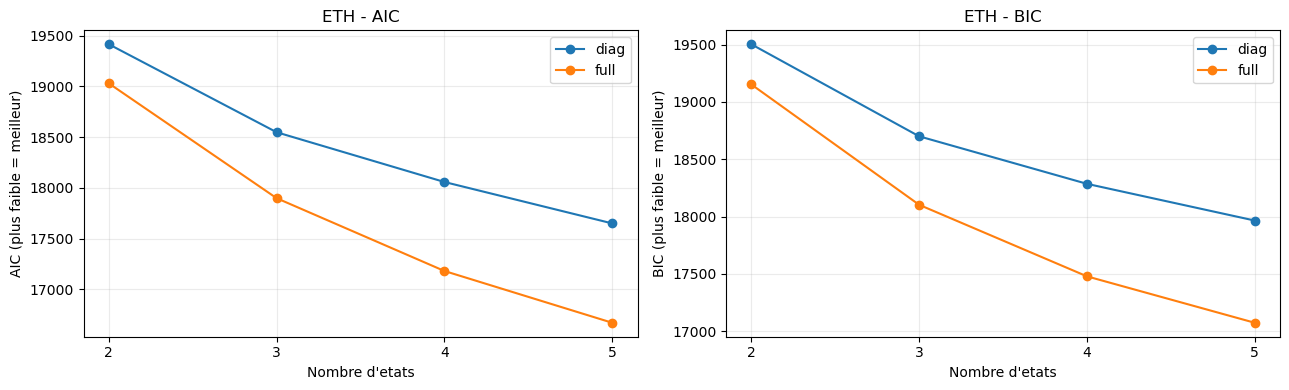

Meilleur BIC : 5 etats - covariance full


In [44]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from hmmlearn.hmm import GaussianHMM

datasets = {
    "BTC": data_btc,
    "ETH": data_eth
}

N_ETATS = [2, 3, 4, 5]
COVARIANCES = ["diag", "full"]
SEEDS = [0, 13, 23, 42, 77]

resultats_hmm = []
modeles_candidats = {}

for actif, data in datasets.items():

    X = data["X_train"]
    modeles_candidats[actif] = {}

    for covariance in COVARIANCES:
        for n in N_ETATS:

            meilleur = None
            meilleur_score = -np.inf
            meilleure_seed = None

            for seed in SEEDS:

                try:
                    modele = GaussianHMM(
                        n_components=n,
                        covariance_type=covariance,
                        n_iter=300,
                        tol=1e-4,
                        min_covar=1e-3,
                        random_state=seed,
                        implementation="scaling"
                    )

                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")
                        modele.fit(X)

                    score = modele.score(X)

                    if (np.isfinite(score)
                            and score > meilleur_score):

                        meilleur = modele
                        meilleur_score = score
                        meilleure_seed = seed

                except (ValueError, np.linalg.LinAlgError):
                    continue

            if meilleur is None:
                print(
                    f"{actif} - {covariance} - "
                    f"{n} etats : echec"
                )
                continue

            modeles_candidats[actif][
                (n, covariance)
            ] = meilleur

            resultats_hmm.append({
                "Actif": actif,
                "Etats": n,
                "Covariance": covariance,
                "AIC": meilleur.aic(X),
                "BIC": meilleur.bic(X),
                "LogVraisemblance": meilleur_score,
                "Seed": meilleure_seed,
                "Iterations": meilleur.monitor_.iter
            })

# Tableau comparatif
comparaison_hmm = pd.DataFrame(resultats_hmm)

for actif in datasets:

    t = comparaison_hmm[
        comparaison_hmm["Actif"] == actif
    ].sort_values("BIC")

    print(f"\n===== {actif} - CLASSEMENT BIC =====")
    display(t.round(3))

    # Graphique AIC et BIC
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 4)
    )

    for covariance in COVARIANCES:

        s = t[
            t["Covariance"] == covariance
        ].sort_values("Etats")

        axes[0].plot(
            s["Etats"], s["AIC"],
            marker="o", label=covariance
        )

        axes[1].plot(
            s["Etats"], s["BIC"],
            marker="o", label=covariance
        )

    for ax, titre in zip(
        axes, ["AIC", "BIC"]
    ):
        ax.set_title(f"{actif} - {titre}")
        ax.set_xlabel("Nombre d'etats")
        ax.set_ylabel(titre + " (plus faible = meilleur)")
        ax.set_xticks(N_ETATS)
        ax.legend()
        ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

    gagnant = t.iloc[0]

    print(
        "Meilleur BIC :",
        int(gagnant["Etats"]),
        "etats - covariance",
        gagnant["Covariance"]
    )


In [45]:

import numpy as np
import pandas as pd

diagnostics = []
occupations = []

for actif, data in [
    ("BTC", data_btc),
    ("ETH", data_eth)
]:
    X = data["X_train"]

    for n in [4, 5]:

        modele = modeles_candidats[actif][(n, "full")]

        # 1. Convergence EM
        historique = list(modele.monitor_.history)

        gain = (
            historique[-1] - historique[-2]
            if len(historique) >= 2
            else np.nan
        )

        stabilise = (
            np.isfinite(gain)
            and 0 <= gain < modele.monitor_.tol
        )

        # 2. Valeurs propres des covariances
        min_eigenvalue = min(
            np.linalg.eigvalsh(cov).min()
            for cov in modele.covars_
        )

        # 3. Occupation probabiliste des etats
        proba = modele.predict_proba(X)
        occupation = 100 * proba.mean(axis=0)

        for k, pct in enumerate(occupation):
            occupations.append({
                "Actif": actif,
                "Etats_modele": n,
                "Etat": k,
                "Occupation_pct": pct
            })

        diagnostics.append({
            "Actif": actif,
            "Etats": n,
            "Iterations": modele.monitor_.iter,
            "Gain_final": gain,
            "Stabilise_selon_tol": stabilise,
            "Valeur_propre_min": min_eigenvalue,
            "Occupation_min_pct": occupation.min(),
            "BIC": modele.bic(X)
        })

print("DIAGNOSTIC DES MODELES FULL")
display(pd.DataFrame(diagnostics).round(5))

print("\nREPARTITION DES ETATS")
display(pd.DataFrame(occupations).round(3))


DIAGNOSTIC DES MODELES FULL


,Actif,Etats,Iterations,Gain_final,Stabilise_selon_tol,Valeur_propre_min,Occupation_min_pct,BIC
0,BTC,4,70,0.00007,True,0.04806,14.75211,"17,330.70443"
1,BTC,5,181,0.00010,True,0.03024,12.78409,"16,930.70585"
2,ETH,4,96,0.00009,True,0.05005,17.11287,"17,479.16169"
3,ETH,5,300,0.00015,False,0.02973,11.62504,"17,074.42521"



REPARTITION DES ETATS


,Actif,Etats_modele,Etat,Occupation_pct
0,BTC,4,0,29.74000
1,BTC,4,1,14.75200
2,BTC,4,2,29.71400
3,BTC,4,3,25.79300
4,BTC,5,0,19.45000
5,BTC,5,1,27.03900
6,BTC,5,2,20.15400
7,BTC,5,3,12.78400
8,BTC,5,4,20.57300
9,ETH,4,0,19.54300



===== BTC =====
Apprentissage : (1825, 3)
Validation : (731, 3)
3 etats | BIC=12976.17 | Validation/jour=-4.5108
4 etats | BIC=12325.98 | Validation/jour=-4.3137
5 etats | BIC=12104.30 | Validation/jour=-4.0990
6 etats | BIC=12036.20 | Validation/jour=-4.0169
7 etats | BIC=11991.23 | Validation/jour=-3.9860
8 etats | BIC=12042.27 | Validation/jour=-3.9934

===== ETH =====
Apprentissage : (1825, 3)
Validation : (731, 3)
3 etats | BIC=12970.98 | Validation/jour=-4.2834
4 etats | BIC=12582.92 | Validation/jour=-4.3306
5 etats | BIC=12331.30 | Validation/jour=-4.0585
6 etats | BIC=12263.61 | Validation/jour=-4.2294
7 etats | BIC=12236.20 | Validation/jour=-4.1320
8 etats | BIC=12246.07 | Validation/jour=-4.0382

===== SELECTION BTC =====


,Actif,Etats,AIC_fit,BIC_fit,LL_validation_par_jour,Occupation_min_pct,Valeur_propre_min,Iterations,Gain_final,Seed
0,BTC,3,"12,783.34375","12,976.17048",-4.51076,21.63604,0.04958,66,0.00009,13
1,BTC,4,"12,045.00557","12,325.98167",-4.31369,16.21647,0.04234,90,0.00009,7
2,BTC,5,"11,724.15939","12,104.30352",-4.09897,13.77555,0.02942,113,0.00010,13
3,BTC,6,"11,545.86685","12,036.19769",-4.01688,7.61116,0.02633,194,0.00010,7
4,BTC,7,"11,379.69274","11,991.22895",-3.98599,9.60237,0.01671,446,0.00010,7
5,BTC,8,"11,298.50806","12,042.26832",-3.99341,3.50519,0.01322,239,0.00010,23


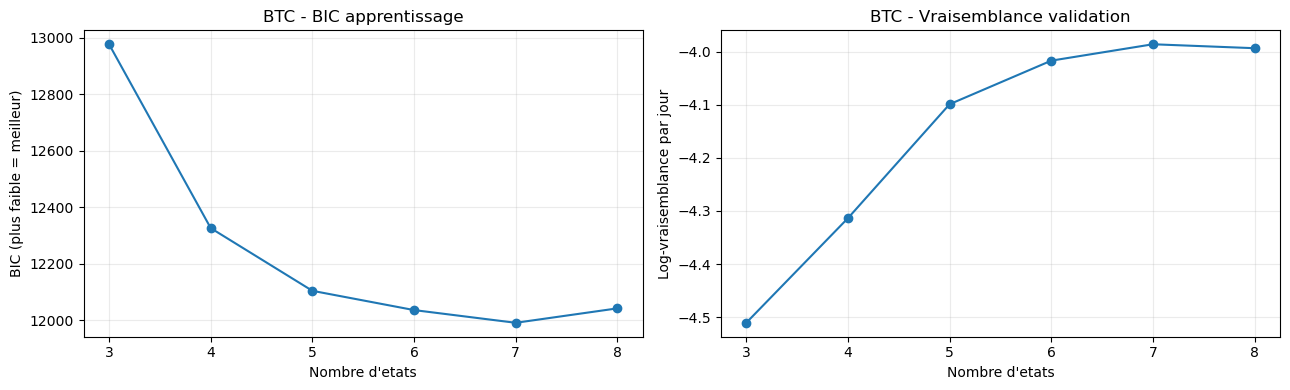

Meilleur nombre d'etats selon BIC : 7
Meilleur nombre d'etats selon validation : 7

===== SELECTION ETH =====


,Actif,Etats,AIC_fit,BIC_fit,LL_validation_par_jour,Occupation_min_pct,Valeur_propre_min,Iterations,Gain_final,Seed
6,ETH,3,"12,778.15578","12,970.98251",-4.28336,24.66332,0.05977,79,0.00008,7
7,ETH,4,"12,301.93950","12,582.91560",-4.33062,15.93129,0.05099,131,0.00009,0
8,ETH,5,"11,951.15591","12,331.30004",-4.05847,12.05341,0.03055,182,0.00010,13
9,ETH,6,"11,773.28077","12,263.61161",-4.22937,10.20256,0.02203,447,0.00009,13
10,ETH,7,"11,624.65998","12,236.19620",-4.13203,9.14281,0.02138,194,0.00010,7
11,ETH,8,"11,502.30946","12,246.06972",-4.03818,6.61986,0.02466,384,0.00010,23


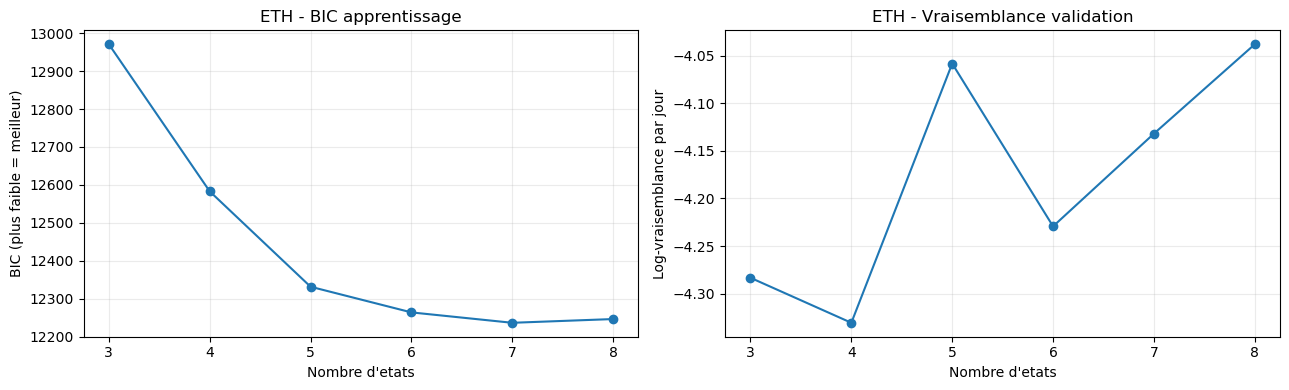

Meilleur nombre d'etats selon BIC : 7
Meilleur nombre d'etats selon validation : 8


In [46]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

N_ETATS = range(3, 9)
SEEDS = [0, 7, 13, 23, 42]
MAX_ITER = 800
TOL = 1e-4

datasets = {
    "BTC": data_btc,
    "ETH": data_eth
}

resultats_selection = []
modeles_validation = {}

for actif, data in datasets.items():

    # Observations non standardisees
    Y = data["Y_train"].sort_index()

    # Nouvelle separation temporelle
    Y_fit = Y.loc[:"2022-12-31"]
    Y_val = Y.loc["2023-01-01":"2024-12-31"]

    # Standardisation sur apprentissage seulement
    scaler = StandardScaler()

    X_fit = scaler.fit_transform(Y_fit)
    X_val = scaler.transform(Y_val)

    modeles_validation[actif] = {}

    print(f"\n===== {actif} =====")
    print("Apprentissage :", X_fit.shape)
    print("Validation :", X_val.shape)

    for n in N_ETATS:

        meilleur = None
        meilleure_ll = -np.inf
        meilleure_seed = None
        meilleur_gain = np.nan

        for seed in SEEDS:

            try:
                modele = GaussianHMM(
                    n_components=n,
                    covariance_type="full",
                    n_iter=MAX_ITER,
                    tol=TOL,
                    min_covar=1e-3,
                    random_state=seed,
                    implementation="scaling"
                )

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    modele.fit(X_fit)

                historique = list(
                    modele.monitor_.history
                )

                if len(historique) < 2:
                    continue

                gain = (
                    historique[-1] - historique[-2]
                )

                # Ne pas retenir un ajustement
                # qui a seulement atteint MAX_ITER
                stabilise = (
                    np.isfinite(gain)
                    and -1e-6 <= gain < TOL
                    and modele.monitor_.iter < MAX_ITER
                )

                if not stabilise:
                    continue

                ll_fit = modele.score(X_fit)

                if not np.isfinite(ll_fit):
                    continue

                if ll_fit > meilleure_ll:
                    meilleur = modele
                    meilleure_ll = ll_fit
                    meilleure_seed = seed
                    meilleur_gain = gain

            except (
                ValueError,
                np.linalg.LinAlgError,
                FloatingPointError
            ):
                continue

        if meilleur is None:
            print(f"{n} etats : aucun ajustement stabilise")
            continue

        # Critères calculés sur apprentissage
        aic = meilleur.aic(X_fit)
        bic = meilleur.bic(X_fit)

        # Vraisemblance sur validation
        ll_val = meilleur.score(X_val)
        ll_val_jour = ll_val / len(X_val)

        # Occupation probabiliste des etats
        proba = meilleur.predict_proba(X_fit)
        occupation = 100 * proba.mean(axis=0)

        # Stabilite des matrices de covariance
        eigen_min = min(
            np.linalg.eigvalsh(cov).min()
            for cov in meilleur.covars_
        )

        modeles_validation[actif][n] = meilleur

        resultats_selection.append({
            "Actif": actif,
            "Etats": n,
            "AIC_fit": aic,
            "BIC_fit": bic,
            "LL_validation_par_jour": ll_val_jour,
            "Occupation_min_pct": occupation.min(),
            "Valeur_propre_min": eigen_min,
            "Iterations": meilleur.monitor_.iter,
            "Gain_final": meilleur_gain,
            "Seed": meilleure_seed
        })

        print(
            f"{n} etats | "
            f"BIC={bic:.2f} | "
            f"Validation/jour={ll_val_jour:.4f}"
        )

# Tableau comparatif final
selection_hmm = pd.DataFrame(resultats_selection)

for actif in datasets:

    t = selection_hmm.loc[
        selection_hmm["Actif"] == actif
    ].sort_values("Etats")

    if t.empty:
        print(f"Aucun modele exploitable pour {actif}")
        continue

    print(f"\n===== SELECTION {actif} =====")
    display(t.round(5))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(
        t["Etats"], t["BIC_fit"],
        marker="o"
    )
    axes[0].set_title(f"{actif} - BIC apprentissage")
    axes[0].set_ylabel("BIC (plus faible = meilleur)")

    axes[1].plot(
        t["Etats"],
        t["LL_validation_par_jour"],
        marker="o"
    )
    axes[1].set_title(
        f"{actif} - Vraisemblance validation"
    )
    axes[1].set_ylabel(
        "Log-vraisemblance par jour"
    )

    for ax in axes:
        ax.set_xlabel("Nombre d'etats")
        ax.set_xticks(t["Etats"])
        ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

    meilleur_bic = t.loc[t["BIC_fit"].idxmin()]
    meilleur_val = t.loc[
        t["LL_validation_par_jour"].idxmax()
    ]

    print(
        "Meilleur nombre d'etats selon BIC :",
        int(meilleur_bic["Etats"])
    )

    print(
        "Meilleur nombre d'etats selon validation :",
        int(meilleur_val["Etats"])
    )


In [47]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

configurations = {
    "BTC": [7],
    "ETH": [7, 8]
}

resume_etats = []
resume_modeles = []

for actif, nombres_etats in configurations.items():

    data = data_btc if actif == "BTC" else data_eth

    # Reproduire uniquement la standardisation
    # utilisee durant la selection 2018-2022
    Y = data["Y_train"].sort_index()

    Y_fit = Y.loc[:"2022-12-31"]
    Y_val = Y.loc["2023-01-01":"2024-12-31"]

    scaler = StandardScaler()
    X_fit = scaler.fit_transform(Y_fit)
    X_val = scaler.transform(Y_val)

    for n in nombres_etats:

        modele = modeles_validation[actif][n]

        # Probabilites des etats
        proba_fit = modele.predict_proba(X_fit)
        occupation = 100 * proba_fit.mean(axis=0)

        # Moyennes des emissions dans les
        # unites financieres originales
        moyennes = scaler.inverse_transform(
            modele.means_
        )

        # Ecarts-types conditionnels du rendement
        ecarts_rendement = (
            np.sqrt(modele.covars_[:, 0, 0])
            * scaler.scale_[0]
        )

        for k in range(n):

            persistance = modele.transmat_[k, k]

            duree = (
                1 / (1 - persistance)
                if persistance < 1
                else np.inf
            )

            resume_etats.append({
                "Actif": actif,
                "Nombre_etats": n,
                "Etat": k,
                "Occupation_pct": occupation[k],
                "Rendement_moyen_pct": moyennes[k, 0],
                "Volatilite_emission_pct":
                    ecarts_rendement[k],
                "LogAmplitude_moyenne": moyennes[k, 1],
                "VariationVolume_moyenne": moyennes[k, 2],
                "Persistance": persistance,
                "Duree_moyenne_jours": duree
            })

        resume_modeles.append({
            "Actif": actif,
            "Etats": n,
            "BIC": modele.bic(X_fit),
            "Validation_2023_par_jour":
                modele.score(
                    X_val[Y_val.index.year == 2023]
                ) / (Y_val.index.year == 2023).sum(),
            "Validation_2024_par_jour":
                modele.score(
                    X_val[Y_val.index.year == 2024]
                ) / (Y_val.index.year == 2024).sum()
        })

tableau_etats = pd.DataFrame(resume_etats)
tableau_stabilite = pd.DataFrame(resume_modeles)

for actif in ["BTC", "ETH"]:

    print(f"\n===== {actif} : ETATS CACHES =====")

    display(
        tableau_etats[
            tableau_etats["Actif"] == actif
        ].round(4)
    )

print("\nCOMPARAISON DES SOUS-PERIODES DE VALIDATION")
display(tableau_stabilite.round(4))



===== BTC : ETATS CACHES =====


,Actif,Nombre_etats,Etat,Occupation_pct,Rendement_moyen_pct,Volatilite_emission_pct,LogAmplitude_moyenne,VariationVolume_moyenne,Persistance,Duree_moyenne_jours
0,BTC,7,0,9.60240,-4.23270,3.12990,2.08430,0.15960,0.09520,1.10520
1,BTC,7,1,15.98800,1.18880,2.12720,1.75330,-0.10630,0.38220,1.61860
2,BTC,7,2,10.65860,-0.58940,8.09740,2.46980,0.02420,0.75700,4.11540
3,BTC,7,3,15.06730,-0.21310,0.73480,0.89610,-0.01540,0.67510,3.07750
4,BTC,7,4,19.15730,1.21520,1.15910,1.31680,-0.05000,0.29090,1.41020
5,BTC,7,5,19.25870,-1.88460,1.65080,1.48520,-0.01750,0.28830,1.40510
6,BTC,7,6,10.26780,4.40150,2.72540,1.85410,0.14020,0.16730,1.20090



===== ETH : ETATS CACHES =====


,Actif,Nombre_etats,Etat,Occupation_pct,Rendement_moyen_pct,Volatilite_emission_pct,LogAmplitude_moyenne,VariationVolume_moyenne,Persistance,Duree_moyenne_jours
7,ETH,7,0,9.53670,-5.04780,4.27500,2.14310,0.20570,0.13510,1.15620
8,ETH,7,1,14.19050,2.69090,1.96910,1.59590,0.07590,0.26780,1.36580
9,ETH,7,2,16.54810,-2.26960,2.88780,2.00070,-0.05260,0.32760,1.48720
10,ETH,7,3,14.09920,5.80720,4.14390,2.25090,0.07360,0.23000,1.29860
11,ETH,7,4,9.14280,-3.08510,9.52190,2.68900,0.01910,0.74540,3.92770
12,ETH,7,5,23.34540,-1.14730,1.32360,1.36300,-0.04270,0.45870,1.84740
13,ETH,7,6,13.13730,1.75250,1.80560,1.65080,-0.18070,0.12140,1.13820
14,ETH,8,0,20.61990,-1.13060,1.24780,1.34720,-0.03050,0.43200,1.76050
15,ETH,8,1,10.89190,-4.61190,3.54600,2.05910,0.14920,0.18290,1.22380
16,ETH,8,2,13.79150,-2.27450,2.64780,1.99010,-0.05750,0.28420,1.39700



COMPARAISON DES SOUS-PERIODES DE VALIDATION


,Actif,Etats,BIC,Validation_2023_par_jour,Validation_2024_par_jour
0,BTC,7,"11,991.22900",-3.76760,-4.22180
1,ETH,7,"12,236.19620",-4.38160,-3.92060
2,ETH,8,"12,246.06970",-4.24820,-3.87440



===== BTC - 7 ETATS =====
Episodes : 488
Duree mediane : 1.0
Duree maximale : 8


,count,mean,median,max
Etat,,,,
0,56,1.16000,1.00000,2
1,51,1.43000,1.00000,4
2,13,1.85000,1.00000,4
3,57,1.96000,1.00000,8
4,163,1.69000,1.00000,8
5,112,1.25000,1.00000,4
6,36,1.14000,1.00000,3


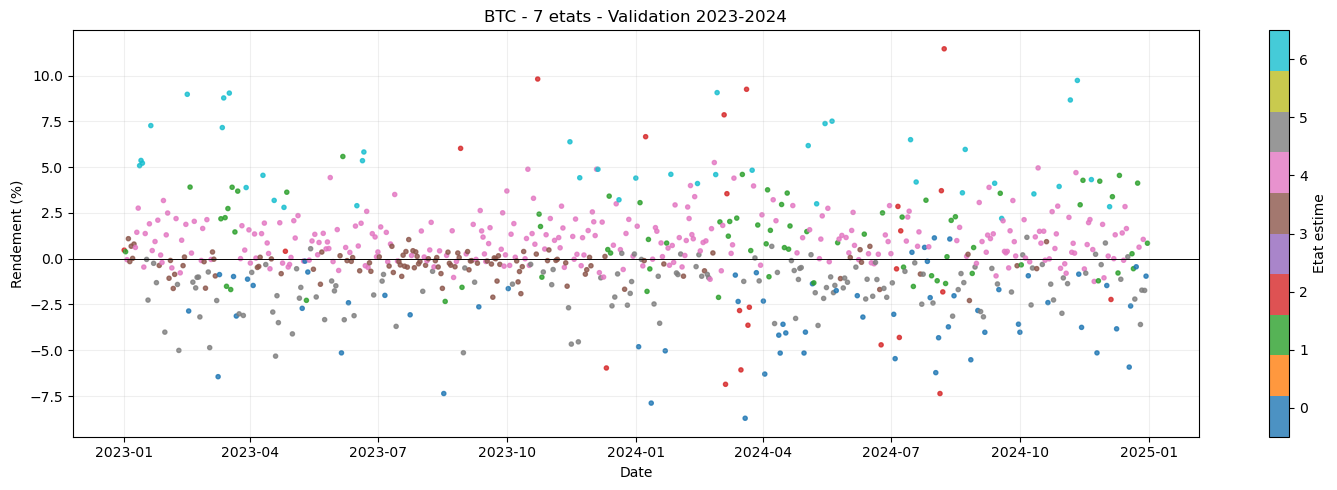


===== ETH - 7 ETATS =====
Episodes : 515
Duree mediane : 1.0
Duree maximale : 11


,count,mean,median,max
Etat,,,,
0,88,1.09000,1.00000,3
1,99,1.26000,1.00000,4
2,46,1.33000,1.00000,3
3,35,1.17000,1.00000,3
4,4,2.75000,3.00000,4
5,131,2.02000,1.00000,11
6,112,1.19000,1.00000,3


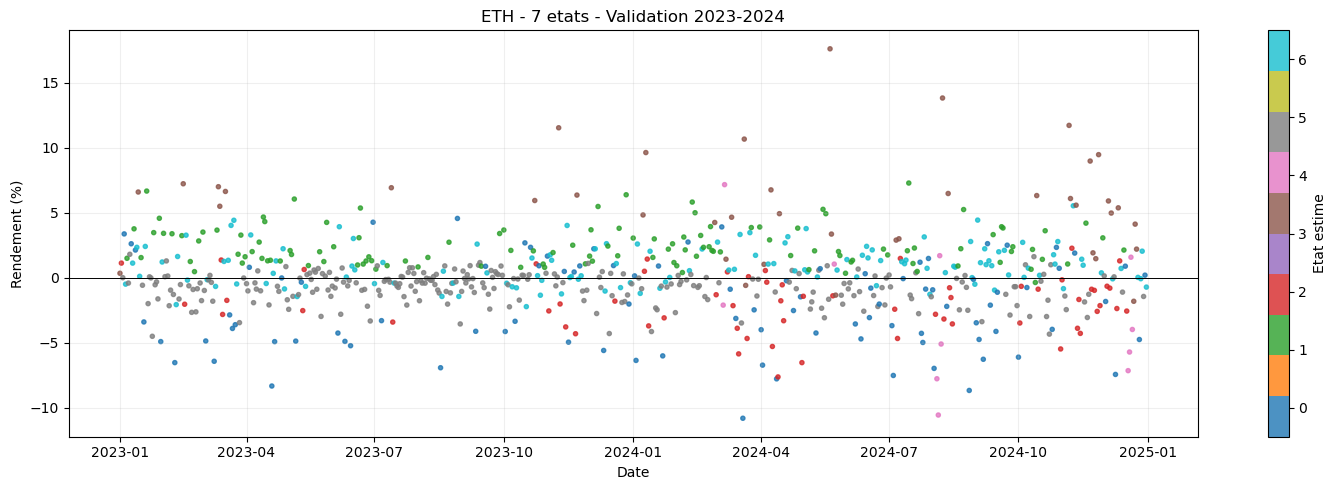


===== ETH - 8 ETATS =====
Episodes : 508
Duree mediane : 1.0
Duree maximale : 8


,count,mean,median,max
Etat,,,,
0,140,1.56000,1.00000,6
1,71,1.18000,1.00000,4
2,31,1.32000,1.00000,3
3,87,1.29000,1.00000,3
4,20,1.20000,1.00000,2
5,134,1.65000,1.00000,8
6,12,1.25000,1.00000,2
7,13,1.23000,1.00000,3


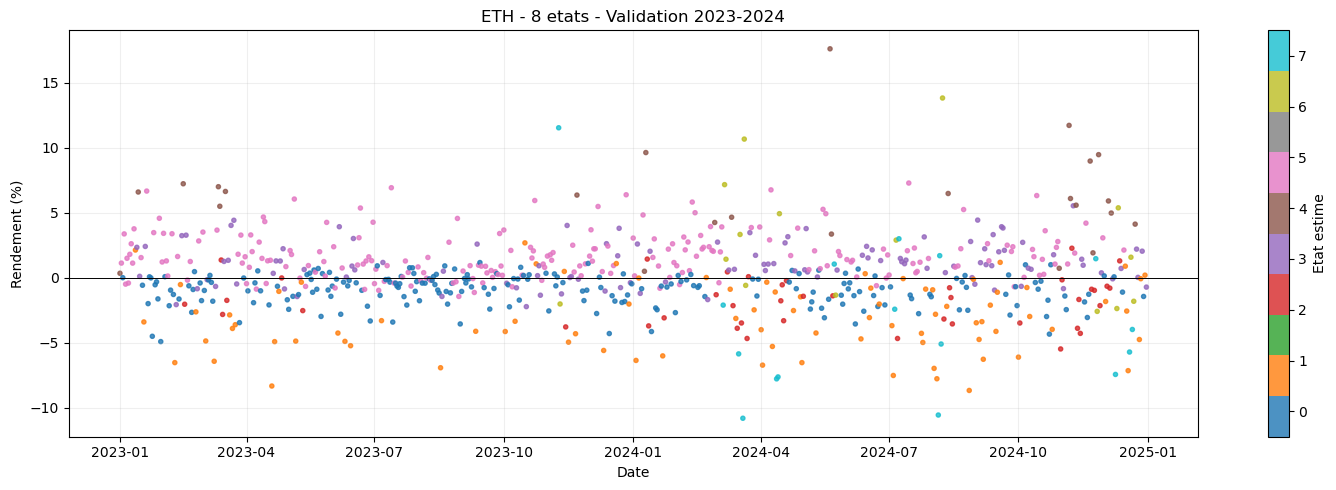

In [48]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

configurations = [
    ("BTC", 7),
    ("ETH", 7),
    ("ETH", 8)
]

for actif, n in configurations:

    data = data_btc if actif == "BTC" else data_eth
    modele = modeles_validation[actif][n]

    Y = data["Y_train"].sort_index()

    Y_fit = Y.loc[:"2022-12-31"]
    Y_val = Y.loc["2023-01-01":"2024-12-31"]

    # Reproduire le scaler de l'apprentissage
    scaler = StandardScaler()
    scaler.fit(Y_fit)

    X_val = scaler.transform(Y_val)

    # Etats Viterbi sur la validation complete
    etats = modele.predict(X_val)

    # Longueurs des episodes consecutifs
    changements = np.r_[
        True, etats[1:] != etats[:-1]
    ]
    ids_episodes = np.cumsum(changements)

    episodes = pd.DataFrame({
        "Etat": etats,
        "Episode": ids_episodes
    }).groupby("Episode").agg(
        Etat=("Etat", "first"),
        Duree=("Etat", "size")
    )

    print(f"\n===== {actif} - {n} ETATS =====")
    print("Episodes :", len(episodes))
    print("Duree mediane :", episodes["Duree"].median())
    print("Duree maximale :", episodes["Duree"].max())

    display(
        episodes.groupby("Etat")["Duree"]
        .agg(["count", "mean", "median", "max"])
        .round(2)
    )

    # Rendements colores par etat
    fig, ax = plt.subplots(figsize=(15, 5))

    graphique = ax.scatter(
        Y_val.index,
        Y_val["Rendement"],
        c=etats,
        cmap="tab10",
        vmin=-0.5,
        vmax=n-0.5,
        s=9,
        alpha=0.8
    )

    ax.axhline(0, color="black", linewidth=0.7)
    ax.set_title(
        f"{actif} - {n} etats - Validation 2023-2024"
    )
    ax.set_xlabel("Date")
    ax.set_ylabel("Rendement (%)")
    ax.grid(alpha=0.2)

    plt.colorbar(
        graphique, ax=ax,
        ticks=range(n),
        label="Etat estime"
    )

    plt.tight_layout()
    plt.show()


In [49]:

import numpy as np
import warnings

from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

configurations_finales = {
    "BTC": 7,
    "ETH": 8
}

donnees = {
    "BTC": data_btc,
    "ETH": data_eth
}

hmm_finaux = {}

for actif, n_etats in configurations_finales.items():

    Y_train = donnees[actif]["Y_train"]
    Y_test = donnees[actif]["Y_test"]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(Y_train)
    X_test = scaler.transform(Y_test)

    meilleur = None
    meilleur_score = -np.inf
    meilleure_seed = None

    for seed in [7, 13, 23, 42, 77]:

        try:
            modele = GaussianHMM(
                n_components=n_etats,
                covariance_type="full",
                n_iter=800,
                tol=1e-4,
                min_covar=1e-3,
                random_state=seed,
                implementation="scaling"
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                modele.fit(X_train)

            historique = list(modele.monitor_.history)

            if len(historique) < 2:
                continue

            gain = historique[-1] - historique[-2]

            stabilise = (
                -1e-6 <= gain < 1e-4
                and modele.monitor_.iter < 800
            )

            if not stabilise:
                continue

            score = modele.score(X_train)

            if np.isfinite(score) and score > meilleur_score:
                meilleur = modele
                meilleur_score = score
                meilleure_seed = seed

        except (ValueError, np.linalg.LinAlgError):
            continue

    if meilleur is None:
        raise RuntimeError(
            f"{actif} : aucun HMM stabilise"
        )

    hmm_finaux[actif] = {
        "modele": meilleur,
        "scaler": scaler,
        "X_train": X_train,
        "X_test": X_test,
        "Y_train": Y_train,
        "Y_test": Y_test
    }

    print(f"\n===== {actif} =====")
    print("Nombre d'etats :", n_etats)
    print("Meilleure seed :", meilleure_seed)
    print("Iterations :", meilleur.monitor_.iter)
    print("BIC train :", round(meilleur.bic(X_train), 3))
    print("Observations test :", len(X_test))



===== BTC =====
Nombre d'etats : 7
Meilleure seed : 77
Iterations : 385
BIC train : 16593.883
Observations test : 687

===== ETH =====
Nombre d'etats : 8
Meilleure seed : 13
Iterations : 302
BIC train : 16736.716
Observations test : 687


In [50]:

import pandas as pd

for actif, resultat in hmm_finaux.items():

    modele = resultat["modele"]
    X_train = resultat["X_train"]

    historique = list(modele.monitor_.history)
    gain_final = historique[-1] - historique[-2]

    print(f"\n===== {actif} - DIAGNOSTIC FINAL =====")
    print("Nombre d'états :", modele.n_components)
    print("Type de covariance :", modele.covariance_type)
    print("Itérations :", modele.monitor_.iter)
    print("Gain final :", round(gain_final, 8))
    print("Log-vraisemblance :", round(modele.score(X_train), 3))
    print("AIC :", round(modele.aic(X_train), 3))
    print("BIC :", round(modele.bic(X_train), 3))

    print("\nProbabilités initiales :")
    print(modele.startprob_.round(4))

    print("\nMatrice de transition :")
    display(
        pd.DataFrame(modele.transmat_).round(4)
    )



===== BTC - DIAGNOSTIC FINAL =====
Nombre d'états : 7
Type de covariance : full
Itérations : 385
Gain final : 9.206e-05
Log-vraisemblance : -7861.478
AIC : 15944.955
BIC : 16593.883

Probabilités initiales :
[0. 0. 0. 0. 0. 1. 0.]

Matrice de transition :


,0,1,2,3,4,5,6
0,0.31830,0.12960,0.00670,0.34370,0.08850,0.00970,0.10350
1,0.30090,0.06940,0.10600,0.00000,0.21290,0.03430,0.27640
2,0.00000,0.00000,0.51600,0.00410,0.34250,0.11350,0.02400
3,0.23260,0.16100,0.00000,0.58620,0.02020,0.00000,0.00000
4,0.10710,0.02560,0.16550,0.00400,0.21410,0.00510,0.47870
5,0.00000,0.00000,0.37430,0.00000,0.00000,0.62570,0.00000
6,0.28030,0.05260,0.01820,0.00500,0.24610,0.00000,0.39790



===== ETH - DIAGNOSTIC FINAL =====
Nombre d'états : 8
Type de covariance : full
Itérations : 302
Gain final : 9.932e-05
Log-vraisemblance : -7838.739
AIC : 15947.479
BIC : 16736.716

Probabilités initiales :
[1. 0. 0. 0. 0. 0. 0. 0.]

Matrice de transition :


,0,1,2,3,4,5,6,7
0,0.21600,0.00000,0.61190,0.05780,0.00870,0.10560,0.00000,0.00000
1,0.04870,0.04430,0.27650,0.01740,0.12850,0.41860,0.06230,0.00370
2,0.20570,0.00000,0.34760,0.07460,0.00000,0.36300,0.00000,0.00910
3,0.25530,0.00000,0.03680,0.70780,0.00000,0.00000,0.00000,0.00000
4,0.02860,0.16450,0.00000,0.01010,0.35640,0.16160,0.27890,0.00000
5,0.04010,0.04960,0.10750,0.00000,0.44030,0.24370,0.11380,0.00510
6,0.03620,0.09370,0.00000,0.00820,0.22150,0.04170,0.26900,0.32960
7,0.02130,0.11590,0.00000,0.00000,0.00000,0.00000,0.24330,0.61950


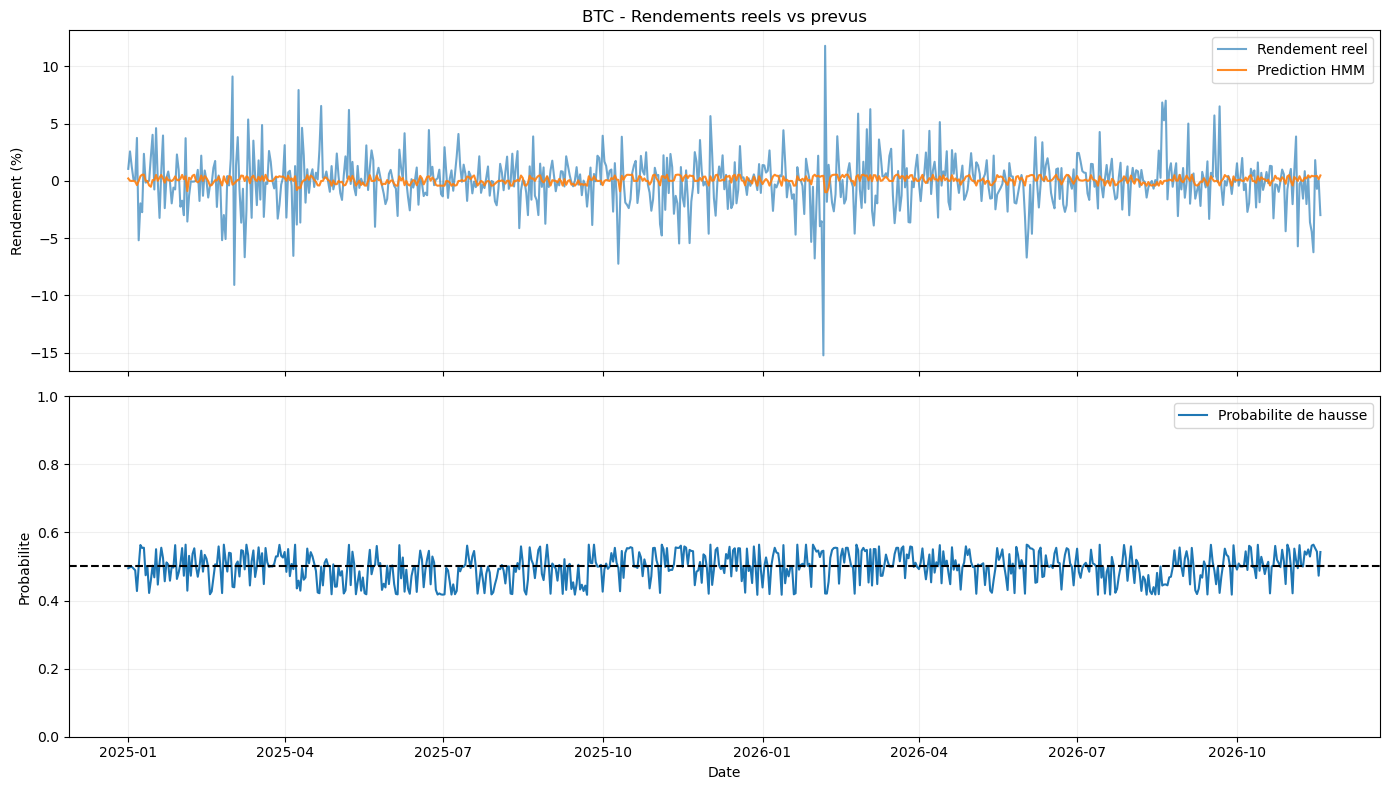


===== BTC =====
Dernieres predictions du test :


,Rendement_reel,Rendement_prevu,P_hausse,Volatilite_predictive,Etat_prevu,Log_score
Date,,,,,,
2026-11-09,0.85240,0.29540,0.54420,3.33810,0,-1.88570
2026-11-10,-2.01830,0.22100,0.53480,3.14550,0,-2.53120
2026-11-11,0.33090,0.48830,0.55010,2.99280,6,-1.87050
2026-11-12,-3.60860,0.29880,0.52910,2.83860,0,-3.32620
2026-11-13,-4.43320,0.44970,0.56120,3.31800,6,-3.67670
2026-11-14,-6.22850,0.40700,0.56400,3.47200,0,-4.40470
2026-11-15,1.81880,0.42180,0.55340,4.23930,2,-2.22180
2026-11-16,-0.69030,0.43460,0.54360,4.82710,2,-2.39150
2026-11-17,0.05870,0.14580,0.47290,3.13040,6,-1.93850


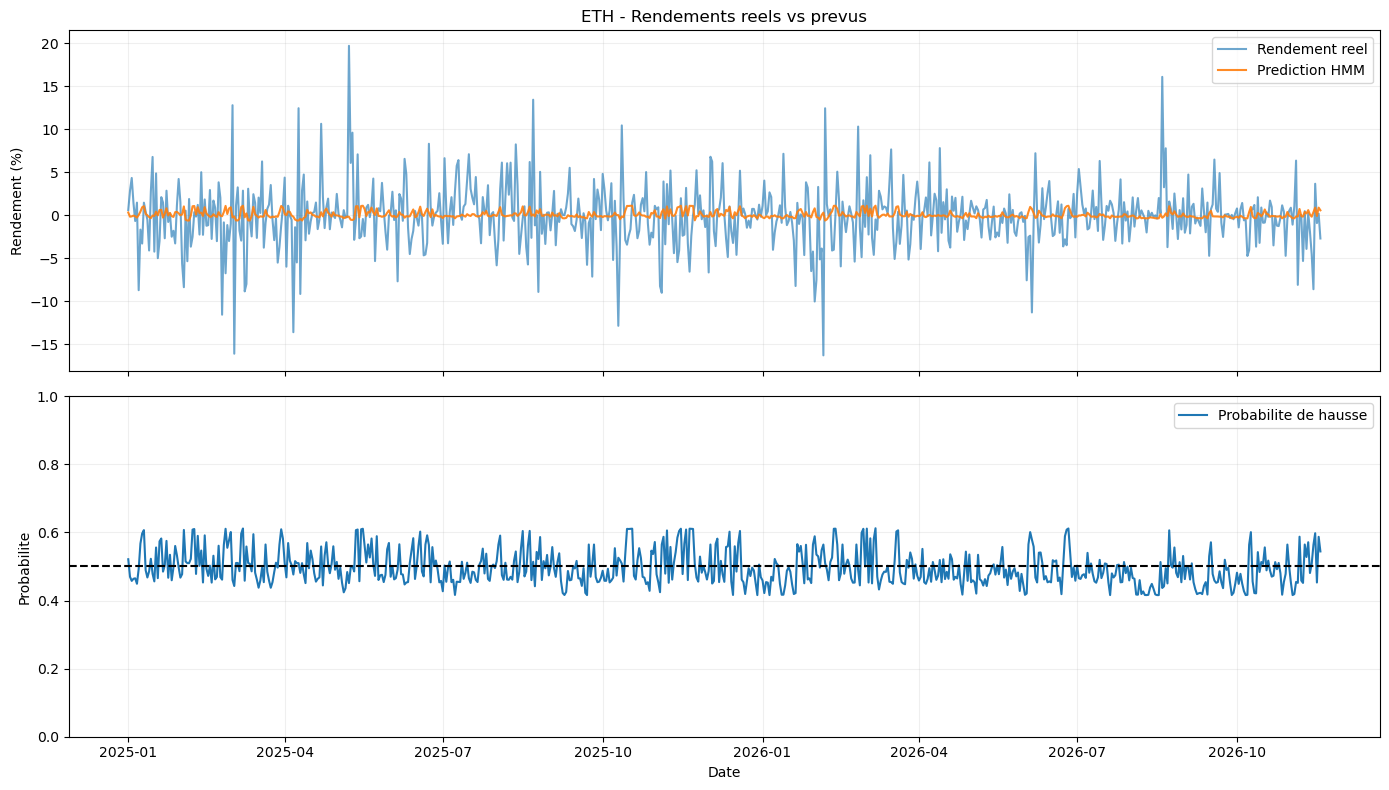


===== ETH =====
Dernieres predictions du test :


,Rendement_reel,Rendement_prevu,P_hausse,Volatilite_predictive,Etat_prevu,Log_score
Date,,,,,,
2026-11-09,0.49470,0.39980,0.56450,4.06390,5,-2.29780
2026-11-10,-3.88970,0.22590,0.52790,3.80260,5,-3.21130
2026-11-11,0.27740,0.61590,0.57120,4.73530,5,-2.35300
2026-11-12,-1.91750,0.10130,0.48080,3.62970,4,-2.08490
2026-11-13,-4.52570,-0.14640,0.50790,3.77660,4,-3.57620
2026-11-14,-8.57870,0.39010,0.56350,4.06020,5,-4.74100
2026-11-15,3.68320,0.90740,0.59770,5.08870,5,-2.49180
2026-11-16,-0.88760,-0.06560,0.45290,4.93300,2,-2.27600
2026-11-17,0.20240,0.90680,0.58700,5.08460,5,-2.47230



EVALUATION HORS ECHANTILLON


,Actif,Etats,RMSE_HMM,RMSE_Base,MAE_HMM,MAE_Base,Accuracy_HMM,Accuracy_Base,ROC_AUC,Brier_HMM,Brier_Base,LogScore_HMM,LogScore_Base
0,BTC,7,2.30894,2.28160,1.60819,1.59215,0.50655,0.48908,0.51150,0.25097,0.25049,-2.18612,-2.39518
1,ETH,8,3.63675,3.59114,2.49451,2.45165,0.49054,0.50655,0.47477,0.25457,0.24997,-2.64653,-2.74770


In [51]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm, multivariate_normal
from scipy.special import logsumexp
from sklearn.metrics import roc_auc_score

resultats_prediction = {}
mesures_performance = []

for actif, data in hmm_finaux.items():

    modele = data["modele"]
    scaler = data["scaler"]

    X_train = data["X_train"]
    X_test = data["X_test"]

    Y_train = data["Y_train"]
    Y_test = data["Y_test"]

    # Parametres gaussiens en espace standardise
    mu = modele.means_
    cov = modele.covars_

    # Parametres du rendement en unites originales
    mu_r = (
        mu[:, 0] * scaler.scale_[0]
        + scaler.mean_[0]
    )

    sigma_r = (
        np.sqrt(cov[:, 0, 0])
        * scaler.scale_[0]
    )

    # Distribution des etats a la fin du train
    posterior = modele.predict_proba(X_train)[-1]

    lignes = []

    for date, x, rendement_reel in zip(
        Y_test.index,
        X_test,
        Y_test["Rendement"].to_numpy()
    ):

        # A. Prediction AVANT observation du jour
        prior = posterior @ modele.transmat_
        prior = np.maximum(prior, 1e-300)
        prior = prior / prior.sum()

        rendement_prevu = np.dot(prior, mu_r)

        # Probabilite predictive de hausse
        p_hausse = np.dot(
            prior,
            norm.sf(0, loc=mu_r, scale=sigma_r)
        )

        # Incertitude predictive du rendement
        variance_prevue = (
            np.dot(prior, sigma_r**2 + mu_r**2)
            - rendement_prevu**2
        )

        sigma_prevu = np.sqrt(
            max(variance_prevue, 0)
        )

        # Log-densite predictive du rendement
        log_score = logsumexp(
            np.log(prior)
            + norm.logpdf(
                rendement_reel,
                loc=mu_r,
                scale=sigma_r
            )
        )

        # B. Observer le jour, puis actualiser
        # les etats pour la prevision suivante
        log_emissions = np.array([
            multivariate_normal.logpdf(
                x,
                mean=mu[k],
                cov=cov[k]
            )
            for k in range(modele.n_components)
        ])

        log_posterior = (
            np.log(prior) + log_emissions
        )

        posterior = np.exp(
            log_posterior
            - logsumexp(log_posterior)
        )

        lignes.append({
            "Date": date,
            "Rendement_reel": rendement_reel,
            "Rendement_prevu": rendement_prevu,
            "P_hausse": p_hausse,
            "Volatilite_predictive": sigma_prevu,
            "Etat_prevu": int(np.argmax(prior)),
            "Log_score": log_score
        })

    pred = pd.DataFrame(lignes).set_index("Date")
    resultats_prediction[actif] = pred

    # C. Baseline sur train uniquement
    r_train = Y_train["Rendement"].to_numpy()
    r_test = pred["Rendement_reel"].to_numpy()

    mu_base = r_train.mean()
    sigma_base = r_train.std(ddof=1)
    p_base = np.mean(r_train > 0)

    r_pred = pred["Rendement_prevu"].to_numpy()
    p_pred = pred["P_hausse"].to_numpy()
    y = (r_test > 0).astype(int)

    # D. Metriques
    rmse_hmm = np.sqrt(np.mean((r_test-r_pred)**2))
    rmse_base = np.sqrt(np.mean((r_test-mu_base)**2))

    mae_hmm = np.mean(np.abs(r_test-r_pred))
    mae_base = np.mean(np.abs(r_test-mu_base))

    accuracy_hmm = np.mean((p_pred >= 0.5) == y)
    accuracy_base = np.mean((p_base >= 0.5) == y)

    brier_hmm = np.mean((p_pred-y)**2)
    brier_base = np.mean((p_base-y)**2)

    auc = (
        roc_auc_score(y, p_pred)
        if len(np.unique(y)) == 2
        else np.nan
    )

    mesures_performance.append({
        "Actif": actif,
        "Etats": modele.n_components,
        "RMSE_HMM": rmse_hmm,
        "RMSE_Base": rmse_base,
        "MAE_HMM": mae_hmm,
        "MAE_Base": mae_base,
        "Accuracy_HMM": accuracy_hmm,
        "Accuracy_Base": accuracy_base,
        "ROC_AUC": auc,
        "Brier_HMM": brier_hmm,
        "Brier_Base": brier_base,
        "LogScore_HMM": pred["Log_score"].mean(),
        "LogScore_Base": norm.logpdf(
            r_test, loc=mu_base,
            scale=sigma_base
        ).mean()
    })

    # E. Visualisation
    fig, axes = plt.subplots(
        2, 1, figsize=(14, 8),
        sharex=True
    )

    axes[0].plot(
        pred.index, pred["Rendement_reel"],
        label="Rendement reel", alpha=0.65
    )
    axes[0].plot(
        pred.index, pred["Rendement_prevu"],
        label="Prediction HMM", alpha=0.9
    )
    axes[0].set_title(
        f"{actif} - Rendements reels vs prevus"
    )
    axes[0].set_ylabel("Rendement (%)")
    axes[0].legend()
    axes[0].grid(alpha=0.2)

    axes[1].plot(
        pred.index, pred["P_hausse"],
        label="Probabilite de hausse"
    )
    axes[1].axhline(
        0.5, color="black", linestyle="--"
    )
    axes[1].set_ylim(0, 1)
    axes[1].set_ylabel("Probabilite")
    axes[1].set_xlabel("Date")
    axes[1].legend()
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    print(f"\n===== {actif} =====")
    print("Dernieres predictions du test :")
    display(pred.tail(10).round(4))

tableau_performance = pd.DataFrame(
    mesures_performance
)

print("\nEVALUATION HORS ECHANTILLON")
display(tableau_performance.round(5))


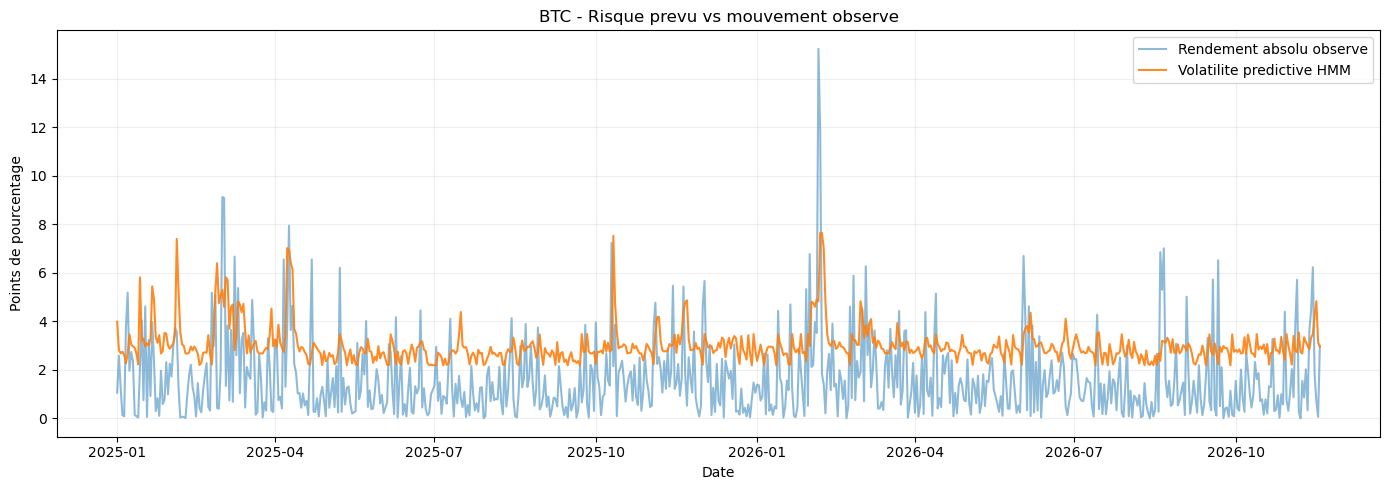

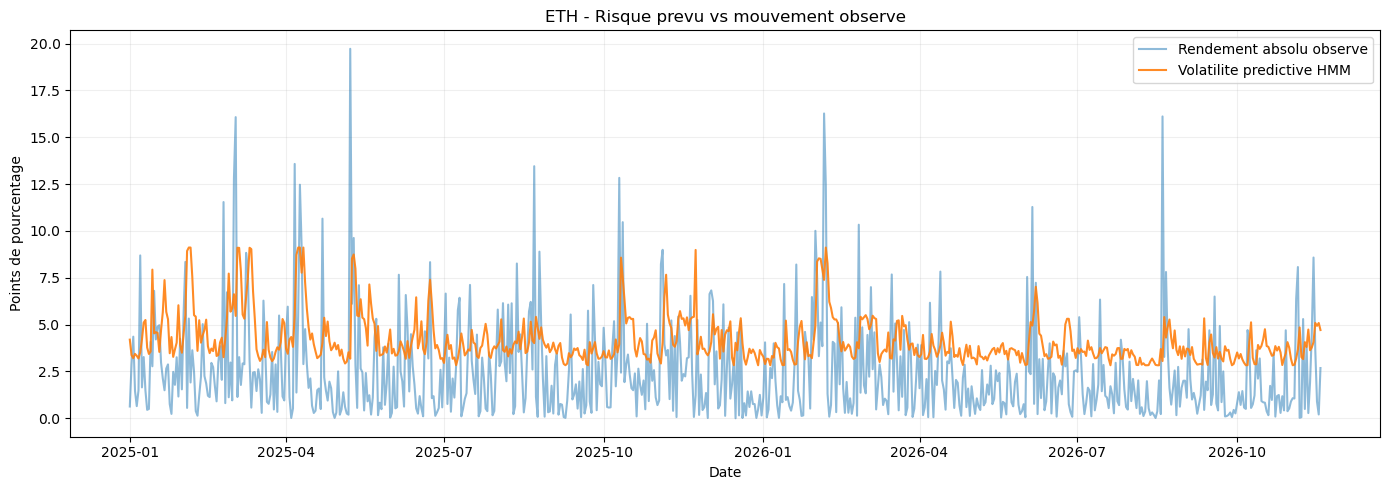

EVALUATION DE LA VOLATILITE PREDICTIVE


,Actif,QLIKE_HMM,QLIKE_Reference,Difference_QLIKE,Correlation_volatilite_abs_rendement
0,BTC,2.69473,2.95248,-0.25776,0.29799
1,ETH,3.56808,3.65751,-0.08944,0.21615


In [52]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

resultats_risque = []

for actif, pred in resultats_prediction.items():

    r = pred["Rendement_reel"].to_numpy()
    mu = pred["Rendement_prevu"].to_numpy()

    # Variance predictive HMM
    variance_hmm = np.maximum(
        pred["Volatilite_predictive"].to_numpy()**2,
        1e-8
    )

    # Reference : moyenne et variance train
    train = hmm_finaux[actif]["Y_train"]["Rendement"]

    mu_base = train.mean()
    variance_base = train.var(ddof=1)

    # QLIKE avec moyenne predictive
    qlike_hmm = np.mean(
        np.log(variance_hmm) +
        (r - mu)**2 / variance_hmm
    )

    qlike_base = np.mean(
        np.log(variance_base) +
        (r - mu_base)**2 / variance_base
    )

    # Rapport entre incertitude prevue et
    # amplitude effectivement observee
    correlation = np.corrcoef(
        np.sqrt(variance_hmm),
        np.abs(r)
    )[0, 1]

    resultats_risque.append({
        "Actif": actif,
        "QLIKE_HMM": qlike_hmm,
        "QLIKE_Reference": qlike_base,
        "Difference_QLIKE": qlike_hmm - qlike_base,
        "Correlation_volatilite_abs_rendement":
            correlation
    })

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        pred.index,
        np.abs(r),
        label="Rendement absolu observe",
        alpha=0.5
    )

    ax.plot(
        pred.index,
        np.sqrt(variance_hmm),
        label="Volatilite predictive HMM",
        alpha=0.9
    )

    ax.set_title(
        f"{actif} - Risque prevu vs mouvement observe"
    )
    ax.set_ylabel("Points de pourcentage")
    ax.set_xlabel("Date")
    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

tableau_risque = pd.DataFrame(resultats_risque)

print("EVALUATION DE LA VOLATILITE PREDICTIVE")
display(tableau_risque.round(5))


In [53]:

import numpy as np
import pandas as pd

comparaison_risque = []

for actif, pred in resultats_prediction.items():

    train = hmm_finaux[actif]["Y_train"]["Rendement"]
    test = pred["Rendement_reel"]

    # Historique complet, ordonne chronologiquement
    historique = pd.concat([train, test]).sort_index()

    # Reference dynamique : uniquement les 30 jours precedents
    moyenne_30 = (
        historique.rolling(30).mean().shift(1)
        .reindex(pred.index)
    )

    variance_30 = (
        historique.rolling(30).var().shift(1)
        .reindex(pred.index)
    )

    # Previsions HMM existantes
    r = test.to_numpy()
    mu_hmm = pred["Rendement_prevu"].to_numpy()

    var_hmm = np.maximum(
        pred["Volatilite_predictive"].to_numpy()**2,
        1e-8
    )

    # Reference historique
    mu_30 = moyenne_30.to_numpy()
    var_30 = np.maximum(variance_30.to_numpy(), 1e-8)

    # Reference constante
    mu_const = train.mean()
    var_const = train.var(ddof=1)

    # Meme fonction de perte pour les trois methodes
    def qlike(r, mu, variance):
        return np.mean(
            np.log(variance) + (r - mu)**2 / variance
        )

    comparaison_risque.append({
        "Actif": actif,
        "QLIKE_HMM": qlike(r, mu_hmm, var_hmm),
        "QLIKE_30j": qlike(r, mu_30, var_30),
        "QLIKE_Constant": qlike(r, mu_const, var_const)
    })

tableau_comparaison_risque = pd.DataFrame(
    comparaison_risque
)

tableau_comparaison_risque["Meilleure_methode"] = (
    tableau_comparaison_risque[
        ["QLIKE_HMM", "QLIKE_30j", "QLIKE_Constant"]
    ].idxmin(axis=1)
)

print("COMPARAISON DES METHODES DE PREVISION DU RISQUE")
display(tableau_comparaison_risque.round(5))


COMPARAISON DES METHODES DE PREVISION DU RISQUE


,Actif,QLIKE_HMM,QLIKE_30j,QLIKE_Constant,Meilleure_methode
0,BTC,2.69473,2.72093,2.95248,QLIKE_HMM
1,ETH,3.56808,3.70253,3.65751,QLIKE_HMM


In [54]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

FEATURES_4 = [
    "Rendement",
    "Log_Amplitude",
    "Variation_LogVolume",
    "Log_Volatilite_30j"
]

def preparer_hmm_avec_volatilite(df, actif):

    d = df.copy()

    d["Date"] = pd.to_datetime(d["Date"])
    d = d.sort_values("Date").reset_index(drop=True)

    # 1. Rendement
    d["Rendement"] = d["R_Close_Close"]

    # 2. Amplitude quotidienne
    d["Log_Amplitude"] = np.log1p(
        d["Amplitude_High_Low"]
    )

    # 3. Variation du volume
    d["Variation_LogVolume"] = (
        np.log1p(d["Volume"]).diff()
    )

    # 4. Volatilite historique 30 jours
    d["Volatilite_30j"] = (
        d["Rendement"]
        .rolling(window=30, min_periods=30)
        .std()
    )

    # 5. Transformation logarithmique
    d["Log_Volatilite_30j"] = np.log1p(
        d["Volatilite_30j"]
    )

    # Matrice d'observations
    Y = (
        d[["Date"] + FEATURES_4]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .set_index("Date")
    )

    # Apprentissage exploratoire
    Y_fit = Y.loc[:"2022-12-31"].copy()

    # Validation chronologique
    Y_val = Y.loc[
        "2023-01-01":"2024-12-31"
    ].copy()

    # Test conserve pour plus tard
    Y_test = Y.loc["2025-01-01":].copy()

    scaler = StandardScaler()

    X_fit = scaler.fit_transform(Y_fit)
    X_val = scaler.transform(Y_val)
    X_test = scaler.transform(Y_test)

    print(f"\n===== {actif} =====")
    print("Features :", FEATURES_4)
    print("Apprentissage :", X_fit.shape)
    print("Validation :", X_val.shape)
    print("Test :", X_test.shape)

    print("\nMatrice de correlation :")
    display(Y_fit.corr().round(4))

    return {
        "Y_fit": Y_fit,
        "Y_val": Y_val,
        "Y_test": Y_test,
        "X_fit": X_fit,
        "X_val": X_val,
        "X_test": X_test,
        "scaler": scaler
    }


data_btc_vol = preparer_hmm_avec_volatilite(
    btc_analyse, "Bitcoin"
)

data_eth_vol = preparer_hmm_avec_volatilite(
    eth_analyse, "Ethereum"
)



===== Bitcoin =====
Features : ['Rendement', 'Log_Amplitude', 'Variation_LogVolume', 'Log_Volatilite_30j']
Apprentissage : (1796, 4)
Validation : (731, 4)
Test : (687, 4)

Matrice de correlation :


,Rendement,Log_Amplitude,Variation_LogVolume,Log_Volatilite_30j
Rendement,1.00000,-0.06270,0.02960,-0.01620
Log_Amplitude,-0.06270,1.00000,0.36980,0.52200
Variation_LogVolume,0.02960,0.36980,1.00000,-0.01410
Log_Volatilite_30j,-0.01620,0.52200,-0.01410,1.00000



===== Ethereum =====
Features : ['Rendement', 'Log_Amplitude', 'Variation_LogVolume', 'Log_Volatilite_30j']
Apprentissage : (1796, 4)
Validation : (731, 4)
Test : (687, 4)

Matrice de correlation :


,Rendement,Log_Amplitude,Variation_LogVolume,Log_Volatilite_30j
Rendement,1.00000,-0.09850,-0.00660,-0.03360
Log_Amplitude,-0.09850,1.00000,0.41210,0.38740
Variation_LogVolume,-0.00660,0.41210,1.00000,-0.02140
Log_Volatilite_30j,-0.03360,0.38740,-0.02140,1.00000


In [55]:

import numpy as np
import pandas as pd
import warnings

from hmmlearn.hmm import GaussianHMM

modeles_avec_vol = {}

configurations = {
    "BTC": (data_btc_vol, 7),
    "ETH": (data_eth_vol, 8)
}

for actif, (data, n_etats) in configurations.items():

    X = data["X_fit"]

    meilleur = None
    meilleur_score = -np.inf
    meilleure_seed = None

    for seed in [0, 7, 13, 23, 42, 77]:

        try:
            modele = GaussianHMM(
                n_components=n_etats,
                covariance_type="full",
                n_iter=1000,
                tol=1e-4,
                min_covar=1e-3,
                random_state=seed,
                implementation="scaling"
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                modele.fit(X)

            historique = list(modele.monitor_.history)

            if len(historique) < 2:
                continue

            gain = historique[-1] - historique[-2]

            if not (
                np.isfinite(gain)
                and -1e-6 <= gain < 1e-4
                and modele.monitor_.iter < 1000
            ):
                continue

            score = modele.score(X)

            if np.isfinite(score) and score > meilleur_score:
                meilleur = modele
                meilleur_score = score
                meilleure_seed = seed

        except (ValueError, np.linalg.LinAlgError):
            continue

    if meilleur is None:
        raise RuntimeError(
            f"{actif}: aucun modele stabilise"
        )

    modeles_avec_vol[actif] = {
        "modele": meilleur,
        "data": data,
        "seed": meilleure_seed
    }

    # Moyennes dans les unités originales
    moyennes = data["scaler"].inverse_transform(
        meilleur.means_
    )

    resume = pd.DataFrame(
        moyennes,
        columns=FEATURES_4
    )

    resume.insert(
        0, "Etat", range(n_etats)
    )

    # Exponentielle inverse pour retrouver
    # un niveau typique de volatilite
    resume["Volatilite_30j_typique"] = np.expm1(
        resume["Log_Volatilite_30j"]
    )

    resume["Persistance"] = np.diag(
        meilleur.transmat_
    )

    print(f"\n===== {actif} - HMM AVEC VOLATILITE =====")
    print("Nombre d'etats :", n_etats)
    print("Seed :", meilleure_seed)
    print("Iterations :", meilleur.monitor_.iter)
    print("Convergence :", meilleur.monitor_.converged)
    print("BIC apprentissage :", round(meilleur.bic(X), 3))

    print("\nPARAMETRES DES ETATS")
    display(resume.round(4))



===== BTC - HMM AVEC VOLATILITE =====
Nombre d'etats : 7
Seed : 0
Iterations : 197
Convergence : True
BIC apprentissage : 14421.217

PARAMETRES DES ETATS


,Etat,Rendement,Log_Amplitude,Variation_LogVolume,Log_Volatilite_30j,Volatilite_30j_typique,Persistance
0,0,1.71770,1.48210,-0.00120,1.33960,2.81750,0.43360
1,1,0.15620,1.68230,-0.00570,1.70730,4.51420,0.95620
2,2,0.12950,1.56790,-0.02280,1.49990,3.48120,0.92130
3,3,-1.17790,1.31190,-0.01190,1.29820,2.66270,0.63010
4,4,0.36130,1.08420,0.00050,0.99120,1.69440,0.94120
5,5,0.17920,2.13820,-0.01620,2.02490,6.57520,0.96970
6,6,-1.18420,2.44590,0.16120,1.49570,3.46250,0.51750



===== ETH - HMM AVEC VOLATILITE =====
Nombre d'etats : 8
Seed : 42
Iterations : 145
Convergence : True
BIC apprentissage : 15006.56

PARAMETRES DES ETATS


,Etat,Rendement,Log_Amplitude,Variation_LogVolume,Log_Volatilite_30j,Volatilite_30j_typique,Persistance
0,0,-2.39360,1.87550,-0.02600,1.94180,5.97130,0.58880
1,1,0.03590,1.51990,-0.00010,1.33230,2.78970,0.94990
2,2,0.63980,1.78260,-0.02600,1.78250,4.94480,0.83740
3,3,0.45650,1.69610,0.01400,1.51560,3.55200,0.93180
4,4,-0.70020,2.35530,-0.00900,2.34300,9.41240,0.96350
5,5,-7.04650,2.39590,0.11600,1.70740,4.51430,0.26550
6,6,4.67340,2.18440,0.00090,1.94770,6.01260,0.40470
7,7,1.87240,1.70360,-0.02590,1.65660,4.24130,0.74080


In [56]:
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import multivariate_normal

mesures = []

for actif, bloc in modeles_avec_vol.items():
    modele = bloc["modele"]
    data = bloc["data"]
    x_fit, x_val, x_test = data["X_fit"], data["X_val"], data["X_test"]

    # Conserver l'ordre chronologique et la continuité entre les périodes
    x_avant_test = np.vstack([x_fit, x_val])
    x_total = np.vstack([x_avant_test, x_test])

    # 1. Estimer l'état à la dernière clôture et prévoir celui du lendemain
    p_actuel = modele.predict_proba(x_total)[-1]
    p_demain = p_actuel @ modele.transmat_
    persistance = np.diag(modele.transmat_)
    p_changement = 1 - p_actuel @ persistance

    date = data["Y_test"].index[-1]
    demain = date + pd.Timedelta(days=1)

    print(f"\n{actif} — HMM à {modele.n_components} états")
    print(f"État estimé le {date:%d/%m/%Y} : "
          f"{p_actuel.argmax()} ({p_actuel.max():.2%})")
    print(f"État prévu le {demain:%d/%m/%Y} : "
          f"{p_demain.argmax()} ({p_demain.max():.2%})")
    print(f"Probabilité de changer d'état : {p_changement:.2%}")

    # 2. Décrire les régimes et compter les jours attribués à chacun sur le test
    etats_test = modele.predict(x_total)[-len(x_test):]
    jours_par_etat = np.bincount(etats_test, minlength=modele.n_components)

    regimes = pd.DataFrame({
        "P dernière clôture (%)": 100 * p_actuel,
        "P lendemain (%)": 100 * p_demain,
        "Jours en test": jours_par_etat,
        "Persistance (%)": 100 * persistance,
        "Durée attendue (jours)": 1 / (1 - persistance),
    }).rename_axis("État")

    display(regimes.sort_values("P lendemain (%)", ascending=False).round(2))

    # 3. Évaluer les prévisions en tenant compte de l'historique déjà connu
    ll_fit = modele.score(x_fit)
    ll_avant_test = modele.score(x_avant_test)
    ll_total = modele.score(x_total)

    # Référence à un seul régime, ajustée sur les mêmes données d'apprentissage
    reference = multivariate_normal(
        mean=x_fit.mean(axis=0),
        cov=np.cov(x_fit, rowvar=False, ddof=0),
    )

    mesures.append({
        "Actif": actif,
        "États": modele.n_components,
        "AIC apprentissage": modele.aic(x_fit),
        "BIC apprentissage": modele.bic(x_fit),
        "Log-score/j validation": (ll_avant_test - ll_fit) / len(x_val),
        "Log-score/j test": (ll_total - ll_avant_test) / len(x_test),
        "Log-score/j test à 1 état": reference.logpdf(x_test).mean(),
        "États utilisés en test": np.count_nonzero(jours_par_etat),
    })

display(pd.DataFrame(mesures).set_index("Actif").round(3))


BTC — HMM à 7 états
État estimé le 18/11/2026 : 3 (97.51%)
État prévu le 19/11/2026 : 3 (61.49%)
Probabilité de changer d'état : 36.71%


,P dernière clôture (%),P lendemain (%),Jours en test,Persistance (%),Durée attendue (jours)
État,,,,,
3,97.51000,61.49000,56,63.01000,2.70000
0,0.00000,28.29000,62,43.36000,1.77000
6,1.17000,5.98000,69,51.75000,2.07000
4,1.31000,3.89000,450,94.12000,17.01000
2,0.00000,0.22000,23,92.13000,12.70000
1,0.00000,0.10000,27,95.62000,22.81000
5,0.00000,0.04000,0,96.97000,33.06000



ETH — HMM à 8 états
État estimé le 18/11/2026 : 1 (99.38%)
État prévu le 19/11/2026 : 1 (94.42%)
Probabilité de changer d'état : 5.02%


,P dernière clôture (%),P lendemain (%),Jours en test,Persistance (%),Durée attendue (jours)
État,,,,,
1,99.38000,94.42000,315,94.99000,19.96000
3,0.62000,3.51000,179,93.18000,14.67000
5,0.00000,2.06000,35,26.55000,1.36000
7,0.00000,0.01000,42,74.08000,3.86000
2,0.00000,0.00000,89,83.74000,6.15000
6,0.00000,0.00000,11,40.47000,1.68000
0,0.00000,0.00000,16,58.88000,2.43000
4,0.00000,0.00000,0,96.35000,27.40000


,États,AIC apprentissage,BIC apprentissage,Log-score/j validation,Log-score/j test,Log-score/j test à 1 état,États utilisés en test
Actif,,,,,,,
BTC,7,"13,619.19300","14,421.21700",-4.68700,-5.01900,-6.68600,6
ETH,8,"14,045.22900","15,006.56000",-5.59800,-5.51700,-6.79400,7


In [57]:
import numpy as np
import pandas as pd
from IPython.display import display

resultats = []

for actif, bloc in modeles_avec_vol.items():
    modele = bloc["modele"]
    data = bloc["data"]

    x_train = data["X_fit"]
    x_val = data["X_val"]
    x_test = data["X_test"]

    # Conserver la continuité chronologique du HMM
    x_train_val = np.vstack([x_train, x_val])
    x_total = np.vstack([x_train, x_val, x_test])

    ll_train = modele.score(x_train)
    ll_train_val = modele.score(x_train_val)
    ll_total = modele.score(x_total)

    resultats.append({
        "Actif": actif,
        "États": modele.n_components,
        "Variables": x_train.shape[1],
        "Log-score/j validation": (ll_train_val - ll_train) / len(x_val),
        "Log-score/j test": (ll_total - ll_train_val) / len(x_test),
        "AIC apprentissage": modele.aic(x_train),
        "BIC apprentissage": modele.bic(x_train),
    })

display(pd.DataFrame(resultats).set_index("Actif").round(3))

,États,Variables,Log-score/j validation,Log-score/j test,AIC apprentissage,BIC apprentissage
Actif,,,,,,
BTC,7,4,-4.68700,-5.01900,"13,619.19300","14,421.21700"
ETH,8,4,-5.59800,-5.51700,"14,045.22900","15,006.56000"
